# Práctica Machine Learning · YouTube en tendencias

**Pregunta guía formulada a partir del enunciado.** ¿Qué podemos estimar sobre otros vídeos que alcanzan tendencias, cómo segmentarlos y qué contenido recuperar como similar?

Esta pregunta resume los problemas de negocio del [enunciado](ENUNCIADO.txt). La práctica desarrolla los retos pedidos y los dos opcionales para subir nota.

| Área | Retos que pide el enunciado | Retos opcionales para subir nota |
|---|---|---|
| Clasificación | Predecir la categoría del vídeo (reto normal). | Estimar si se deshabilitan los comentarios o las valoraciones. La práctica estudia ambos casos por separado. |
| Regresión | Estimar el número de likes (reto normal). | Estimar la proporción de likes respecto a dislikes. |
| Segmentación | Buscar grupos de vídeos con varias técnicas, comparar su solapamiento con las categorías y aplicar reducción de dimensionalidad. | |
| Recomendación | Recomendar vídeos similares a partir de un vídeo dado. | |

Esta entrega integra análisis exploratorio de datos (EDA), comparación de técnicas, ajuste de hiperparámetros, reducción dimensional y siete módulos de inferencia. Likes/ratio se estiman con señales contemporáneas; no se afirma predecir su futuro antes de publicar. La población son vídeos en tendencias, no todo YouTube.

El código de infraestructura está en módulos; cada bloque siguiente presenta evidencia y una lectura de sus implicaciones. Los resultados se calculan al ejecutar, sin valores prefijados.

**Ruta de lectura:** los experimentos muestran primero la decisión y su comparación; el detalle de configuraciones se puede desplegar. La tabla de resultados tras el entrenamiento resume los siete objetivos. Las curvas, matrices y conclusiones desarrollan después su alcance y limitaciones. Las tablas técnicas se conservan para comprobar el razonamiento.

**Términos de partida.** Clasificación significa predecir una etiqueta. Regresión significa estimar un valor. Segmentación significa formar grupos por semejanza. La inferencia aplica a un vídeo el modelo ya entrenado. En las métricas de interacción, likes significa «me gusta» y dislikes, «no me gusta». El [glosario](GUIA_DE_CONSULTA.md#glosario) amplía las definiciones.


In [1]:
# pathlib: maneja rutas de archivos y carpetas mediante objetos, como Path.
# Se importa: Path.
from pathlib import Path
# os: accede a variables de entorno y servicios del sistema operativo.
# json: lee y escribe datos estructurados, configuraciones y evidencias en JSON.
import os, json
# warnings: emite, captura o filtra avisos sin confundirlos con errores.
import warnings
# models.core: comparte validación, transformaciones, factorías y persistencia de modelos.
# Se importa: IgnoredColumnsWarning.
from models.core import IgnoredColumnsWarning
# Las columnas extra del CSV común son esperadas; se conservan avisos de convergencia.
warnings.filterwarnings('ignore', category=IgnoredColumnsWarning)
# numpy: realiza cálculos numéricos y operaciones con vectores y matrices.
import numpy as np
# pandas: organiza, limpia y analiza datos tabulares mediante DataFrame y Series.
import pandas as pd
# matplotlib: configura la biblioteca de gráficos y su motor de renderizado.
import matplotlib
matplotlib.use('Agg')
# matplotlib.pyplot: crea, guarda y cierra figuras y ejes de los análisis.
import matplotlib.pyplot as plt
# IPython.display: muestra tablas, imágenes y texto enriquecido dentro del cuaderno.
# Se importa: display, Markdown, Image, HTML.
from IPython.display import display, Markdown, Image, HTML
# functools: fija los argumentos del exportador sin repetir su implementación.
from functools import partial
# notebook_helpers: exporta figuras y tablas y explica el protocolo desde datos actuales.
from notebook_helpers import show_figure, show_details, describe_protocol, show_model_comparison, display_spanish
# display: todas las tablas comparten coma decimal y punto de millares; los datos no se modifican.
display = display_spanish
# results_report: expresa cifras de lectura humana con millares y decimales españoles.
from results_report import format_number, highlight_number
# data_report: reutiliza la descripción de tamaño y cobertura del informe.
from data_report import corpus_overview
# ROOT: directorio de trabajo del notebook y base de sus rutas.
ROOT=Path.cwd()
show = partial(show_figure, root=ROOT, display=display)
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
# preprocess_data: verifica el par CSV/auditoría y conserva video_id como texto.
# Se importa: load_processed_data.
from preprocess_data import load_processed_data
# df y audit: tabla y registro coherentes, comprobados antes de mostrar resultados.
df, audit = load_processed_data(ROOT/'data/processed/videos.csv')

display(Markdown(corpus_overview(len(df), df.video_id.nunique(),
                                 df.region.nunique(), df.category.nunique())
                 + ' Cada observación es una aparición regional en un día de tendencias.'))
# re y html: localizan categorías en los resúmenes y reconocen etiquetas con & escapado.
import re
from html import escape, unescape

# category_translations: equivalencias de los nombres presentes en los catálogos regionales.
category_translations = {
    'Action/Adventure': 'acción y aventura',
    'Anime/Animation': 'anime y animación',
    'Autos & Vehicles': 'automóviles y vehículos',
    'Classics': 'clásicos',
    'Comedy': 'comedia',
    'Documentary': 'documentales',
    'Drama': 'drama',
    'Education': 'educación',
    'Entertainment': 'entretenimiento',
    'Family': 'familiar',
    'Film & Animation': 'cine y animación',
    'Foreign': 'cine extranjero',
    'Gaming': 'videojuegos',
    'Horror': 'terror',
    'Howto & Style': 'tutoriales y estilo',
    'Movies': 'películas',
    'Music': 'música',
    'News & Politics': 'noticias y política',
    'Nonprofits & Activism': 'organizaciones sin ánimo de lucro y activismo',
    'People & Blogs': 'personas y blogs',
    'Pets & Animals': 'mascotas y animales',
    'Sci-Fi/Fantasy': 'ciencia ficción y fantasía',
    'Science & Technology': 'ciencia y tecnología',
    'Short Movies': 'cortometrajes',
    'Shorts': 'vídeos cortos',
    'Shows': 'programas',
    'Sports': 'deportes',
    'Thriller': 'suspense',
    'Trailers': 'tráilers',
    'Travel & Events': 'viajes y eventos',
    'Videoblogging': 'videoblogs',
}

def category_label(label):
    """Añade la traducción a una etiqueta conocida para mostrarla en el cuaderno."""
    translation = category_translations.get(label)
    return f'{label} ({translation})' if translation else label

def category_view(table, *columns):
    """Devuelve una tabla de presentación con traducciones en las columnas indicadas."""
    return table.assign(**{column: table[column].map(category_label) for column in columns})

# category_pattern: etiquetas completas, incluidas las que el informe escapa para Markdown.
category_names = set(category_translations) | {escape(label) for label in category_translations}
category_pattern = re.compile(
    r'(?<![\w/])(?:' + '|'.join(re.escape(label) for label in sorted(category_names, key=lambda name: (-len(name), name)))
    + r')(?![\w/])'
)

def category_notes(text):
    """Aclara categorías en un resumen ya calculado y conserva su formato Markdown."""
    return category_pattern.sub(
        lambda match: f'{match[0]} ({category_translations[unescape(match[0])]})', text
    )

display(category_view(df.head(3), 'category'))
display(df.dtypes.to_frame('tipo'))



# results_report: explica matrices y métricas con cifras calculadas y validaciones.
from results_report import classification_summary

# results_report: interpreta métricas y confusiones por categoría con soportes explícitos.
from results_report import category_confusion_summary

# results_report: explica errores de regresión y la comparación con la referencia.
from results_report import regression_summary

# results_report: valida e interpreta la lista de errores grandes por aparición.
from results_report import largest_errors_summary

# results_report: interpreta y valida tamaños, puntuaciones y barras de las curvas.
from results_report import learning_curve_summary

# results_report: reconstruye soportes y explica los diagnósticos regionales.
from results_report import regional_class_supports, regional_summary

# results_report: valida e interpreta los pesos en el espacio transformado del modelo.
from results_report import coefficient_summary

# results_report: valida la curva PR, AP y el umbral operativo sin seleccionar otro.
from results_report import precision_recall_summary

# results_report: contrasta la ablación de contadores de ratio fold a fold.
from results_report import ratio_ablation_summary

# results_report: describe corpus y representación del clustering guardado sin reajustarlo.
from results_report import clustering_representation, clustering_overview

# results_report: contrasta banderas, límites y ganador sin recalcular la selección.
from results_report import cluster_selection_summary


El CSV unificado contiene **361.234** observaciones y **184.286** identificadores de vídeo, en **10** regiones y **18** categorías. Cada observación es una aparición regional en un día de tendencias.

,video_id,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category,region
0,n1WpP7iowLc,2017-11-14 00:00:00+00:00,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10 17:00:03+00:00,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/Interscope""|""Rap""",17.158.579,787.425,43.420,125.882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,0,0,0,Eminem's new track Walk on Water ft. Beyoncé is available everywhere: http://shady.sr/WOWEminem \nPlaylist Best of Eminem: https://goo.gl/AquNpo\nSubscribe for more: https://goo.gl/DxCrDV\n\nFor more visit: \nhttp://eminem.com\nhttp://facebook.com/eminem\nhttp://twitter.com/eminem\nhttp://instagram.com/eminem\nhttp://eminem.tumblr.com\nhttp://shadyrecords.com\nhttp://facebook.com/shadyrecords\nhttp://twitter.com/shadyrecords\nhttp://instagram.com/shadyrecords\nhttp://trustshady.tumblr.com\n\nMusic video by Eminem performing Walk On Water. (C) 2017 Aftermath Records\nhttp://vevo.ly/gA7xKt,Music (música),CA
1,0dBIkQ4Mz1M,2017-11-14 00:00:00+00:00,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13 17:00:00+00:00,"plush|""bad unboxing""|""unboxing""|""fan mail""|""idubbbztv""|""idubbbztv2""|""things""|""best""|""packages""|""plushies""|""chontent chop""",1.014.651,127.794,1.688,13.030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,0,0,0,"STill got a lot of packages. Probably will last for another year. On a side note, more 2nd channel vids soon. editing with premiere from now on, gon' be a tedious transition, but i think it's for the best. \n\n__\n\nSUBSCRIBE ► http://www.youtube.com/subscription_center?add_user=iDubbbztv\n\nMain Channel ► https://www.youtube.com/user/iDubbbzTV\nSecond Channel ► https://www.youtube.com/channel/UC-tsNNJ3yIW98MtPH6PWFAQ\nGaming Channel ► https://www.youtube.com/channel/UCVhfFXNY0z3-mbrTh1OYRXA\n\nWebsite ► http://www.idubbbz.com/\n\nInstagram ► https://instagram.com/idubbbz/\nTwitter ► https://twitter.com/Idubbbz\nFacebook ► http://www.facebook.com/IDubbbz\nTwitch ► http://www.twitch.tv/idubbbz\n_",Comedy (comedia),CA
2,5qpjK5DgCt4,2017-11-14 00:00:00+00:00,"Racist Superman | Rudy Mancuso, King Bach & Lele Pons",Rudy Mancuso,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""|""racist""|""superman""|""love""|""rudy mancuso poo bear black white official music video""|""iphone x by pineapple""|""lelepons""|""hannahstocking""|""rudymancuso""|""inanna""|""anwar""|""sarkis""|""shots""|""shotsstudios""|""alesso""|""anitta""|""brazil""|""Getting My Driver's License | Lele Pons""",3.191.434,146.035,5.339,8.181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,0,0,0,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► https://www.youtube.com/channel/UC5jkXpfnBhlDjqh0ir5FsIQ?sub_confirmation=1\n\nTHANKS FOR WATCHING! LIKE & SUBSCRIBE FOR MORE VIDEOS!\n-----------------------------------------------------------\nFIND ME ON: \nInstagram | http://instagram.com/rudymancuso\nTwitter | http://twitter.com/rudymancuso\nFacebook | http://facebook.com/rudymancuso\n\nCAST: \nRudy Mancuso | http://youtube.com/c/rudymancuso\nLele Pons | http://youtube.com/c/lelepons\nKing Bach | https://youtube.com/user/BachelorsPadTv\n\nVideo Effects: \nCaleb Natale | https://instagram.com/calebnatale\n\nPA:\nPaulina Gregory\n\n\nShots Studios Channels:\nAlesso | https://youtube.com/c/alesso\nAnitta | http://youtube.com/c/anitta\nAnwar Jibawi | http://youtube.com/c/anwar\nAwkward Puppets | http://youtube.com/c/awkwardpuppets\nHannah Stocking | http://youtube.com/c/hannahstocking\nInanna Sarkis | http://youtube.com/c/inanna\nLele Pons | http://youtube.com/c/lelepons\nMaejor | http://youtube.com/c/maejor\nMike Tyson | http://youtube.com/c/miketyson \nRudy Mancuso | http://youtube.com/c/rudymancuso\nShots Studios | http://youtube.com/c/shots\n\n#Rudy\n#RudyMancuso,Comedy (comedia),CA


,tipo
video_id,string
trending_date,str
title,str
channel_title,str
publish_time,str
tags,str
views,float64
likes,float64
dislikes,float64
comment_count,float64


## 1. Calidad, identidad y fechas

El enriquecimiento consiste en añadir a cada fila el nombre de la categoría. Para obtenerlo, se busca el identificador de la categoría en el JSON de la región. Si falta allí, se usa el nombre sólo cuando todos los demás JSON que contienen ese identificador coinciden. Se eliminan las filas idénticas y las que tienen un marcador como `#NAME?` en lugar de un identificador de vídeo. Si un mismo vídeo aparece con categorías distintas según la región, se conservan esas etiquetas y todas sus filas quedan juntas al separar los datos de entrenamiento y prueba.

**Archivos de datos.** Los CSV guardan las apariciones en tablas. Los JSON contienen el catálogo que traduce cada identificador de categoría a su nombre. Se conserva la etiqueta original y la región de cada aparición. Al presentar las categorías se añade su traducción al español entre paréntesis.

**Auditoría del preprocesamiento.** Registra las decisiones y los recuentos de la limpieza, y guarda la huella del CSV generado.


Campo técnico,Descripción,Valor
fallback_policy,Regla cuando falta una categoría en el JSON regional,JSON regional primero; consenso entre JSON restantes si falta; error si ambiguo
exact_duplicates_removed,Filas duplicadas eliminadas,12.570
missing_keys_removed,Filas eliminadas por clave ausente,0
invalid_identity_rows_removed,Filas eliminadas por identificador inválido,2.138
nonstandard_ids_retained,Filas conservadas con identificador no estándar,7
identity_policy,Regla para identificadores de vídeo,"Excluir claves ausentes y marcadores de error; conservar otros IDs no estándar y auditarlos, sin inventar identidad compartida"
videos_with_multiple_categories,Vídeos con varias categorías,137
negative_exact_timestamp_delays,Diferencias negativas al comparar fecha y hora,18.106
negative_calendar_day_delays,Diferencias negativas al comparar por día,0
date_policy,Regla para interpretar las fechas,trending_date sólo tiene día; un retraso entre -1 y 0 días no prueba una anomalía. No se usa trending_date como predictor. Negativos de calendario se conservan y auditan: no hay zona horaria regional suficiente para corregirlos.


,country,input_rows,encoding,replacement_characters_in_source,replacement_characters_introduced
,País de la lista,Filas de entrada,Codificación,Reemplazos ya presentes en origen,Reemplazos introducidos en la lectura
Código regional,,,,,
CA,Canadá,40.881,utf-8,6,0
DE,Alemania,40.840,utf-8,3,0
FR,Francia,40.724,utf-8,2,0
GB,Reino Unido,38.916,utf-8,0,0
IN,India,37.352,utf-8,3,0
JP,Japón,20.523,utf-8,1,9
KR,Corea del Sur,34.567,utf-8,0,66
MX,México,40.451,utf-8,0,3


El **país de la lista** se identifica por el código del CSV de origen, como `CA` en `CAvideos.csv`. Los nombres se consultan en la [tabla de códigos ISO de dos letras](https://unstats.un.org/unsd/methodology/m49/overview/).

**Codificación.** Se conserva UTF-8 y se sustituyen **121** secuencias inválidas puntuales. La tabla distingue los caracteres de reemplazo que ya estaban presentes en el archivo de los introducidos durante la lectura. La limpieza se limita a esas secuencias y conserva el resto del texto UTF-8.

,field_label,missing_rows,missing_fraction
,Descripción,Filas sin valor,Fracción ausente (%)
Campo técnico del CSV,,,
description,Descripción,18.518,"5,13 %"
video_id,Identificador del vídeo,0,"0,00 %"
trending_date,Fecha de aparición en tendencias,0,"0,00 %"
title,Título,0,"0,00 %"
channel_title,Nombre del canal,0,"0,00 %"
publish_time,Fecha y hora de publicación,0,"0,00 %"
tags,Etiquetas del vídeo,0,"0,00 %"
views,Visualizaciones,0,"0,00 %"


**Cómo leer la tabla.** Para cada columna, se divide el número de filas sin valor entre el total de filas del CSV procesado. Cada fila corresponde a una aparición en tendencias. El campo con más ausencias es **Descripción** con **18.518** de **361.234** filas (**5,13 %**).

**Fechas comparables:** **361.234** de **361.234** apariciones. Publicaciones sin fecha válida: **0**; tendencias sin fecha válida: **0**. Las **0** filas sin el par completo se excluyen sólo de estos histogramas, sin eliminarlas de la tabla principal de datos (`df`). Los recuentos de diferencias negativas se interpretan entre los pares comparables.

Las horas se expresan en **UTC (Tiempo Universal Coordinado)**, la referencia horaria común para comparar los vídeos; no son las horas locales de cada región.

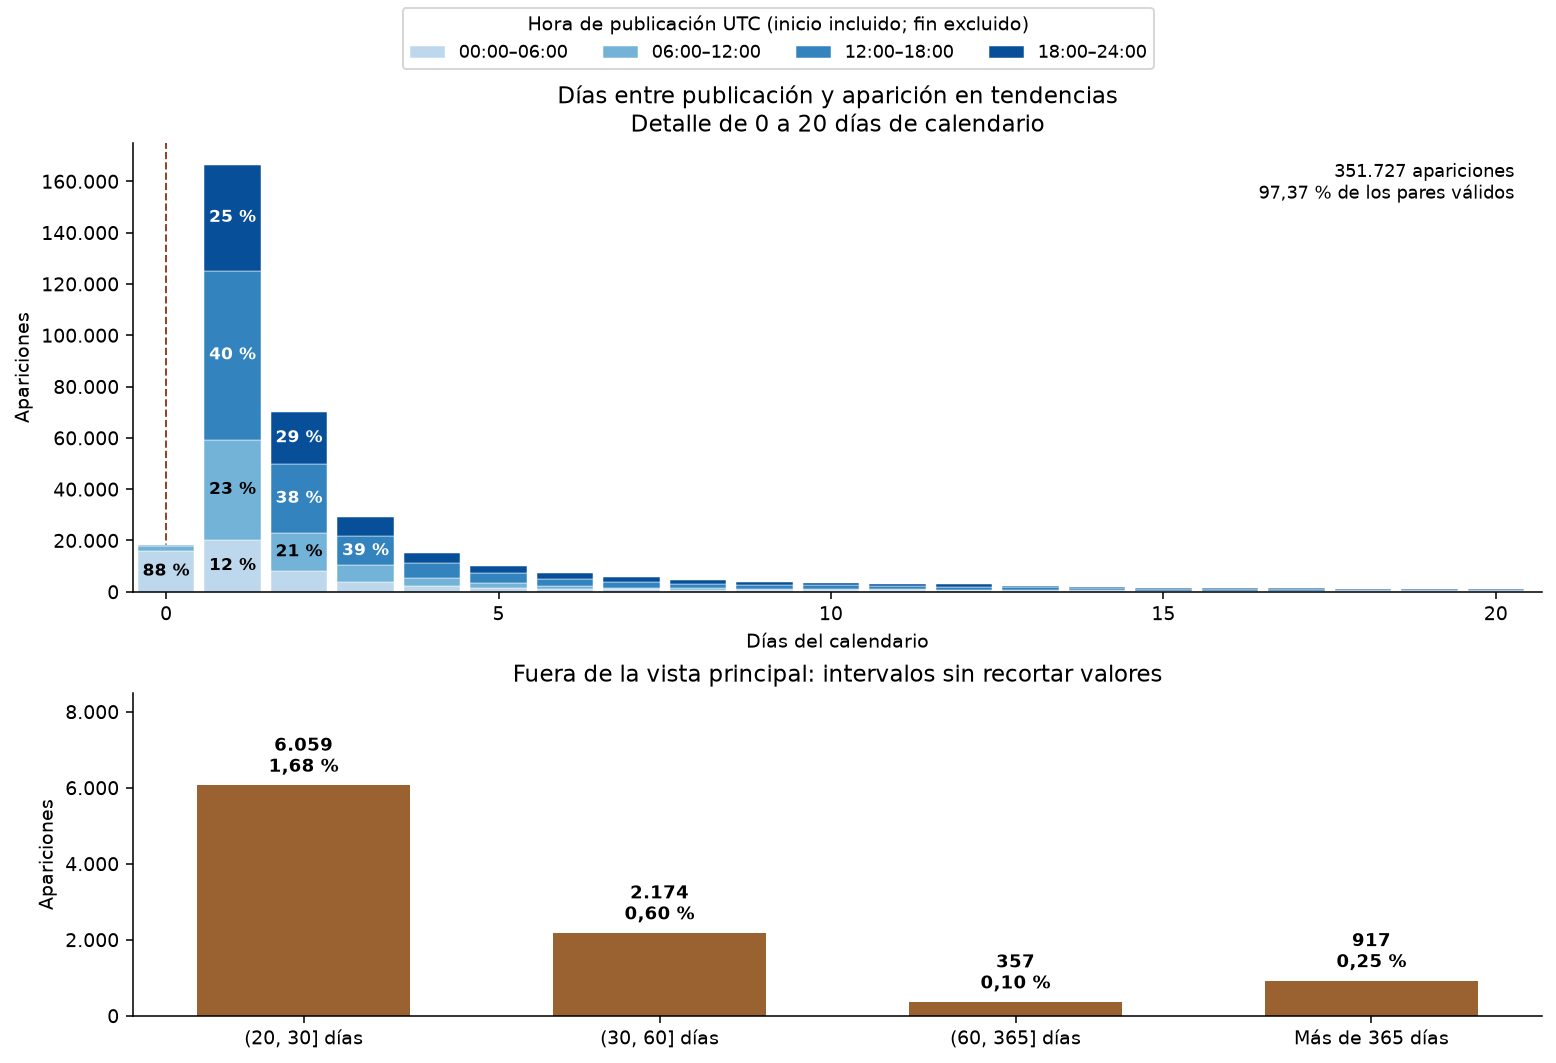

**Lectura del gráfico principal.** Cada barra superior cuenta apariciones con **0 a 20 días de calendario** entre publicación y tendencias. No se conoce la hora real de entrada en tendencias. Los valores fuera de la ventana se cuentan abajo y no se llevan al último día.

**Cobertura.** Arriba hay **351.727 de 361.234 apariciones comparables**, **97,37 %**. Por encima de 20 días: **9.507** (**2,63 %**). Por debajo de 0 días: **0**.

**Tonos de azul.** Representan la hora de publicación UTC en cuatro franjas: 00:00–06:00, 06:00–12:00, 12:00–18:00, 18:00–24:00. Se incluye el inicio y se excluye el final. La altura sigue contando apariciones; cada porcentaje se divide por el total de su barra diaria. Las etiquetas se redondean a enteros y se muestran donde caben. El desglose completo conserva los porcentajes con dos decimales.

**Lectura concreta.** En una de las barras de mayor volumen, el día **1**, la franja **12:00–18:00** reúne **65.895 de 166.509 apariciones**: **39,57 % de esa barra**. Describe el intervalo observado y no demuestra un horario óptimo de publicación.

**Cola inferior.** Forma parte del mismo conjunto de apariciones que la vista principal. Cada porcentaje se divide por todos los pares válidos, no sólo por los casos de la cola. El primer intervalo significa más de 20 días y hasta 30, incluido su extremo superior. El último reúne los valores superiores a 365 días; los originales no se recortan.

**Conclusión.** La vista principal permite estudiar la concentración inicial y la cola cuantifica las apariciones tardías sin ocultarlas. Son apariciones regionales y diarias, con vídeos repetidos, no tiempos hasta la primera entrada de vídeos únicos. Las franjas describen publicaciones UTC, no horas de entrada ni horas locales de los creadores.

<details><summary>Diagnóstico opcional: precisión de las fechas y negativos aparentes</summary>

**Qué comprueba este diagnóstico.** La lista de tendencias sólo registra el día. Representarlo a las 00:00 y restar la hora de publicación introduce fracciones de día y posibles negativos. La comparación comprueba esa precisión; no es otra distribución independiente del comportamiento de los vídeos.

| Comprobación | Diferencias negativas |
|---|---:|
| Resta con hora de publicación (A) | **18.106** |
| Diferencia por calendario, usada en el gráfico principal | **0** |

**Ejemplos conceptuales, no filas adicionales del dataset:**

| Publicación y lista de tendencias | Resta con hora | Calendario |
|---|---:|---:|
| Publicación el día 14 a las 18:00 UTC; lista del día 15 | 6 horas = 0,25 días | 1 día |
| Publicación el día 15 a las 16:00 UTC; lista del mismo día | -16 horas = -0,67 días | 0 días |

Al agrupar en intervalos de un día, las mismas apariciones cambian principalmente de posición entre las dos medidas; por eso no se presentan dos histogramas casi iguales. Los negativos de A no prueban que el vídeo entrara antes de publicarse. Para detectar una fecha de tendencias anterior al día de publicación se utiliza el calendario.

</details>

,Intervalo de días,Franja UTC,Apariciones,Porcentaje de la barra,Total de la barra
0,0,00:00–06:00,15.961,"87,74 %",18.191
1,0,06:00–12:00,1.825,"10,03 %",18.191
2,0,12:00–18:00,399,"2,19 %",18.191
3,0,18:00–24:00,6,"0,03 %",18.191
4,1,00:00–06:00,20.311,"12,20 %",166.509
5,1,06:00–12:00,39.018,"23,43 %",166.509
6,1,12:00–18:00,65.895,"39,57 %",166.509
7,1,18:00–24:00,41.285,"24,79 %",166.509
8,2,00:00–06:00,8.144,"11,61 %",70.127
9,2,06:00–12:00,14.761,"21,05 %",70.127


Se eliminaron **12.570 duplicados exactos** y **2.138 filas con marcadores de identidad inválidos**. Quedan **137 vídeos con varias categorías**. La fecha de tendencias se reserva para el análisis exploratorio.

In [2]:
# audit_labels: nombres legibles en español para las claves del registro de limpieza.
audit_labels = {
    'fallback_policy': 'Regla cuando falta una categoría en el JSON regional',
    'exact_duplicates_removed': 'Filas duplicadas eliminadas',
    'missing_keys_removed': 'Filas eliminadas por clave ausente',
    'invalid_identity_rows_removed': 'Filas eliminadas por identificador inválido',
    'nonstandard_ids_retained': 'Filas conservadas con identificador no estándar',
    'identity_policy': 'Regla para identificadores de vídeo',
    'videos_with_multiple_categories': 'Vídeos con varias categorías',
    'negative_exact_timestamp_delays': 'Diferencias negativas al comparar fecha y hora',
    'negative_calendar_day_delays': 'Diferencias negativas al comparar por día',
    'date_policy': 'Regla para interpretar las fechas',
    'output_rows': 'Filas del CSV final',
    'removed_exact_duplicates_or_missing_keys': 'Subtotal de duplicados y claves ausentes',
    'removed_total_rows': 'Total de filas eliminadas',
    'output_sha256': 'Huella SHA-256 del CSV final',
    'output_bytes': 'Tamaño del CSV final en bytes',
}
# audit_table: conserva la clave técnica y formatea los enteros para facilitar la lectura.
audit_table = pd.DataFrame([
    {
        'Campo técnico': key,
        'Descripción': audit_labels.get(key, key),
        'Valor': format_number(value, 0) if type(value) is int else value,
    }
    for key, value in audit.items() if not isinstance(value, dict)
]).set_index('Campo técnico')
# Mostrar las reglas y la huella completas en esta tabla.
with pd.option_context('display.max_colwidth', None):
    display(audit_table)
# La precisión horaria se explica en el diagnóstico opcional junto al gráfico principal.
# region_names: nombres de los países de los listados, a partir de sus códigos ISO de dos letras.
region_names = {
    'CA': 'Canadá', 'DE': 'Alemania', 'FR': 'Francia', 'GB': 'Reino Unido',
    'IN': 'India', 'JP': 'Japón', 'KR': 'Corea del Sur', 'MX': 'México',
    'RU': 'Rusia', 'US': 'Estados Unidos',
}
# regional_fields: claves del JSON y sus equivalentes para la lectura en español.
regional_fields = {
    'input_rows': 'Filas de entrada',
    'encoding': 'Codificación',
    'replacement_characters_in_source': 'Reemplazos ya presentes en origen',
    'replacement_characters_introduced': 'Reemplazos introducidos en la lectura',
}
# regional_audit: una fila por código del archivo regional.
regional_audit = pd.DataFrame.from_dict(audit['regions'], orient='index')[list(regional_fields)]
regional_audit.index.name = 'Código regional'
regional_audit.insert(0, 'country', [region_names.get(code, 'Sin identificar') for code in regional_audit.index])
regional_audit['input_rows'] = regional_audit['input_rows'].map(lambda value: format_number(value, 0))
regional_audit.columns = pd.MultiIndex.from_tuples([('country', 'País de la lista'), *regional_fields.items()])
display(regional_audit)
# replacements: sustituciones UTF-8 introducidas por la limpieza, sin sumar las preexistentes.
replacements=sum(item['replacement_characters_introduced'] for item in audit['regions'].values())
display(Markdown(
    'El **país de la lista** se identifica por el código del CSV de origen, como `CA` en `CAvideos.csv`. '
    'Los nombres se consultan en la [tabla de códigos ISO de dos letras](https://unstats.un.org/unsd/methodology/m49/overview/).\n\n'
    f'**Codificación.** Se conserva UTF-8 y se sustituyen {highlight_number(replacements)} secuencias inválidas puntuales. '
    'La tabla distingue los caracteres de reemplazo que ya estaban presentes en el archivo de los introducidos durante la lectura. '
    'La limpieza se limita a esas secuencias y conserva el resto del texto UTF-8.'
))
# missing_labels: nombres en español de las columnas del CSV unificado.
missing_labels = {
    'video_id': 'Identificador del vídeo',
    'trending_date': 'Fecha de aparición en tendencias',
    'title': 'Título',
    'channel_title': 'Nombre del canal',
    'publish_time': 'Fecha y hora de publicación',
    'tags': 'Etiquetas del vídeo',
    'views': 'Visualizaciones',
    'likes': 'Me gusta',
    'dislikes': 'No me gusta',
    'comment_count': 'Número de comentarios',
    'thumbnail_link': 'Enlace a la miniatura',
    'comments_disabled': 'Comentarios deshabilitados',
    'ratings_disabled': 'Valoraciones deshabilitadas',
    'video_error_or_removed': 'Vídeo con error o retirado',
    'description': 'Descripción',
    'category': 'Categoría editorial',
    'region': 'Región de la lista de tendencias',
}
# missing_counts: filas sin valor por columna, ordenadas de mayor a menor.
missing_counts = df.isna().sum().sort_values(ascending=False, kind='stable')
# missing_percent: cada recuento dividido por el total de filas y expresado en porcentaje.
missing_percent = 100 * (missing_counts / len(df)) if len(df) else missing_counts * 0.0
# missing_audit: tabla bilingüe. Un porcentaje positivo muy pequeño se distingue de cero.
missing_audit = pd.DataFrame({
    ('field_label', 'Descripción'): missing_counts.index.map(lambda field: missing_labels.get(field, 'Sin traducción')),
    ('missing_rows', 'Filas sin valor'): missing_counts.map(lambda count: format_number(count, 0)),
    ('missing_fraction', 'Fracción ausente (%)'): missing_percent.map(
        lambda percent: '<0,01 %' if 0 < percent < 0.01 else f'{format_number(percent, 2)} %'
    ),
})
missing_audit.index.name = 'Campo técnico del CSV'
display(missing_audit)
# missing_note: explica el denominador y toma como ejemplo la columna con más ausencias.
missing_note = (
    '**Cómo leer la tabla.** Para cada columna, se divide el número de filas sin valor '
    'entre el total de filas del CSV procesado. Cada fila corresponde a una aparición en tendencias.'
)
if not len(df):
    missing_note = '**Cómo leer la tabla.** El CSV no tiene filas; no se puede calcular la fracción ausente.'
elif not missing_counts.empty and missing_counts.iloc[0] > 0:
    most_missing = missing_counts.index[0]
    shown_percent = missing_audit.loc[most_missing, ('missing_fraction', 'Fracción ausente (%)')]
    missing_note += (
        f' El campo con más ausencias es **{missing_labels.get(most_missing, most_missing)}** '
        f'con {highlight_number(missing_counts.iloc[0])} de {highlight_number(len(df))} filas '
        f'(**{shown_percent}**).'
    )
else:
    missing_note += ' En este CSV, todas las columnas tienen valores presentes en todas las filas.'
display(Markdown(missing_note))
# publish: publicación convertida a UTC (Tiempo Universal Coordinado) para comparar fechas coherentemente.
publish=pd.to_datetime(df.publish_time,utc=True,errors='coerce')
# trend: día de tendencia convertido a UTC, sin inventar una hora regional.
trend=pd.to_datetime(df.trending_date,utc=True,errors='coerce')
# date_valid: pares comparables; NaT se excluye sólo de los gráficos temporales.
date_valid = publish.notna() & trend.notna()
if not date_valid.any():
    raise ValueError('No hay pares de fechas válidas para los histogramas. Revisa publish_time y trending_date en el CSV procesado y su auditoría.')
display(Markdown(
    f'**Fechas comparables:** {highlight_number(date_valid.sum())} de {highlight_number(len(df))} apariciones. '
    f'Publicaciones sin fecha válida: {highlight_number(publish.isna().sum())}; '
    f'tendencias sin fecha válida: {highlight_number(trend.isna().sum())}. '
    f'Las {highlight_number((~date_valid).sum())} filas sin el par completo se excluyen sólo de estos histogramas, '
    'sin eliminarlas de la tabla principal de datos (`df`). Los recuentos de diferencias negativas se interpretan entre los pares comparables.\n\nLas horas se expresan en **UTC (Tiempo Universal Coordinado)**, la referencia horaria común para comparar los vídeos; no son las horas locales de cada región.'
))
# delay: diferencia temporal en días, conservando la hora de publicación.
delay=(trend-publish).dt.total_seconds()/86400
# calendar: retraso por día normalizado, distinto del retraso horario.
calendar=(trend.dt.normalize()-publish.dt.normalize()).dt.days
# notebook_helpers y results_report: detalle temporal y cola sin recortar los datos.
from notebook_helpers import draw_date_views, show_narrative_details
from results_report import date_views_summary, date_diagnostic_summary
# date_views: recuentos y denominadores de las dos medidas temporales.
date_views = draw_date_views(delay, calendar, cutoff=20, publication_hours=publish.dt.hour)
show('eda_dates')
display(Markdown(date_views_summary(date_views)))
# Diagnóstico opcional: explica los negativos sin duplicar la figura principal.
show_narrative_details('Diagnóstico opcional: precisión de las fechas y negativos aparentes',
                       date_diagnostic_summary(date_views))
# Desglose completo por intervalo y franja: el porcentaje usa el total de cada barra.
for panel in date_views['panels']:
    if panel.get('hour_rows'):
        hour_view = pd.DataFrame(panel['hour_rows'])
        hour_view['Porcentaje de la barra'] = hour_view['Porcentaje de la barra'].map(lambda value:format_number(value,2)+' %')
        show_details('Desglose de publicaciones UTC por día del calendario',hour_view)


display(Markdown(
    f"Se eliminaron **{format_number(audit['exact_duplicates_removed'], 0)} duplicados exactos** "
    f"y **{format_number(audit['invalid_identity_rows_removed'], 0)} filas con marcadores de identidad inválidos**. "
    f"Quedan **{format_number(audit['videos_with_multiple_categories'], 0)} vídeos con varias categorías**. "
    "La fecha de tendencias se reserva para el análisis exploratorio."
))


## 2. Composición y representatividad

**Macro-F1.** Para cada categoría, F1 combina la proporción de predicciones correctas de esa categoría y la proporción de sus casos reales que se detectan. Macro-F1 promedia esos resultados dando el mismo peso a cada categoría, incluidas las menos frecuentes.

Se comparan frecuencias de apariciones y vídeos únicos. Un vídeo repetido puede pesar mucho en las primeras; confundir ambas unidades sesgaría conclusiones sobre géneros y países.

**Unidad y soporte.** Una fila es una aparición en tendencias. Un vídeo único se cuenta por ID. En evaluación, el soporte cuenta los ejemplos reales que tiene una clase.

**Fracción de apariciones: proporción de todos los registros que corresponde a cada región.** Se calcula dividiendo las apariciones de una región entre las apariciones de todo el conjunto. Una aparición es un vídeo incluido en una lista regional de tendencias en un día concreto. Si el mismo vídeo aparece durante **tres días** en esa región, aporta **tres apariciones**. Se cuentan registros, con sus repeticiones. Una fracción se convierte en porcentaje multiplicándola por **100**.

**MAE (error absoluto medio).** Es el promedio de las distancias entre las estimaciones numéricas del modelo y los valores reales. Los errores por exceso y por defecto se cuentan como distancias positivas y no se compensan. Se expresa en las mismas unidades que el objetivo: al estimar likes, son «me gusta». **Cuanto menor sea el MAE, mejor; 0 indica que no hay error en los casos evaluados.**

<details><summary>Ejemplos sencillos para interpretar estas medidas</summary>

**Ejemplos ilustrativos; no son resultados de la práctica.**

- **Proporción de apariciones:** si Canadá reúne **250** de **1.000** registros, su fracción es **250 ÷ 1.000 = 0,25**, equivalente al **25 %**.
- **MAE:** si un vídeo tiene **100** «me gusta» y se estiman **80**, el error es **20**. Si otro tiene **200** y se estiman **230**, el error es **30**. El promedio es **(20 + 30) ÷ 2 = 25 me gusta**. Ese promedio no garantiza que cada estimación se equivoque exactamente en esa cantidad.

</details>


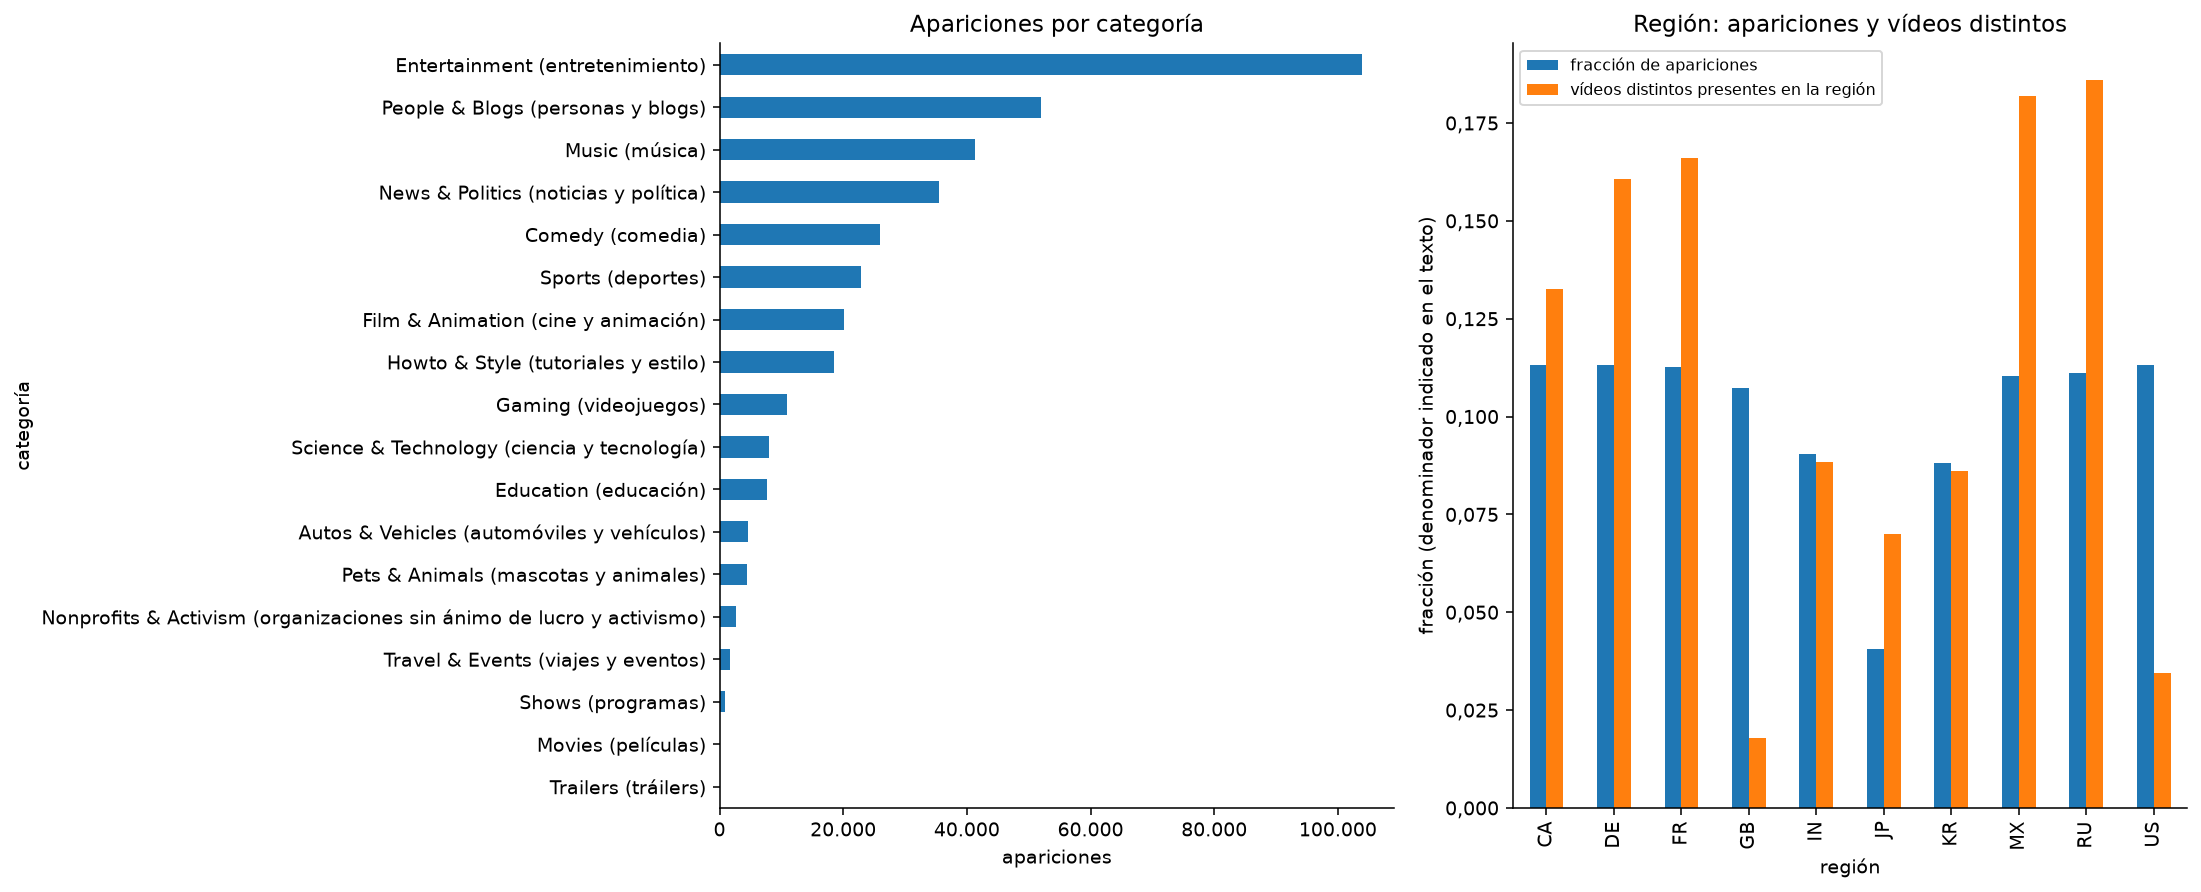

**Entertainment (entretenimiento) concentra el 28,8 %** de las apariciones. La categoría menos frecuente tiene **5** registros. **Conclusión.** La exactitud global puede ocultar errores en las categorías con menos ejemplos. Por ello se informa macro-F1 y el número de casos reales de cada clase. Hay **1,96** apariciones por vídeo en promedio. Para evitar que un mismo vídeo aparezca en ajuste y prueba, las particiones agrupan sus apariciones por identificador. El panel regional cuenta los vídeos presentes en cada lista de tendencias.

region,CA,DE,FR,GB,IN,JP,KR,MX,RU,US
category,,,,,,,,,,
Autos & Vehicles (automóviles y vehículos),"0,009","0,021","0,017","0,004","0,002","0,015","0,004","0,006","0,039","0,009"
Comedy (comedia),"0,092","0,062","0,107","0,047","0,09","0,034","0,058","0,043","0,075","0,084"
Education (educación),"0,024","0,021","0,019","0,012","0,035","0,006","0,014","0,013","0,017","0,04"
Entertainment (entretenimiento),"0,329","0,374","0,241","0,234","0,446","0,3","0,26","0,333","0,146","0,243"
Film & Animation (cine y animación),"0,05","0,058","0,053","0,066","0,044","0,059","0,063","0,032","0,074","0,057"
Gaming (videojuegos),"0,033","0,038","0,036","0,046","0,002","0,048","0,04","0,024","0,026","0,02"
Howto & Style (tutoriales y estilo),"0,049","0,043","0,058","0,05","0,024","0,039","0,016","0,061","0,049","0,101"
Movies (películas),0,0,0,0,0,0,0,0,0,0
Music (música),"0,091","0,058","0,097","0,354","0,099","0,064","0,054","0,083","0,047","0,158"


,fracción de apariciones,vídeos distintos presentes en la región
region,,
CA,"0,11317","0,132549"
DE,"0,113057","0,160766"
FR,"0,112736","0,165943"
GB,"0,107257","0,017755"
IN,"0,090376","0,088482"
JP,"0,040528","0,07006"
KR,"0,088134","0,086143"
MX,"0,110416","0,181848"
RU,"0,1111","0,186021"


**Cobertura regional:** **13.768** de **184.286** vídeos aparecen en varias regiones. La suma regional es **207.143** pertenencias vídeo-región. En la tabla de categorías cada columna representa una región y sus fracciones suman aproximadamente 1 por el redondeo. En el gráfico regional, la primera serie divide las apariciones de la región por todas las apariciones. La segunda divide sus vídeos distintos por todos los vídeos únicos del conjunto. Como un vídeo puede aparecer en varias listas, estas fracciones regionales de vídeos no son cuotas exclusivas.

**Conclusión del cruce categoría × región.** Categoría dominante en cada lista:

CA (Canadá): Entertainment (entretenimiento), **32,90 %** de sus apariciones.

DE (Alemania): Entertainment (entretenimiento), **37,44 %** de sus apariciones.

FR (Francia): Entertainment (entretenimiento), **24,11 %** de sus apariciones.

GB (Reino Unido): Music (música), **35,36 %** de sus apariciones.

IN (India): Entertainment (entretenimiento), **44,56 %** de sus apariciones.

JP (Japón): Entertainment (entretenimiento), **30,00 %** de sus apariciones.

KR (Corea del Sur): Entertainment (entretenimiento), **26,00 %** de sus apariciones.

MX (México): Entertainment (entretenimiento), **33,32 %** de sus apariciones.

RU (Rusia): People & Blogs (personas y blogs), **25,44 %** de sus apariciones.

US (Estados Unidos): Entertainment (entretenimiento), **24,31 %** de sus apariciones.

La mezcla editorial varía entre listas regionales. Incluir region permite al modelo representar esas diferencias observadas; su aportación incremental sólo se demostraría comparando con una ablación sin ese atributo.

**Repetición regional.** GB (Reino Unido) registra **11,84** apariciones por vídeo, frente a **1,13** en JP (Japón). Una lista con más repetición da más peso a las mismas identidades en las métricas por aparición. Esto ayuda a interpretar los errores regionales, pero no demuestra por sí solo por qué cambia el MAE (error absoluto medio). Las regiones identifican listas de tendencias, no la nacionalidad de los creadores.

In [3]:
# unique: una fila por vídeo para no ponderar apariciones repetidas.
unique=df.drop_duplicates('video_id')
# fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos y
# unidades explícitos.
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
# top: frecuencias de categorías para contextualizar el desbalance.
top = df.category.value_counts()
top.sort_values().rename(index=category_label).plot.barh(ax=ax[0], title='Apariciones por categoría')
# regional_videos: vídeos distintos presentes en cada región, sin asignarlos por orden de lectura.
regional_videos = df.groupby('region').video_id.nunique().sort_index()
# regional_composition: fracciones con denominadores explícitos y cobertura multirregión declarada.
regional_composition = pd.DataFrame({
    'fracción de apariciones': df.region.value_counts(normalize=True),
    'vídeos distintos presentes en la región': regional_videos / df.video_id.nunique()
}).sort_index()
regional_composition.plot.bar(ax=ax[1],title='Región: apariciones y vídeos distintos')
ax[0].set(xlabel='apariciones', ylabel='categoría')
ax[1].set(xlabel='región', ylabel='fracción (denominador indicado en el texto)')
ax[1].legend(loc='upper left', fontsize=8)
show('eda_composition')
display(Markdown(
    f'**{category_label(top.index[0])} concentra el {format_number(100 * top.iloc[0] / len(df), 1)} %** '
    f'de las apariciones. La categoría menos frecuente tiene {highlight_number(top.iloc[-1])} registros. '
    '**Conclusión.** La exactitud global puede ocultar errores en las categorías con menos ejemplos. '
    'Por ello se informa macro-F1 y el número de casos reales de cada clase. '
    f'Hay {highlight_number(len(df) / len(unique), 2)} apariciones por vídeo en promedio. '
    'Para evitar que un mismo vídeo aparezca en ajuste y prueba, las particiones agrupan sus apariciones por identificador. '
    'El panel regional cuenta los vídeos presentes en cada lista de tendencias.'
))
# category_by_region: cada columna representa el reparto de apariciones dentro de una región.
category_by_region = pd.crosstab(df.region, df.category, normalize='index').T
display(category_by_region.round(3).rename(index=category_label))

# multiregion_videos: vídeos cuyo identificador aparece en varias regiones.
multiregion_videos = int(df.groupby('video_id').region.nunique().gt(1).sum())
display(regional_composition)
display(Markdown(
    f'**Cobertura regional:** {highlight_number(multiregion_videos)} de {highlight_number(df.video_id.nunique())} vídeos '
    f'aparecen en varias regiones. La suma regional es {highlight_number(regional_videos.sum())} '
    'pertenencias vídeo-región. En la tabla de categorías cada columna representa una región '
    'y sus fracciones suman aproximadamente 1 por el redondeo. En el gráfico regional, '
    'la primera serie divide las apariciones de la región por todas las apariciones. '
    'La segunda divide sus vídeos distintos por todos los vídeos únicos del conjunto. '
    'Como un vídeo puede aparecer en varias listas, estas fracciones regionales de vídeos no son cuotas exclusivas.'
))

# results_report: interpreta composición editorial y repetición regional desde los datos.
from results_report import regional_composition_summary
display(Markdown(category_notes(regional_composition_summary(df, category_by_region, region_names=region_names))))


## 3. Magnitudes, colas largas y moderación

**RMSE (raíz del error cuadrático medio).** Resume el tamaño de los errores numéricos dando más peso a los grandes que el MAE. Se expresa en las unidades del objetivo, como el número de «me gusta».

Los extremos no se eliminan porque sean grandes. Se comparan objetivos original y logarítmico mediante **validación cruzada (CV)**: se alterna qué parte de los datos se usa para ajustar el modelo y qué parte se reserva para comprobarlo. Las tasas de moderación deben leerse junto al soporte positivo.

**Escala de los valores: funciones de NumPy.** `np.log1p()` y `np.expm1()` son **funciones matemáticas de NumPy**, la biblioteca utilizada para los cálculos numéricos. `np` es su nombre abreviado en el código; `x` y `z` representan los valores que reciben las funciones, y los paréntesis indican que se está llamando a una función.

- **`np.log1p(x)`** calcula el logaritmo natural de **1 + x**. Comprime las diferencias entre valores pequeños y grandes; sumar **1** permite transformar también el cero, cuyo resultado sigue siendo **0**.
- **`np.expm1(z)`** realiza la operación inversa: devuelve el valor de la escala logarítmica a sus unidades originales.

**Ejemplo ilustrativo, no un resultado de la práctica.** `np.log1p(99)` produce aproximadamente **4,605**. Al aplicar `np.expm1()` al resultado completo, sin redondearlo antes, se recupera aproximadamente **99**. La expresión `np.expm1(np.log1p(99))` muestra las dos operaciones encadenadas.

En las alternativas de regresión que transforman el objetivo, el modelo aprende sobre los valores obtenidos con `log1p` y `expm1` devuelve las predicciones a la escala original; por ejemplo, al número de «me gusta». Una **cola larga** indica que unas pocas apariciones alcanzan valores muy altos. Estas funciones ayudan a trabajar con esa escala, sin eliminar los registros grandes.

**Cómo leer la tabla de cuantiles.** Cada fila es un contador distinto. Las columnas resumen posiciones al ordenar sus valores de menor a mayor; esas posiciones se llaman **cuantiles**:

- **0 — mínimo:** el valor más pequeño observado.
- **0,5 — mediana o percentil 50 (P50):** el valor central; aproximadamente la mitad de las apariciones queda a cada lado.
- **0,9 — percentil 90:** umbral por debajo del cual queda aproximadamente el **90 %** de las apariciones; el resto ocupa la parte superior.
- **0,99 — percentil 99:** umbral por debajo del cual queda aproximadamente el **99 %** de las apariciones.
- **1 — máximo:** el valor más grande observado.

Estas posiciones se calculan por contador y cuentan apariciones, con las repeticiones del mismo vídeo. Los porcentajes son orientativos al leer los umbrales: los empates pueden concentrar muchas filas en un mismo valor.


,Mínimo (0),"Mediana · P50 (0,5)","Percentil 90 (0,9)","Percentil 99 (0,99)",Máximo (1)
views (visualizaciones),117,"177.042,5","2.129.542,1",20.771.856,424.538.912
likes (me gusta),0,3.540,72.670,"595.420,61",5.613.827
dislikes (no me gusta),0,180,2.832,31.434,1.944.971
comment_count (número de comentarios),0,520,7.501,"59.328,09",1.626.501


**Ejemplo con los datos de esta tabla.** En likes (me gusta), la mediana es **3.540,00**: aproximadamente la mitad de las apariciones queda a cada lado. El percentil 99 es **595.420,61**: aproximadamente el **99 %** de las apariciones queda por debajo de ese umbral. **Por qué aparecen decimales.** pandas puede interpolar linealmente entre dos valores ordenados para calcular un cuantil. El resultado es un umbral estadístico; no significa que un registro tenga una fracción de «me gusta».

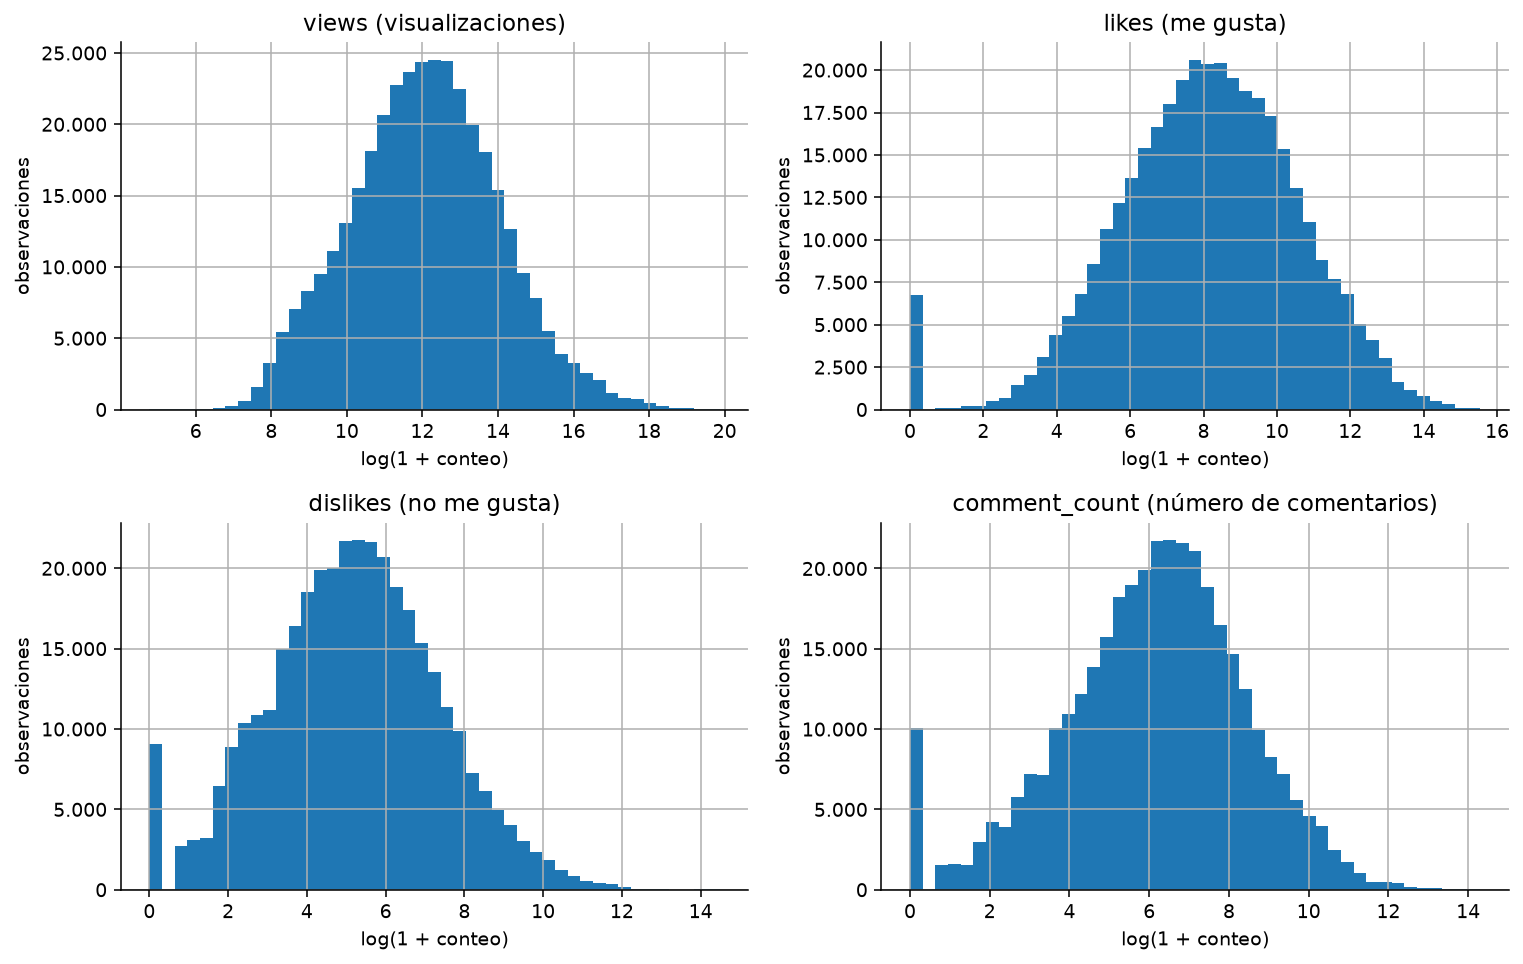

**Magnitudes y distribución.** La tabla usa los recuentos originales. Los histogramas comprimen los extremos con log(1 + conteo) y conservan los ceros. En el número de likes (me gusta) por aparición, la mediana es **3.540**, el percentil 99 es **595.421** (redondeado) y el máximo alcanza **5.613.827 me gusta**. Se informa MAE para leer el tamaño medio del error y RMSE para dar más peso a los errores grandes. En la proporción likes/dislikes, **2,51 %** de las apariciones tienen denominador cero y quedan fuera de esa tarea.

**Spearman (medida de asociación basada en el orden de los valores).** Ordena los valores de cada contador y compara sus posiciones: si las apariciones con más «me gusta» suelen tener también más comentarios, la asociación es positiva.

- **+1:** el orden de los valores coincide perfectamente.
- **−1:** el orden es perfectamente inverso: al aumentar uno, el otro disminuye.
- **Cerca de 0:** hay poca asociación basada en ese orden; aún podrían existir otras relaciones.

Cuanto más cerca esté el valor de **+1** o de **−1**, más marcada es esa asociación de orden. **El coeficiente no es un porcentaje de aciertos y no demuestra causalidad.** Las comparaciones cuentan apariciones, con las repeticiones de un mismo vídeo.


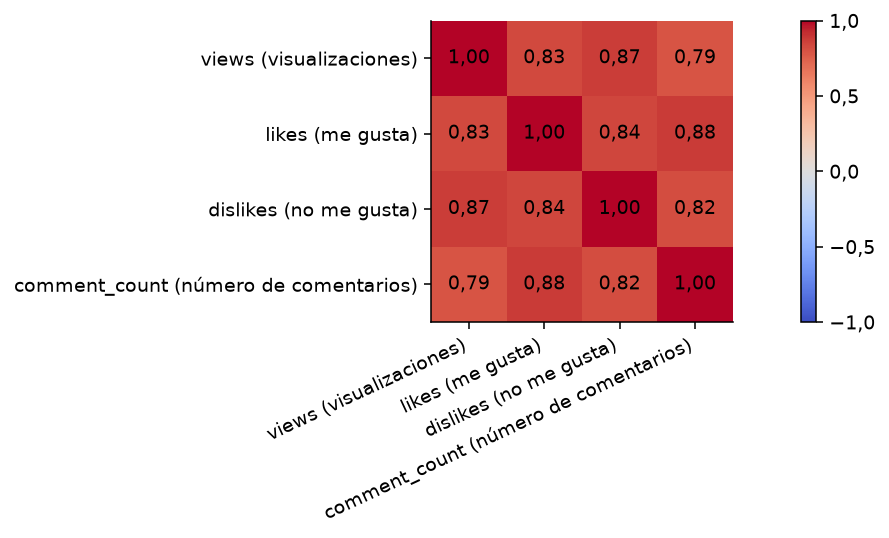

**Asociación entre contadores.** La mayor asociación por magnitud se observa entre **likes (me gusta)** y **comment_count (número de comentarios)** (coeficiente de Spearman **0,88**). La asociación es positiva: los valores altos de ambos contadores tienden a aparecer juntos. Estos contadores pueden aumentar con la exposición del mismo vídeo. La matriz no permite atribuir causalidad.

**Cómo leer el gráfico regional.** Cada barra muestra el porcentaje de apariciones de esa región con comentarios o valoraciones desactivados: apariciones con la desactivación divididas entre todas las apariciones de la misma región, multiplicado por **100**. Las dos barras son medidas separadas y no tienen que sumar **100 %**. Los porcentajes globales del texto posterior usan todas las apariciones del conjunto; las barras usan las de cada región.

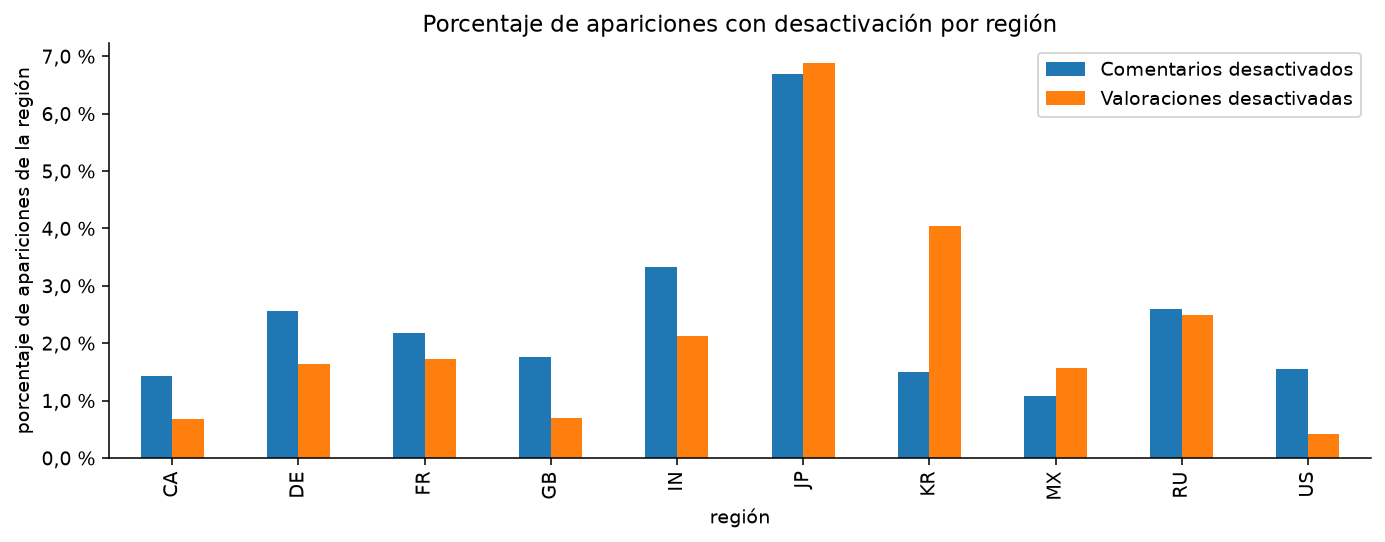

**Desactivación.** En el conjunto completo, los comentarios se desactivan en **2,17 %** de las apariciones y las valoraciones en **1,86 %**. Un clasificador que siempre prediga la opción habitual puede acertar muchas filas y pasar por alto las desactivaciones. Por eso se informa cuántos positivos reales se detectan.

In [4]:
# counts: nombres de las cuatro columnas de contadores del vídeo para este análisis.
counts = ['views', 'likes', 'dislikes', 'comment_count']
# count_labels: nombres del CSV y su significado para leer tablas y ejes.
count_labels = {'views': 'views (visualizaciones)', 'likes': 'likes (me gusta)',
                'dislikes': 'dislikes (no me gusta)', 'comment_count': 'comment_count (número de comentarios)'}
# quantiles: resumen numérico en la escala original de los contadores.
quantiles = df[counts].quantile([0, .5, .9, .99, 1]).T
# quantile_labels: conserva la posición técnica y explica qué representa cada columna.
quantile_labels = {0: 'Mínimo (0)', 0.5: 'Mediana · P50 (0,5)', 0.9: 'Percentil 90 (0,9)', 0.99: 'Percentil 99 (0,99)', 1: 'Máximo (1)'}
display(quantiles.rename(index=count_labels, columns=quantile_labels))
display(Markdown(
    '**Ejemplo con los datos de esta tabla.** En likes (me gusta), la mediana es '
    f'{highlight_number(quantiles.loc["likes", .5], 2)}: aproximadamente la mitad de las apariciones queda a cada lado. '
    f'El percentil 99 es {highlight_number(quantiles.loc["likes", .99], 2)}: aproximadamente el **99 %** '
    'de las apariciones queda por debajo de ese umbral. '
    '**Por qué aparecen decimales.** pandas puede interpolar linealmente entre dos valores ordenados '
    'para calcular un cuantil. El resultado es un umbral estadístico; no significa que un registro tenga una fracción de «me gusta».'
))
# axes: conjunto de ejes de histogramas.
axes = np.log1p(df[counts]).rename(columns=count_labels).hist(bins=45, figsize=(11, 7))
for axis in axes.ravel():
    axis.set(xlabel='log(1 + conteo)',ylabel='observaciones')
show('eda_counter_distributions')
display(Markdown(
    '**Magnitudes y distribución.** La tabla usa los recuentos originales. Los histogramas comprimen '
    'los extremos con log(1 + conteo) y conservan los ceros. En el número de likes (me gusta) por aparición, la mediana es '
    f'{highlight_number(quantiles.loc["likes", .5])}, el percentil 99 es '
    f'{highlight_number(quantiles.loc["likes", .99])} (redondeado) y el máximo alcanza {highlight_number(quantiles.loc["likes", 1], suffix=" me gusta")}. '
    'Se informa MAE para leer el tamaño medio del error y RMSE para dar más peso a los errores grandes. '
    f'En la proporción likes/dislikes, {highlight_number(100 * df.dislikes.eq(0).mean(), 2, " %")} '
    'de las apariciones tienen denominador cero y quedan fuera de esa tarea.'
))
# corr: Spearman (asociación entre el orden de los valores), descriptiva y no causal.
display(Markdown('**Spearman (medida de asociación basada en el orden de los valores).** Ordena los valores de cada contador y compara sus posiciones: si las apariciones con más «me gusta» suelen tener también más comentarios, la asociación es positiva.\n\n- **+1:** el orden de los valores coincide perfectamente.\n- **−1:** el orden es perfectamente inverso: al aumentar uno, el otro disminuye.\n- **Cerca de 0:** hay poca asociación basada en ese orden; aún podrían existir otras relaciones.\n\nCuanto más cerca esté el valor de **+1** o de **−1**, más marcada es esa asociación de orden. **El coeficiente no es un porcentaje de aciertos y no demuestra causalidad.** Las comparaciones cuentan apariciones, con las repeticiones de un mismo vídeo.\n'))
corr=df[counts].corr(method='spearman')
# fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos y
# unidades explícitos.
# im: imagen de calor usada para mostrar la matriz numérica.
fig,ax=plt.subplots()
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(counts)), list(count_labels.values()), rotation=25, ha='right')
ax.set_yticks(range(len(counts)), list(count_labels.values()))
for i in range(4):
    for j in range(4):
        ax.text(j,i,f'{format_number(corr.iloc[i,j], 2)}',ha='center',va='center')
fig.colorbar(im,ax=ax)
show('eda_correlations')
# pair_corr: se conserva un valor por pareja y se excluye la diagonal de autocorrelaciones.
pair_corr = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
if not pair_corr.empty:
    first_count, second_count = pair_corr.abs().idxmax()
    # correlation_value: asociación observada para la pareja seleccionada, sin recalcularla.
    correlation_value = pair_corr.loc[(first_count, second_count)]
    # association_direction: interpreta el signo real, también si cambia con otros datos.
    association_direction = (
        'La asociación es positiva: los valores altos de ambos contadores tienden a aparecer juntos.'
        if correlation_value > 0 else
        'La asociación es negativa: los valores altos de uno tienden a acompañarse de valores bajos del otro.'
        if correlation_value < 0 else
        'El coeficiente es cero: no se observa asociación de orden en esta pareja.'
    )
    display(Markdown(
        '**Asociación entre contadores.** La mayor asociación por magnitud se observa entre '
        f'**{count_labels[first_count]}** y **{count_labels[second_count]}** '
        f'(coeficiente de Spearman {highlight_number(correlation_value, 2)}). '
        + association_direction + ' '
        'Estos contadores pueden aumentar con la exposición del mismo vídeo. La matriz no permite atribuir causalidad.'
    ))
# moderation_labels: traducción de las dos señales de desactivación.
moderation_labels = {'comments_disabled': 'Comentarios desactivados',
                     'ratings_disabled': 'Valoraciones desactivadas'}
rates = df.groupby('region')[list(moderation_labels)].mean()
# matplotlib.ticker: expresa las tasas de 0 a 1 como porcentajes en el eje.
from matplotlib.ticker import PercentFormatter
# moderation_axis: cambia las etiquetas del eje, manteniendo las alturas originales.
moderation_axis = rates.rename(columns=moderation_labels).plot.bar(
    title='Porcentaje de apariciones con desactivación por región')
moderation_axis.set(xlabel='región', ylabel='porcentaje de apariciones de la región')
moderation_axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
display(Markdown('**Cómo leer el gráfico regional.** Cada barra muestra el porcentaje de apariciones de esa región con comentarios o valoraciones desactivados: apariciones con la desactivación divididas entre todas las apariciones de la misma región, multiplicado por **100**. Las dos barras son medidas separadas y no tienen que sumar **100 %**. Los porcentajes globales del texto posterior usan todas las apariciones del conjunto; las barras usan las de cada región.'))
show('eda_moderation')
display(Markdown(
    f'**Desactivación.** En el conjunto completo, los comentarios se desactivan en '
    f'{highlight_number(100 * df.comments_disabled.mean(), 2, " %")} de las apariciones y las valoraciones en '
    f'{highlight_number(100 * df.ratings_disabled.mean(), 2, " %")}. '
    'Un clasificador que siempre prediga la opción habitual puede acertar muchas filas y pasar por alto '
    'las desactivaciones. Por eso se informa cuántos positivos reales se detectan.'
))


## 4. Tiempo, contenido y concentración de canales

La cobertura temporal no demuestra estacionalidad anual. Los canales pueden aparecer en ambos lados aunque sus vídeos no: se declara esta limitación y se evita usar su ID como predictor.

**Asociación temporal y de magnitudes.** Spearman compara el orden de los valores y ayuda a ver si dos magnitudes tienden a subir o bajar juntas. Los percentiles resumen posiciones dentro de cada distribución.


**Identificación de los canales del gráfico.** La tabla siguiente relaciona los **15** códigos del panel derecho con el nombre del canal y su número de vídeos únicos. Son etiquetas asignadas aquí para facilitar la lectura, no los identificadores originales de YouTube. Consulta la columna **canal** para saber a qué nombre corresponde cada código.

código,canal,vídeos
C01,SET India,253
C02,SAB TV,248
C03,VikatanTV,240
C04,Анатолий Шарий,235
C05,The Late Show with Stephen Colbert,230
C06,Elhiwar Ettounsi,212
C07,WWE,202
C08,Россия 24,194
C09,ESPN,185
C10,CNN,179


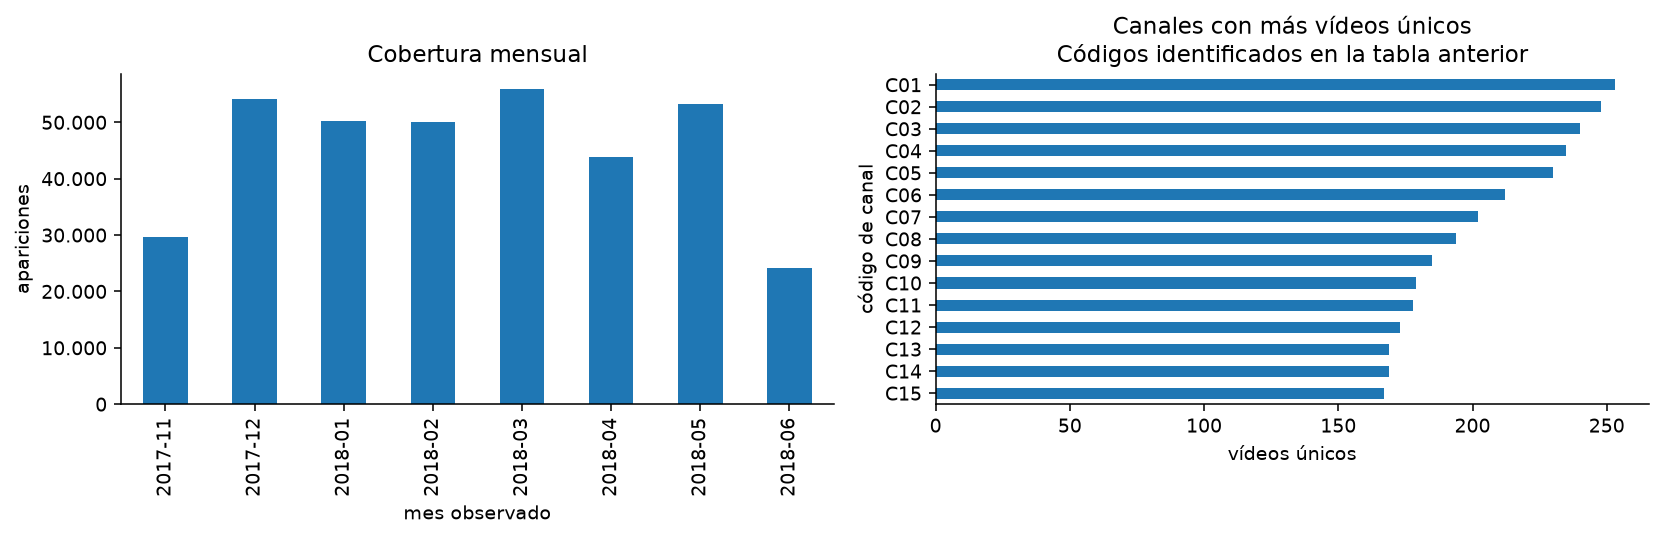

Los **15 nombres de canal** más frecuentes reúnen **3.034 de 184.286 vídeos únicos** (**1,65 %**). Fechas de tendencia inválidas o ausentes: **0 de 361.234 apariciones**. Nombres de canal ausentes: **0 de 184.286 vídeos únicos**. Los nombres ausentes no se incluyen en el listado ordenado; las fechas ausentes no se incluyen en las barras mensuales. La cobertura abarca **8** meses con datos. El gráfico muestra el volumen de la muestra histórica disponible. Para estudiar estacionalidad anual haría falta una cobertura temporal más amplia.

,filas,mediana_vistas,mediana_likes
category,,,
Music (música),41.299,938.269,39.000
Movies (películas),30,553.851,"15.679,5"
Comedy (comedia),25.940,346.951,"13.215,5"
Science & Technology (ciencia y tecnología),8.034,"316.858,5",12.147
Gaming (videojuegos),10.986,163.308,"6.618,5"
Howto & Style (tutoriales y estilo),18.480,123.742,5.046
Travel & Events (viajes y eventos),1.719,164.227,4.921
Education (educación),7.644,"96.917,5","3.764,5"
Pets & Animals (mascotas y animales),4.500,"114.562,5","3.749,5"


La tabla reúne **18 categorías** y **361.234 apariciones**. El soporte por categoría va de **5** a **103.916 filas**. Categorías con menos de 30 apariciones: **1** (umbral descriptivo, no garantía de fiabilidad estadística). Cada mediana se calcula dentro de su categoría y omite valores ausentes; las filas cuentan apariciones, no vídeos únicos. La mediana más alta de likes (me gusta) corresponde a **Music (música)** (**39.000,0**, sobre **41.299** apariciones). La comparación debe leerse junto al tamaño de cada categoría y no permite atribuir causalidad.

incidencia,apariciones,porcentaje del total
Descripción ausente (NaN),18.518,"5,13 %"
Descripción sólo con espacios,16,"<0,01 %"
Etiquetas ausentes (NaN),0,"0,00 %"
"Etiquetas vacías o sólo espacios, no NaN",0,"0,00 %"
Etiquetas con marcador [none],35.936,"9,95 %"


**Cobertura observada:** 2017-11-14 → 2018-06-14. **Descripciones sin texto:** **18.534** de **361.234** apariciones. **Etiquetas sin contenido declarado (ausentes, vacías o [none]):** **35.936** de **361.234**. Los porcentajes de la tabla usan como denominador todas las apariciones. Una fila puede tener incidencias en ambos campos: no se suman sus porcentajes para obtener una tasa conjunta. La comprobación de espacios y mayúsculas se hace en copias para este diagnóstico; no modifica los textos originales. Se admite texto parcial: la falta de descripción no obliga a descartar un vídeo que conserve otros campos utilizables. No se inventa texto ni se interpreta su longitud como causa de éxito. [none] se cuenta aquí como marcador de etiquetas, no como prueba de que cualquier otro texto sea informativo.

In [5]:
# fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos y
# unidades explícitos.
fig,ax=plt.subplots(1,2,figsize=(12,4))
# monthly_trending: apariciones agrupadas por mes observado.
monthly_trending = trend.dt.strftime('%Y-%m').value_counts().sort_index()
monthly_trending.plot.bar(ax=ax[0], title='Cobertura mensual')
ax[0].set(xlabel='mes observado',ylabel='apariciones')
# channels: los quince nombres de canal con más vídeos únicos en la tabla deduplicada.
channels=unique.channel_title.value_counts().head(15)
# channel_codes: códigos cortos vinculados a los nombres completos en la tabla.
channel_codes=[f'C{i:02}' for i in range(1,len(channels)+1)]
# notebook_helpers: presenta cifras en español y permite omitir el índice auxiliar.
from notebook_helpers import spanish_table_html
# channel_table: correspondencia explícita entre código, nombre y vídeos únicos.
channel_table = pd.DataFrame({'código':channel_codes,'canal':channels.index,'vídeos':channels.to_numpy()})
display(Markdown(
    '**Identificación de los canales del gráfico.** La tabla siguiente relaciona los '
    f'{highlight_number(len(channels))} códigos del panel derecho con el nombre del canal '
    'y su número de vídeos únicos. Son etiquetas asignadas aquí para facilitar la lectura, '
    'no los identificadores originales de YouTube. Consulta la columna **canal** para saber '
    'a qué nombre corresponde cada código.'
))
display(HTML(spanish_table_html(channel_table, index=False)))
# Se invierte el ranking para que C01 quede arriba y los empates respeten la tabla.
pd.Series(channels.to_numpy(),index=channel_codes).iloc[::-1].plot.barh(
    ax=ax[1], title='Canales con más vídeos únicos\nCódigos identificados en la tabla anterior')
ax[1].set(xlabel='vídeos únicos', ylabel='código de canal')
show('eda_time_channels')

# channel_video_count: vídeos de los nombres seleccionados; unique_video_count: total deduplicado.
channel_video_count = int(channels.sum())
unique_video_count = len(unique)
# channel_share: fracción del total; se evita dividir entre cero si no hay vídeos.
channel_share = f'{format_number((channel_video_count / unique_video_count) * 100, 2)} %' if unique_video_count else 'no calculable (sin vídeos)'
# invalid_trend_dates y missing_channel_titles: recuentos de ausencias observadas, no supuestos.
invalid_trend_dates = int(trend.isna().sum())
missing_channel_titles = int(unique.channel_title.isna().sum())
display(Markdown(
    f'Los **{format_number(len(channels), 0)} nombres de canal** más frecuentes reúnen '
    f'**{format_number(channel_video_count, 0)} de {format_number(unique_video_count, 0)} vídeos únicos** '
    f'(**{channel_share}**). Fechas de tendencia inválidas o ausentes: '
    f'**{format_number(invalid_trend_dates, 0)} de {format_number(len(trend), 0)} apariciones**. '
    f'Nombres de canal ausentes: **{format_number(missing_channel_titles, 0)} de '
    f'{format_number(unique_video_count, 0)} vídeos únicos**. '
    'Los nombres ausentes no se incluyen en el ranking; las fechas ausentes '
    'no se incluyen en las barras mensuales. '
    f'La cobertura abarca {highlight_number(len(monthly_trending))} meses con datos. '
    'El gráfico muestra el volumen de la muestra histórica disponible. Para estudiar estacionalidad '
    'anual haría falta una cobertura temporal más amplia.'
))

# category_summary: apariciones y medianas por categoría; no se deduplican vídeos aquí.
category_summary = df.groupby('category').agg(
    filas=('video_id', 'size'), mediana_vistas=('views', 'median'),
    mediana_likes=('likes', 'median')
).sort_values('mediana_likes', ascending=False)
display(category_summary.rename(index=category_label))
display(Markdown(
    f'La tabla reúne **{format_number(len(category_summary), 0)} categorías** y '
    f'**{format_number(int(category_summary.filas.sum()), 0)} apariciones**. '
    f'El soporte por categoría va de **{format_number(int(category_summary.filas.min()), 0)}** '
    f'a **{format_number(int(category_summary.filas.max()), 0)} filas**. '
    f'Categorías con menos de 30 apariciones: **{format_number(int(category_summary.filas.lt(30).sum()), 0)}** '
    '(umbral descriptivo, no garantía de fiabilidad estadística). '
    'Cada mediana se calcula dentro de su categoría y omite valores ausentes; '
    'las filas cuentan apariciones, no vídeos únicos. '
    f'La mediana más alta de likes (me gusta) corresponde a '
    f'**{category_label(category_summary.index[0])}** '
    f'({highlight_number(category_summary.mediana_likes.iloc[0], 1)}, sobre '
    f'{highlight_number(category_summary.filas.iloc[0])} apariciones). '
    'La comparación debe leerse junto al tamaño de cada categoría y no permite atribuir causalidad.'
))
# description_text y tags_text: copias normalizadas sólo para auditar vacíos y marcadores.
description_text = df.description.fillna('').astype(str).str.strip()
tags_text = df.tags.fillna('').astype(str).str.strip().str.casefold()
# text_summary: incidencias disjuntas dentro de cada campo, contadas por aparición.
text_summary = pd.DataFrame({
    'incidencia': ['Descripción ausente (NaN)', 'Descripción sólo con espacios',
                  'Etiquetas ausentes (NaN)', 'Etiquetas vacías o sólo espacios, no NaN',
                  'Etiquetas con marcador [none]'],
    'apariciones': [int(df.description.isna().sum()),
                    int((df.description.notna() & description_text.eq('')).sum()),
                    int(df.tags.isna().sum()),
                    int((df.tags.notna() & tags_text.eq('')).sum()),
                    int(tags_text.eq('[none]').sum())]
})
# text_total: denominador común; sin filas la proporción no se presenta como cero.
text_total = len(df)
text_summary['porcentaje del total'] = (
    text_summary.apariciones.div(text_total).map(lambda value: '<0,01 %' if 0 < value < 0.0001 else f'{format_number((value) * 100, 2)} %')
    if text_total else 'no calculable (sin apariciones)'
)
display(HTML(spanish_table_html(text_summary, index=False)))
# missing_descriptions y unavailable_tags: agregados del diagnóstico, sin sumar campos entre sí.
missing_descriptions = int(description_text.eq('').sum())
unavailable_tags = int(tags_text.isin(['', '[none]']).sum())
# text_coverage: límites observados de fechas válidas; no se inventa cobertura si faltan todas.
text_coverage = (f'{trend.min().date()} → {trend.max().date()}'
                 if trend.notna().any() else 'no calculable (sin fechas válidas)')
display(Markdown(
    f'**Cobertura observada:** {text_coverage}. '
    f'**Descripciones sin texto:** {highlight_number(missing_descriptions)} de {highlight_number(text_total)} apariciones. '
    f'**Etiquetas sin contenido declarado (ausentes, vacías o [none]):** '
    f'{highlight_number(unavailable_tags)} de {highlight_number(text_total)}. '
    'Los porcentajes de la tabla usan como denominador todas las apariciones. '
    'Una fila puede tener incidencias en ambos campos: no se suman sus porcentajes '
    'para obtener una tasa conjunta. La comprobación de espacios y mayúsculas '
    'se hace en copias para este diagnóstico; no modifica los textos originales. '
    'Se admite texto parcial: la falta de descripción no obliga a descartar un vídeo '
    'que conserve otros campos utilizables. No se inventa texto ni se interpreta '
    'su longitud como causa de éxito. [none] se cuenta aquí como marcador de etiquetas, '
    'no como prueba de que cualquier otro texto sea informativo.'
))


## 5. Protocolo experimental y selección

**Términos necesarios antes de leer el procedimiento.**

| Término | Qué significa aquí |
|---|---|
| Reserva de prueba (`holdout`) | Datos separados antes de seleccionar modelos. Se evalúan el modelo y su referencia sobre las mismas filas reservadas. |
| Partición (`fold`) | Una parte de la validación cruzada que se usa para comprobar el modelo mientras las otras se usan para ajustarlo. Las apariciones de un mismo vídeo permanecen juntas. |
| TF-IDF (ponderación de palabras por frecuencia) | Convierte texto en números: combina la frecuencia de una palabra con una ponderación que reduce la importancia de palabras comunes en muchos documentos. |
| Cadena de procesamiento (`Pipeline`) | Objeto de scikit-learn que encadena la preparación de los datos y el modelo. Sus transformaciones se aprenden usando sólo la parte de ajuste de cada partición. |
| Puntuaciones OOF (fuera de la partición de ajuste) | Cada puntuación se obtiene con un modelo que no utilizó ese vídeo para ajustarse. Se calculan dentro de los datos de desarrollo, separados de la reserva de prueba. |
| Conjunto disponible (`pool`) | Datos de los que se seleccionan las muestras de una fase. Aquí se distingue el conjunto de desarrollo, el de ajuste ampliado y la reserva de prueba. |
| Recuperación (`recall`) | De todos los casos positivos reales, qué proporción detecta el modelo; por ejemplo, cuántos vídeos con comentarios desactivados logra señalar. |
| Precisión de positivos | De todos los casos señalados como positivos, qué proporción lo era realmente. |
| F2 (medida de evaluación) | Combina precisión y recuperación, dando más importancia a la recuperación. Favorece detectar positivos, aunque puede aumentar las falsas alarmas. |
| Ablación (comparación al retirar variables) | Compara el modelo con y sin ciertas entradas para medir cómo cambia su resultado, manteniendo el resto del procedimiento. |

1. **Separar la reserva de prueba por vídeo antes del muestreo.** Modelo y referencia se comprueban con los mismos ejemplos reservados.
2. **Seleccionar la muestra y crear las particiones de validación cruzada.** Se conservan vídeos completos. En clasificación se intenta mantener una distribución de clases parecida. La representación TF-IDF, la imputación de ausencias y el escalado se aprenden sólo con la parte de ajuste de cada partición.
3. **Comparar tipos de modelo y refinar el ganador.** Todos utilizan las mismas particiones. Después se prueban otras configuraciones del tipo de modelo seleccionado.
4. **Elegir el corte para las decisiones sí/no.** Se utilizan puntuaciones OOF sobre el conjunto de ajuste ampliado y se busca mejorar F2. La calibración inicial de búsqueda se conserva como diagnóstico. El corte se elige sin usar las respuestas reales de la reserva de prueba.
5. **Estudiar tamaño de muestra y aportación de variables.** Las curvas comparan distintos tamaños de ajuste. Para estimar la proporción de «me gusta» respecto a «no me gusta», la ablación retira conjuntamente `views` (visualizaciones) y `comment_count` (número de comentarios). La comparación no identifica su aportación individual ni demuestra causalidad. Finalmente se ajusta el modelo con la muestra ampliada y se evalúa sobre la reserva separada.

**Alcance de la comprobación.** La prueba interna ya se ha consultado durante el desarrollo. No constituye una validación externa con datos futuros y no permite prometer generalización temporal.


### Protocolo experimental por problema

**Representación y ajuste.** SVD truncada (descomposición en valores singulares) comprime la representación numérica del texto. Un n-grama agrupa palabras consecutivas; TF significa frecuencia de un término. La regularización limita la complejidad del modelo para reducir el sobreajuste. La covarianza describe cómo varían conjuntamente varias entradas.

Primero se comparan familias con las mismas particiones agrupadas. Después se refinan regularización, vocabulario, frecuencia mínima, n-gramas, ponderación TF y, cuando aplica, balance de clases. Se prueban doce combinaciones reproducibles y la referencia. Las dos etapas eligen mediante CV; la prueba queda reservada para evaluar. Las rejillas son acotadas y la CV de selección no es una estimación anidada.

**LDA** es análisis discriminante lineal supervisado. Distingue clases a partir de sus centros y una covarianza compartida. Se aplica SVD truncada para comprimir el texto antes de ajustar LDA. Se compara la regularización, que estabiliza la estimación de la covarianza.

**XGBoost** combina árboles añadidos de forma sucesiva para reducir los errores. Se usa para comprobar si reglas no lineales mejoran clasificación o regresión. Compite en las mismas particiones y con las mismas métricas que las otras familias. En regresión se prueba el objetivo directo y el logarítmico.

**Familia, hiperparámetro y refinamiento.** La familia es el tipo de algoritmo. Los hiperparámetros se fijan antes del ajuste. El refinamiento amplía la búsqueda dentro de la familia que obtuvo la mejor puntuación inicial.

**Lectura común de las cinco comparaciones.** Cada apartado corresponde a una pregunta distinta: categoría, comentarios desactivados, valoraciones desactivadas, número de «me gusta» y proporción «me gusta/no me gusta». Sus tablas y gráficos contienen resultados propios. La búsqueda de parámetros cambia configuraciones; las curvas de aprendizaje posteriores cambian el tamaño de la muestra. Son experimentos diferentes.

Las cabeceras técnicas se aclaran en la segunda fila. En clasificación se maximiza macro-F1; en regresión se maximiza −MAE, que equivale a reducir el error en las unidades originales. `baseline_classifier` es la referencia que predice la clase más frecuente; `baseline_regressor` utiliza la mediana del ajuste. KNN (k vecinos más próximos) utiliza ejemplos cercanos.

La columna de revisión resume avisos y reintentos de búsqueda. La convergencia describe el criterio de parada de los ajustes iterativos; la ausencia de avisos no prueba un óptimo global. Cada desplegable conserva el espacio de búsqueda, todos los ensayos y sus registros completos.


In [6]:
describe_protocol(df, ROOT, display)

# Liberar datos del EDA antes de los experimentos.
del df,unique,publish,trend,delay,calendar
# gc: permite liberar objetos que ya no se necesitan mediante el recolector de memoria.
import gc
gc.collect()
# experiment: coordina comparación, calibración y entrenamiento de los ganadores.
# Se importa: Experiment.
from experiment import Experiment
reuse=os.environ.get('ML_REUSE_TRAINING','0')=='1'
study=Experiment(ROOT/'train.conf',resume=reuse)
display(Markdown('Modo: reutilización con huellas verificadas' if reuse else 'Modo: experimentos nuevos, comparación y refinamiento por tarea'))


**Reserva inicial por vídeo, semilla 42:** desarrollo: **288.833 apariciones / 147.428 vídeos**; prueba: **72.401 apariciones / 36.858 vídeos**. Vídeos compartidos: **0**. Se reserva el 20 % de los grupos de vídeo; el porcentaje de filas puede diferir. Presupuestos configurados de filas: búsqueda **6.000**, ajuste final **30.000**, prueba **8.000**; validación cruzada: **3 particiones**. Son presupuestos aproximados: se conservan vídeos completos y se mostrarán los tamaños efectivos en los resultados. Desarrollo contiene los datos para búsqueda, validación interna y ajuste final; prueba queda separada de esas decisiones. Esta separación no garantiza canales distintos ni generalización temporal, y la prueba interna ya se ha consultado durante el desarrollo.

**Cómo funciona la validación cruzada.** Para cada tarea, la muestra de búsqueda se reparte en **3 partes**, manteniendo juntas las apariciones de un mismo vídeo. Se hacen **3 rondas**: en cada una se deja una parte para validar (comprobar el modelo) y se usa el resto para ajustar (aprender de los datos). Cada parte se usa una vez para validar. Las partes pueden tener tamaños diferentes. La reserva de prueba permanece fuera de este proceso.

**Aviso sobre clases poco frecuentes (categoría del vídeo):** **2** clases tienen menos de **3** apariciones en la muestra de búsqueda. La menor tiene **1**. No es posible que todas aparezcan en cada parte de validación. Se conserva la separación por vídeo y el reparto previsto; la tabla siguiente indica qué particiones tienen clases ausentes. Sin ejemplos de una clase en ajuste, el modelo no puede aprenderla; sin ejemplos en validación, no se puede medir su detección en esa partición. **Conclusión:** la validación cruzada sigue ejecutándose, pero la calidad en las clases escasas no puede estimarse con fiabilidad.

,tarea,partición,filas ajuste,filas validación,vídeos compartidos,clases ausentes en ajuste,clases ausentes en validación
0,category,1,3.970,1.985,0,0,2
1,category,2,3.970,1.985,0,1,1
2,category,3,3.970,1.985,0,1,1
3,comments_disabled,1,3.970,1.985,0,0,0
4,comments_disabled,2,3.971,1.984,0,0,0
5,comments_disabled,3,3.969,1.986,0,0,0
6,ratings_disabled,1,3.970,1.985,0,0,0
7,ratings_disabled,2,3.969,1.986,0,0,0
8,ratings_disabled,3,3.971,1.984,0,0,0
9,likes,1,3.970,1.985,0,—,—


**Validación cruzada:** 15 combinaciones de tarea y partición comprobadas sobre una muestra inicial de búsqueda de 5.955 apariciones. Solapamientos de vídeo entre ajuste y validación: **0**. Particiones de clasificación con alguna clase ausente en validación: **3**. Particiones de clasificación con alguna clase ausente en ajuste: **2**. Cada fila elegible de una tarea valida exactamente una vez. La estratificación intenta aproximar proporciones de clases conservando vídeos completos; no garantiza todas las clases en cada partición. TF-IDF, imputación y escala se aprenden dentro del ajuste de cada partición, mediante la cadena de procesamiento. Esta tabla comprueba el reparto; no entrena modelos ni mide su calidad. La reserva de prueba no participa en estas particiones.

Evaluación y siete artefactos coinciden con datos, configuración y código.


Modo: reutilización con huellas verificadas

### Categoría · Reto normal de clasificación

**Familias de comparación.** KNN (k vecinos más próximos) consulta ejemplos cercanos. La logística estima probabilidades. SVM (máquina de vectores soporte) separa clases mediante márgenes. RBF (función de base radial) permite representar relaciones no lineales según la cercanía entre ejemplos. Naive Bayes (clasificador bayesiano con independencia condicional) modela probabilidades del texto. SGD (descenso de gradiente estocástico) ajusta los parámetros mediante pequeños pasos. Los árboles dividen por reglas, Random Forest (bosque aleatorio) combina árboles y MLP (perceptrón multicapa) utiliza varias capas de una red neuronal.

Objetivo de inferencia: `category`.

Se muestran familias, espacio de segunda búsqueda, todas las configuraciones ensayadas y su dispersión entre particiones. El candidato 0 conserva la referencia.


**Comparación de familias: categoría del vídeo.** **12** entradas, **12** con puntuación finita y **0** sin ella. La mejor es **svm**, con Macro-F1 medio **0,4221** y desviación entre particiones **0,0288**. Los candidatos usan las mismas particiones. Una diferencia pequeña requiere cautela. El macro-F1 promedia las clases presentes en las etiquetas reales o predichas de cada partición. Revisar el soporte de las clases raras ayuda a interpretar la comparación.

**Refinamiento para categoría del vídeo: svm.** **13** configuraciones, **3** particiones y **5.955** filas elegibles. Macro-F1 de la búsqueda inicial **0,4221**. Referencia reevaluada **0,4221**. Configuración seleccionada **12** con Macro-F1 de **0,4557** y desviación entre particiones **0,0176**. Variación de macro-F1 respecto a la referencia reevaluada **0,0336**. Se selecciona otra configuración. Puede haber empate en la puntuación. Los índices identifican ensayos. Las barras muestran dispersión entre particiones. El refinamiento usa las particiones de desarrollo y la prueba reservada se mantiene aparte.

,model,cv_score,cv_std,cv_train_score,fold_scores,seconds,convergence_review
,modelo o referencia,puntuación media en validación cruzada,desviación entre particiones,puntuación media en ajuste,puntuación en cada partición,duración en segundos,revisión del ajuste y sus avisos
0,baseline_classifier,"0,026793","0,000773","0,02576","[0,027886; 0,026246; 0,026246]","9,563",Sin avisos de convergencia; 1 intento de búsqueda
1,knn_classifier,"0,193127","0,033457","0,99971","[0,226276; 0,147313; 0,205793]","10,359",Sin avisos de convergencia; 1 intento de búsqueda
2,tree_classifier,"0,082884","0,038455","0,451836","[0,029736; 0,119439; 0,099478]","7,157",Sin avisos de convergencia; 1 intento de búsqueda
3,logistic,"0,409967","0,004973","0,909195","[0,413013; 0,413935; 0,402955]","298,125",Sin avisos de convergencia; 1 intento de búsqueda
4,svm,"0,422082","0,028834","0,97502","[0,451922; 0,43123; 0,383094]","27,391",Sin avisos de convergencia; 1 intento de búsqueda
5,svm_rbf,"0,200727","0,012276","0,611059","[0,215799; 0,200655; 0,185729]","42,484",Sin avisos de convergencia; 1 intento de búsqueda
6,naive_bayes,"0,134271","0,025","0,319163","[0,148259; 0,099156; 0,155398]","11,016",Sin avisos de convergencia; 1 intento de búsqueda
7,sgd,"0,327411","0,011381","0,844962","[0,338851; 0,311887; 0,331495]","18,516",Sin avisos de convergencia; 1 intento de búsqueda
8,forest_classifier,"0,329998","0,039278","0,817807","[0,38392; 0,314589; 0,291486]","13,953",Sin avisos de convergencia; 1 intento de búsqueda


,parámetros seleccionados · categoría del vídeo
estimator__C,1
estimator__class_weight,balanced
features__text__max_features,8.000
features__text__min_df,2
features__text__ngram_range,[1; 1]
features__text__sublinear_tf,True
estimator__max_iter,30.000


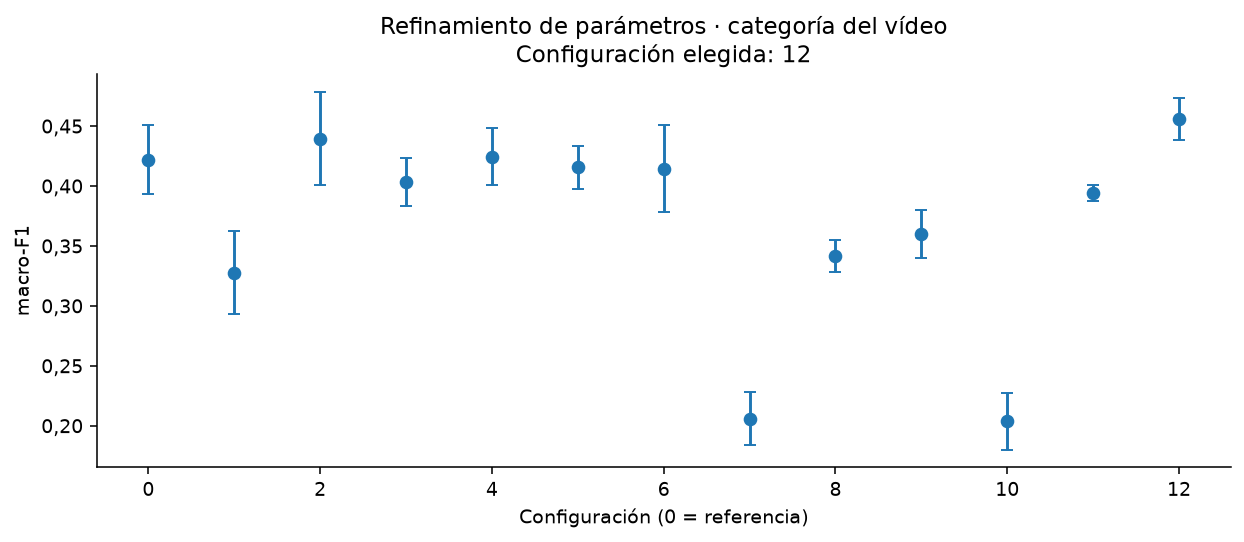

**Conclusión de la selección.** Se elige **svm** por la mejor media de macro-F1 en las mismas particiones de desarrollo.

La ventaja sobre **logistic** es **0,0121** puntos de macro-F1.

La familia seleccionada combina una respuesta lineal regularizada con atributos TF-IDF: muchos atributos textuales dispersos, de los que cada vídeo activa pocos. Esto permite acumular señales de términos sin estimar todas sus interacciones. 

Alternativas no lineales contrastadas: forest_classifier = 0,3300; xgb_classifier = 0,3260; svm_rbf = 0,2007. Aquí no superan la media ganadora con las rejillas y presupuestos utilizados; no demuestra inferioridad general ni aísla la causa de la diferencia.

**Qué cambia en el refinamiento:** estimator__C: 2 → 1 (inverso de la regularización; mayor C reduce la regularización relativa y penaliza más los errores); features__text__ngram_range: [1; 2] → [1; 1] (longitud mínima y máxima de secuencias de palabras); estimator__max_iter: no registrado en la referencia → 30.000 (límite de iteraciones para permitir la convergencia). Los límites de iteraciones pueden proceder de la revisión de convergencia. Al variar varios parámetros no se atribuye la mejora a uno de ellos por separado.

In [7]:
# Compara familias y muestra el refinamiento de category.
comparison = study.compare('category')
show_model_comparison('category', comparison, ROOT)

### Comentarios deshabilitados · Reto opcional de clasificación

Primera parte del reto opcional de clasificación. Objetivo de inferencia: `comments_disabled`.

Se muestran familias, espacio de segunda búsqueda, todas las configuraciones ensayadas y su dispersión entre particiones. El candidato 0 conserva la referencia.


**Comparación de familias: comentarios desactivados.** **12** entradas, **12** con puntuación finita y **0** sin ella. La mejor es **svm**, con Macro-F1 medio **0,5767** y desviación entre particiones **0,0416**. Los candidatos usan las mismas particiones. Una diferencia pequeña requiere cautela. El macro-F1 promedia las clases presentes en las etiquetas reales o predichas de cada partición. Revisar el soporte de las clases raras ayuda a interpretar la comparación.

**Refinamiento para comentarios desactivados: svm.** **13** configuraciones, **3** particiones y **5.955** filas elegibles. Macro-F1 de la búsqueda inicial **0,5767**. Referencia reevaluada **0,5767**. Configuración seleccionada **2** con Macro-F1 de **0,5949** y desviación entre particiones **0,0630**. Variación de macro-F1 respecto a la referencia reevaluada **0,0181**. Se selecciona otra configuración. Puede haber empate en la puntuación. Los índices identifican ensayos. Las barras muestran dispersión entre particiones. El refinamiento usa las particiones de desarrollo y la prueba reservada se mantiene aparte.

,model,cv_score,cv_std,cv_train_score,fold_scores,seconds,convergence_review
,modelo o referencia,puntuación media en validación cruzada,desviación entre particiones,puntuación media en ajuste,puntuación en cada partición,duración en segundos,revisión del ajuste y sus avisos
0,baseline_classifier,"0,493192","0,000059","0,493191","[0,493235; 0,493231; 0,493109]","15,25",Sin avisos de convergencia; 1 intento de búsqueda
1,knn_classifier,"0,49966","0,010098","0,998392","[0,492327; 0,492713; 0,51394]","20,391",Sin avisos de convergencia; 1 intento de búsqueda
2,tree_classifier,"0,522355","0,078243","0,712754","[0,620754; 0,429323; 0,516988]","9,531",Sin avisos de convergencia; 1 intento de búsqueda
3,logistic,"0,570517","0,05016","0,933316","[0,640422; 0,525122; 0,546007]","20,781",Sin avisos de convergencia; 1 intento de búsqueda
4,svm,"0,576733","0,041649","0,929901","[0,635422; 0,551712; 0,543065]","9,765",Sin avisos de convergencia; 1 intento de búsqueda
5,svm_rbf,"0,504164","0,002456","0,704661","[0,501147; 0,504182; 0,507163]","14,453",Sin avisos de convergencia; 1 intento de búsqueda
6,naive_bayes,"0,493192","0,000059","0,59827","[0,493235; 0,493231; 0,493109]","8,328",Sin avisos de convergencia; 1 intento de búsqueda
7,sgd,"0,55411","0,03234","0,886065","[0,598702; 0,523009; 0,540618]","7,563",Sin avisos de convergencia; 1 intento de búsqueda
8,forest_classifier,"0,541858","0,017358","0,898756","[0,564902; 0,523009; 0,537663]","10,407",Sin avisos de convergencia; 1 intento de búsqueda


,parámetros seleccionados · comentarios desactivados
estimator__C,3
estimator__class_weight,None
features__text__max_features,16.000
features__text__min_df,2
features__text__ngram_range,[1; 1]
features__text__sublinear_tf,True
estimator__max_iter,30.000


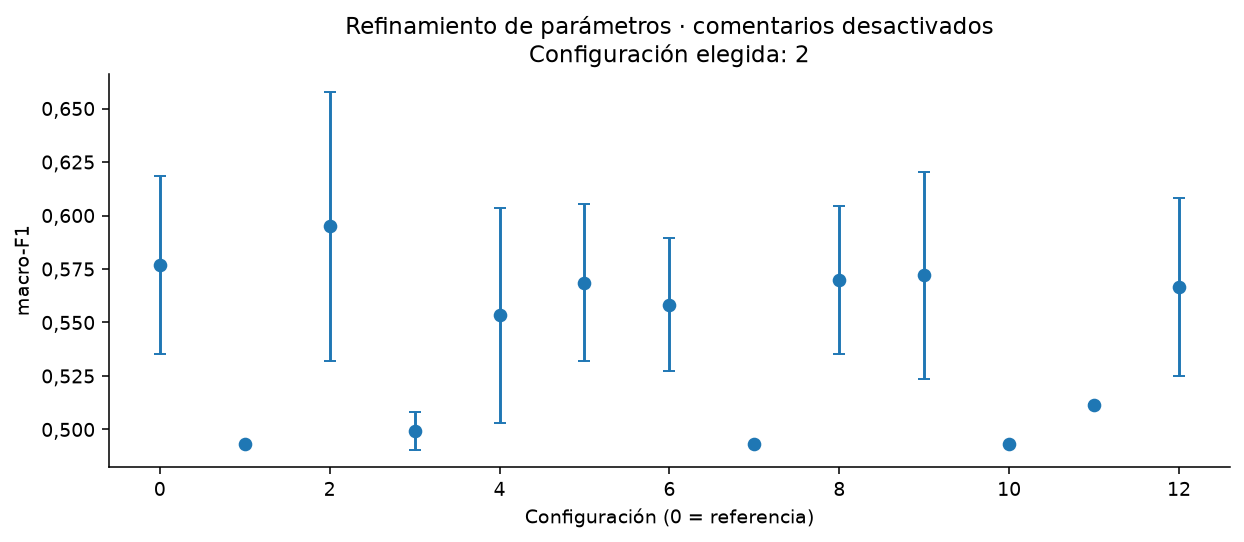

**Conclusión de la selección.** Se elige **svm** por la mejor media de macro-F1 en las mismas particiones de desarrollo.

La ventaja sobre **logistic** es **0,0062** puntos de macro-F1.

Es también una familia lineal regularizada con atributos TF-IDF; su funcionamiento se explica en el primer reto donde se selecciona.

Alternativas no lineales contrastadas: forest_classifier = 0,5419; xgb_classifier = 0,5220; svm_rbf = 0,5042. Aquí no superan la media ganadora con las rejillas y presupuestos utilizados; no demuestra inferioridad general ni aísla la causa de la diferencia.

**Qué cambia en el refinamiento:** estimator__C: 0,3 → 3 (inverso de la regularización; mayor C reduce la regularización relativa y penaliza más los errores); estimator__class_weight: balanced → None (ponderación de clases; balanced compensa su frecuencia); features__text__max_features: 8.000 → 16.000 (límite de términos del vocabulario); features__text__ngram_range: [1; 2] → [1; 1] (longitud mínima y máxima de secuencias de palabras); estimator__max_iter: no registrado en la referencia → 30.000 (límite de iteraciones para permitir la convergencia). Los límites de iteraciones pueden proceder de la revisión de convergencia. Al variar varios parámetros no se atribuye la mejora a uno de ellos por separado.

In [8]:
# Compara familias y muestra el refinamiento de comments_disabled.
comparison = study.compare('comments_disabled')
show_model_comparison('comments_disabled', comparison, ROOT)

### Valoraciones deshabilitadas · Reto opcional de clasificación

Segunda parte del reto opcional de clasificación. Objetivo de inferencia: `ratings_disabled`.

Se muestran familias, espacio de segunda búsqueda, todas las configuraciones ensayadas y su dispersión entre particiones. El candidato 0 conserva la referencia.


**Comparación de familias: valoraciones desactivadas.** **12** entradas, **12** con puntuación finita y **0** sin ella. La mejor es **logistic**, con Macro-F1 medio **0,5521** y desviación entre particiones **0,0250**. Los candidatos usan las mismas particiones. Una diferencia pequeña requiere cautela. El macro-F1 promedia las clases presentes en las etiquetas reales o predichas de cada partición. Revisar el soporte de las clases raras ayuda a interpretar la comparación.

**Refinamiento para valoraciones desactivadas: logistic.** **13** configuraciones, **3** particiones y **5.955** filas elegibles. Macro-F1 de la búsqueda inicial **0,5521**. Referencia reevaluada **0,5521**. Configuración seleccionada **12** con Macro-F1 de **0,5555** y desviación entre particiones **0,0237**. Variación de macro-F1 respecto a la referencia reevaluada **0,0034**. Se selecciona otra configuración. Puede haber empate en la puntuación. Los índices identifican ensayos. Las barras muestran dispersión entre particiones. El refinamiento usa las particiones de desarrollo y la prueba reservada se mantiene aparte.

,model,cv_score,cv_std,cv_train_score,fold_scores,seconds,convergence_review
,modelo o referencia,puntuación media en validación cruzada,desviación entre particiones,puntuación media en ajuste,puntuación en cada partición,duración en segundos,revisión del ajuste y sus avisos
0,baseline_classifier,"0,496193","0,000002","0,496193","[0,496193; 0,496195; 0,496191]","9,64",Sin avisos de convergencia; 1 intento de búsqueda
1,knn_classifier,"0,511118","0,011459","0,997156","[0,517378; 0,495042; 0,520932]","11,125",Sin avisos de convergencia; 1 intento de búsqueda
2,tree_classifier,"0,445163","0,020308","0,483976","[0,462943; 0,416741; 0,455805]","7,015",Sin avisos de convergencia; 1 intento de búsqueda
3,logistic,"0,552074","0,024983","0,825258","[0,584012; 0,52302; 0,54919]","17,282",Sin avisos de convergencia; 1 intento de búsqueda
4,svm,"0,538007","0,011893","0,778753","[0,544321; 0,52135; 0,548351]","8,687",Sin avisos de convergencia; 1 intento de búsqueda
5,svm_rbf,"0,526727","0,012363","0,633916","[0,518634; 0,517352; 0,544196]","12,265",Sin avisos de convergencia; 1 intento de búsqueda
6,naive_bayes,"0,496193","0,000002","0,494481","[0,496193; 0,496195; 0,496191]","7,125",Sin avisos de convergencia; 1 intento de búsqueda
7,sgd,"0,516771","0,0273","0,605237","[0,551369; 0,514308; 0,484634]","7,469",Sin avisos de convergencia; 1 intento de búsqueda
8,forest_classifier,"0,494273","0,005054","0,541489","[0,49818; 0,487137; 0,497503]","11,047",Sin avisos de convergencia; 1 intento de búsqueda


,parámetros seleccionados · valoraciones desactivadas
estimator__C,1
estimator__class_weight,balanced
features__text__max_features,8.000
features__text__min_df,2
features__text__ngram_range,[1; 1]
features__text__sublinear_tf,True
estimator__max_iter,3.000


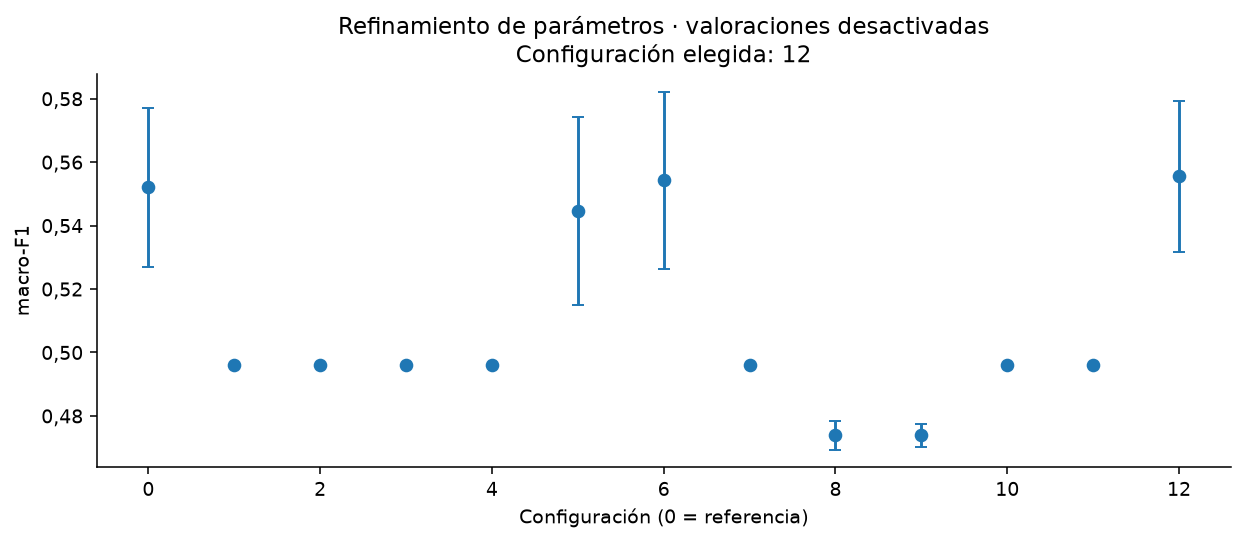

**Conclusión de la selección.** Se elige **logistic** por la mejor media de macro-F1 en las mismas particiones de desarrollo.

La ventaja sobre **svm** es **0,0141** puntos de macro-F1.

Es también una familia lineal regularizada con atributos TF-IDF; su funcionamiento se explica en el primer reto donde se selecciona.

Alternativas no lineales contrastadas: svm_rbf = 0,5267; xgb_classifier = 0,5070; forest_classifier = 0,4943. Aquí no superan la media ganadora con las rejillas y presupuestos utilizados; no demuestra inferioridad general ni aísla la causa de la diferencia.

**Qué cambia en el refinamiento:** estimator__C: 2 → 1 (inverso de la regularización; mayor C reduce la regularización relativa y penaliza más los errores); estimator__max_iter: no registrado en la referencia → 3.000 (límite de iteraciones para permitir la convergencia). Los límites de iteraciones pueden proceder de la revisión de convergencia. Al variar varios parámetros no se atribuye la mejora a uno de ellos por separado.

In [9]:
# Compara familias y muestra el refinamiento de ratings_disabled.
comparison = study.compare('ratings_disabled')
show_model_comparison('ratings_disabled', comparison, ROOT)

### Número de likes · Reto normal de regresión

Objetivo de inferencia: `likes`.

Se muestran familias, espacio de segunda búsqueda, todas las configuraciones ensayadas y su dispersión entre particiones. El candidato 0 conserva la referencia.

**Métrica de selección.** MAE es la distancia absoluta media entre valor real y estimado, medida en likes. SVR adapta las máquinas de vectores soporte a cantidades. Extra Trees combina árboles con cortes más aleatorios.


**Comparación de familias: número de «me gusta».** **19** entradas, **19** con puntuación finita y **0** sin ella. La mejor es **svr_log_target**, con MAE medio **9.666,64** y desviación entre particiones **1.395,83**. Los candidatos usan las mismas particiones. Una diferencia pequeña requiere cautela. La tabla técnica conserva −MAE. Una puntuación mayor corresponde a un error menor en la escala original del objetivo, incluso con transformación logarítmica.

**Refinamiento para número de «me gusta»: svr_log_target.** **13** configuraciones, **3** particiones y **5.955** filas elegibles. MAE de la búsqueda inicial **9.666,64**. Referencia reevaluada **9.666,64**. Configuración seleccionada **12** con MAE de **9.178,76** y desviación entre particiones **1.390,90**. Reducción de MAE respecto a la referencia reevaluada **487,88**. Se selecciona otra configuración. Puede haber empate en la puntuación. Los índices identifican ensayos. Las barras muestran dispersión entre particiones. El refinamiento usa las particiones de desarrollo y la prueba reservada se mantiene aparte.

,model,cv_score,cv_std,cv_train_score,fold_scores,seconds,convergence_review
,modelo o referencia,puntuación media en validación cruzada,desviación entre particiones,puntuación media en ajuste,puntuación en cada partición,duración en segundos,revisión del ajuste y sus avisos
0,baseline_regressor,"-25.149,587238","1.095,154751","-25.149,203694","[-25.850,624685; -23.603,051889; -25.995,085139]","18,375",Sin avisos de convergencia; 1 intento de búsqueda
1,knn_regressor,"-20.526,044314","1.804,378285","-0,001679","[-23.032,983684; -18.860,127371; -19.685,021887]","18,078",Sin avisos de convergencia; 1 intento de búsqueda
2,knn_regressor_log_target,"-19.960,119082","2.738,751474","-0,001679","[-23.789,031593; -17.539,983889; -18.551,341765]","14,812",Sin avisos de convergencia; 1 intento de búsqueda
3,tree_regressor,"-20.937,433864","3.931,784075","-5.795,603551","[-26.074,837961; -20.210,931149; -16.526,532483]","7,281",Sin avisos de convergencia; 1 intento de búsqueda
4,tree_regressor_log_target,"-25.210,075868","1.174,624229","-7.871,108063","[-24.427,018346; -24.332,853743; -26.870,355514]","7,641",Sin avisos de convergencia; 1 intento de búsqueda
5,ridge,"-25.273,8974","1.064,243415","-8.540,117884","[-25.273,340044; -23.970,749503; -26.577,602652]","13,828",Sin avisos de convergencia; 1 intento de búsqueda
6,ridge_log_target,"-11.844,75213","2.693,09901","-6.423,92918","[-12.511,942295; -14.758,512338; -8.263,801758]","11,391",Sin avisos de convergencia; 1 intento de búsqueda
7,svr,"-23.149,007601","1.059,641003","-23.133,18914","[-23.793,427547; -21.655,131812; -23.998,463444]","6,75",Sin avisos de convergencia; 1 intento de búsqueda
8,svr_log_target,"-9.666,639036","1.395,827984","-3.614,022572","[-11.152,251812; -10.049,541158; -7.798,124137]","102,891",Persisten avisos de convergencia; 2 intentos de búsqueda


,parámetros seleccionados · número de «me gusta»
estimator__regressor__C,"0,1"
features__text__max_features,16.000
features__text__min_df,4
features__text__ngram_range,[1; 2]
features__text__sublinear_tf,True
estimator__regressor__max_iter,60.000


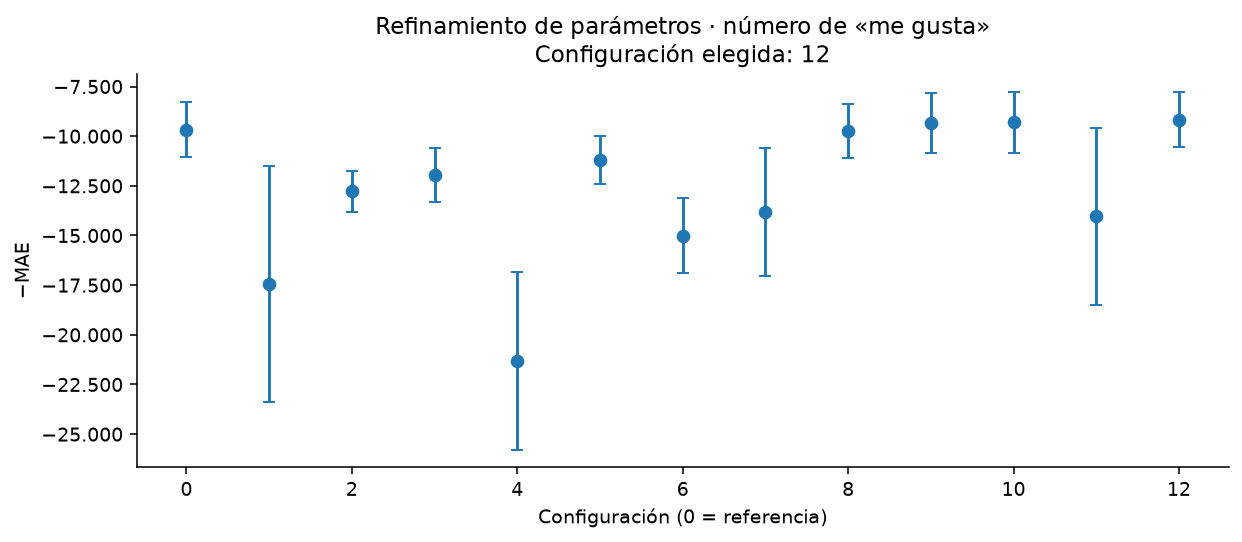

**Conclusión de la selección.** Se elige **svr_log_target** por la mejor media de −MAE en las mismas particiones de desarrollo.

La ventaja sobre **xgb_regressor_log_target** es **963,5340** unidades de MAE.

La familia seleccionada combina una respuesta lineal regularizada con atributos TF-IDF: muchos atributos textuales dispersos, de los que cada vídeo activa pocos. Esto permite acumular señales de términos sin estimar todas sus interacciones. El objetivo log1p reduce la escala de los extremos durante el ajuste y la predicción vuelve a la escala original.

Alternativas no lineales contrastadas: xgb_regressor_log_target = 10.630,1731; svr_rbf_log_target = 11.535,2157; xgb_regressor = 13.086,9813; forest_regressor = 21.017,5059; forest_regressor_log_target = 23.274,0211; svr_rbf = 25.006,8071. Aquí no superan la media ganadora con las rejillas y presupuestos utilizados; no demuestra inferioridad general ni aísla la causa de la diferencia.

**Qué cambia en el refinamiento:** features__text__max_features: 8.000 → 16.000 (límite de términos del vocabulario); features__text__min_df: 2 → 4 (mínimo de documentos en los que debe aparecer un término); estimator__regressor__max_iter: no registrado en la referencia → 60.000 (límite de iteraciones para permitir la convergencia). Los límites de iteraciones pueden proceder de la revisión de convergencia. Al variar varios parámetros no se atribuye la mejora a uno de ellos por separado.

In [10]:
# Compara familias y muestra el refinamiento de likes.
comparison = study.compare('likes')
show_model_comparison('likes', comparison, ROOT, regression=True)

### Proporción de likes y dislikes · Reto opcional de regresión

Objetivo de inferencia: `ratio`.

Se muestran familias, espacio de segunda búsqueda, todas las configuraciones ensayadas y su dispersión entre particiones. El candidato 0 conserva la referencia.

**Ablación y Ridge.** Una ablación retira entradas y repite la comparación para medir su aporte. Ridge es una regresión que penaliza coeficientes grandes para estabilizar el ajuste.


**Comparación de familias: proporción «me gusta/no me gusta».** **19** entradas, **19** con puntuación finita y **0** sin ella. La mejor es **ridge_log_target**, con MAE medio **26,46** y desviación entre particiones **2,75**. Los candidatos usan las mismas particiones. Una diferencia pequeña requiere cautela. La tabla técnica conserva −MAE. Una puntuación mayor corresponde a un error menor en la escala original del objetivo, incluso con transformación logarítmica.

**Refinamiento para proporción «me gusta/no me gusta»: ridge_log_target.** **13** configuraciones, **3** particiones y **5.827** filas elegibles. MAE de la búsqueda inicial **26,46**. Referencia reevaluada **26,46**. Configuración seleccionada **0** con MAE de **26,46** y desviación entre particiones **2,75**. Reducción de MAE respecto a la referencia reevaluada **0,00**. Se conserva la configuración de referencia. Los índices identifican ensayos. Las barras muestran dispersión entre particiones. El refinamiento usa las particiones de desarrollo y la prueba reservada se mantiene aparte.

,model,cv_score,cv_std,cv_train_score,fold_scores,seconds,convergence_review
,modelo o referencia,puntuación media en validación cruzada,desviación entre particiones,puntuación media en ajuste,puntuación en cada partición,duración en segundos,revisión del ajuste y sus avisos
0,baseline_regressor,"-29,603364","3,48007","-29,594411","[-29,773394; -33,778002; -25,258695]","12,094",Sin avisos de convergencia; 1 intento de búsqueda
1,knn_regressor,"-34,981899","3,177237","-0,000016","[-38,678917; -35,345017; -30,921762]","18,125",Sin avisos de convergencia; 1 intento de búsqueda
2,knn_regressor_log_target,"-31,11901","3,492636","-0,000016","[-34,781689; -32,157574; -26,417768]","12,141",Sin avisos de convergencia; 1 intento de búsqueda
3,tree_regressor,"-34,933974","3,506113","-22,337381","[-37,238528; -37,583804; -29,97959]","8,594",Sin avisos de convergencia; 1 intento de búsqueda
4,tree_regressor_log_target,"-29,763454","3,928654","-23,232641","[-30,456066; -34,191214; -24,643083]","9,844",Sin avisos de convergencia; 1 intento de búsqueda
5,ridge,"-31,313701","1,074845","-23,87225","[-31,389644; -32,590497; -29,960962]","14,812",Sin avisos de convergencia; 1 intento de búsqueda
6,ridge_log_target,"-26,45679","2,747527","-13,024762","[-25,977629; -30,035706; -23,357036]","12,984",Sin avisos de convergencia; 1 intento de búsqueda
7,svr,"-27,506171","3,142785","-24,142088","[-27,780132; -31,210981; -23,5274]","7,828",Sin avisos de convergencia; 1 intento de búsqueda
8,svr_log_target,"-27,029701","3,049299","-20,447657","[-27,414867; -30,556805; -23,117432]","89,297",Avisos de convergencia resueltos; 2 intentos de búsqueda


,parámetros seleccionados · proporción «me gusta/no me gusta»
estimator__regressor__alpha,1
features__text__max_features,8.000
features__text__min_df,2
features__text__ngram_range,[1; 1]
features__text__sublinear_tf,True
estimator__regressor__max_iter,None


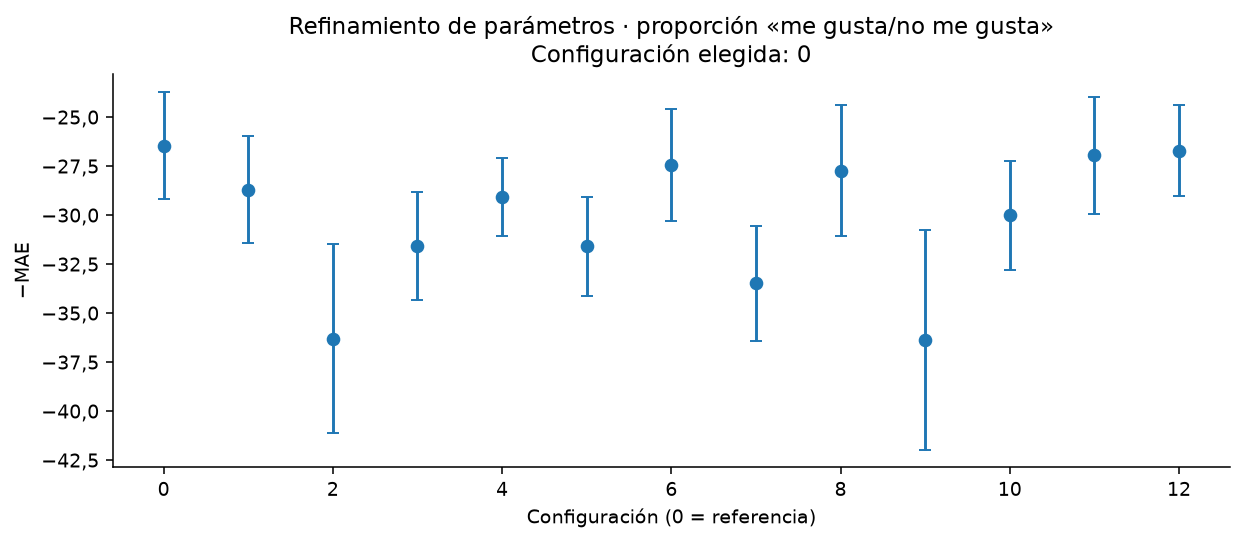

**Conclusión de la selección.** Se elige **ridge_log_target** por la mejor media de −MAE en las mismas particiones de desarrollo.

La ventaja sobre **svr_log_target** es **0,5729** unidades de MAE.

Es también una familia lineal regularizada con atributos TF-IDF; su funcionamiento se explica en el primer reto donde se selecciona.

Alternativas no lineales contrastadas: xgb_regressor_log_target = 27,1794; forest_regressor_log_target = 27,6006; svr_rbf = 27,6682; svr_rbf_log_target = 28,1396; xgb_regressor = 31,7327; forest_regressor = 31,8986. Aquí no superan la media ganadora con las rejillas y presupuestos utilizados; no demuestra inferioridad general ni aísla la causa de la diferencia.

El refinamiento conserva los parámetros de referencia: las alternativas ensayadas no mejoran su media de validación.

In [11]:
# Compara familias y muestra el refinamiento de ratio.
comparison = study.compare('ratio')
show_model_comparison('ratio', comparison, ROOT, regression=True)

### No supervisados, calibración y entrenamiento final

Se comparan segmentación y recuperación, se calibran umbrales con OOF de entrenamiento y se congelan las recetas en las secciones model:* de train.conf. El entrenador final se ejecuta con esas recetas: ajusta y guarda los siete ganadores, sin búsquedas.

**Ajuste y reutilización.** La receta recoge el algoritmo, las transformaciones, los parámetros y el umbral cuando procede. Pickle conserva los pesos y transformadores ya aprendidos. El manifiesto identifica ese estado y la huella SHA-256 permite comprobar de qué archivos y datos procede.


In [12]:
report=study.finish()

# guide_tasks: rótulos y alcance de cada reto supervisado según el enunciado.
guide_tasks = {
    'category': ('Categoría del vídeo', 'Normal'),
    'comments_disabled': ('Comentarios desactivados', 'Opcional'),
    'ratings_disabled': ('Valoraciones desactivadas', 'Opcional'),
    'likes': ('Número de likes (me gusta)', 'Normal'),
    'ratio': ('Proporción likes/dislikes (me gusta/no me gusta)', 'Opcional'),
}
# guide_models: nombres legibles para las recetas. Los identificadores técnicos siguen en el detalle.
guide_models = {
    'svm': 'SVM', 'logistic': 'Regresión logística',
    'svr_log_target': 'SVR (objetivo logarítmico)', 'ridge_log_target': 'Ridge (objetivo logarítmico)',
    'kmeans': 'KMeans', 'char_tfidf': 'TF-IDF de caracteres',
}
# guide_rows y comparison_rows: síntesis para corregir y evidencia numérica por tarea.
guide_rows, comparison_rows = [], []
for task, (label, scope) in guide_tasks.items():
    result = report['tasks'][task]
    holdout, baseline = result['holdout'], result['baseline_holdout']
    classification = 'macro_f1' in holdout
    metric, metric_name = ('macro_f1', 'Macro-F1 ↑') if classification else ('mae', 'MAE ↓')
    value, reference = holdout[metric], baseline[metric]
    if not np.isfinite([value, reference]).all():
        raise ValueError(f'Métricas de prueba no finitas en {task}')
    gain = value - reference if classification else reference - value
    comparison_rows.append({'tarea': task, 'modelo': result['selected'], 'métrica': metric_name,
                            'prueba': value, 'referencia': reference, 'mejora frente a referencia': gain,
                            'filas ajuste': result['train_rows'], 'filas prueba': result['test_rows']})
    if task == 'category':
        missing_classes = sum(sum(row) == 0 for row in holdout['confusion_matrix'])
        comparison = ('Supera a la clase mayoritaria' if gain > 0 else
                      'Iguala a la clase mayoritaria' if gain == 0 else 'Queda por debajo de la clase mayoritaria')
        conclusion = f'{comparison}. En prueba quedan {highlight_number(missing_classes)} categorías sin casos reales.'
    elif classification:
        # positive: posición de la clase desactivada. La matriz cruza valores reales y predichos.
        positive = holdout['labels'].index('1')
        matrix = np.asarray(holdout['confusion_matrix'])
        hits, actual, alerts = matrix[positive, positive], matrix[positive].sum(), matrix[:, positive].sum()
        recall = highlight_number(100 * hits / actual, 1, ' %') if actual else 'sin casos reales'
        precision = highlight_number(100 * hits / alerts, 1, ' %') if alerts else 'sin avisos'
        conclusion = (f'Detecta {highlight_number(hits)} de {highlight_number(actual)} casos reales ({recall}). '
                      f'Acierta el {precision} de los avisos.' if alerts else
                      f'Hay {highlight_number(actual)} casos reales y el modelo no emite avisos de desactivación.')
    else:
        r2 = holdout.get('r2')
        r2_text = highlight_number(r2, 3) if r2 is not None and np.isfinite(r2) else 'no estimable'
        if task == 'likes':
            outcome = ('Reduce el error respecto a la mediana' if gain > 0 else
                       'Iguala el error de la mediana' if gain == 0 else 'Aumenta el error respecto a la mediana')
            conclusion = f'{outcome}. La estimación usa interacciones ya observadas.'
        else:
            conclusion = f'R² de prueba {r2_text}. Se evalúa donde hay al menos un dislike.'
    decimals = 3 if classification or task == 'ratio' else 0
    guide_rows.append((f'{label} · {scope}', guide_models.get(result['selected'], result['selected']),
                       f'{metric_name} {highlight_number(value, decimals)}',
                       highlight_number(reference, decimals), conclusion))

# cluster y rec_test: métricas específicas de agrupación y recuperación.
cluster = report['cluster_selected']
cluster_model = guide_models.get(cluster['name'], cluster['name'])
guide_rows.append((
    'Segmentación · Pedido', f'{cluster_model}, {format_number(cluster["k"], 0)} grupos',
    f'Silueta ↑ {highlight_number(cluster["silhouette"], 4)}', '—',
    f'ARI con las categorías {highlight_number(report["cluster_interpretation"]["ARI"], 3)}. '
    'Un valor cercano a cero indica poca correspondencia editorial.'
))
rec_test = report['recommendation']['independent_proxy_test']
rec_model = report['recommendation']['selected']
guide_rows.append((
    'Vídeos similares · Pedido', guide_models.get(rec_model, rec_model),
    f'Coincidencia editorial en cinco posiciones por consulta ↑ {highlight_number(100 * rec_test["category_agreement_at_5_PROXY"], 2, " %")}',
    f'Azar {highlight_number(100 * rec_test["random_category_expectation"], 2, " %")}',
    'Las posiciones vacías cuentan como no coincidencias. La evaluación humana de la utilidad de las recomendaciones se propone como ampliación y queda fuera de lo solicitado en el ejercicio.'
))
# guide_table: Markdown para resaltar cifras y mantener la guía en una sola tabla.
guide_table = [
    '### Guía de corrección de los siete retos',
    '',
    '| Reto y alcance | Modelo elegido | Resultado | Referencia | Conclusión |',
    '|---|---|---|---|---|',
    *('|' + ' | '.join(row) + '|' for row in guide_rows),
    '',
    '↑ indica que un valor mayor es favorable. ↓ indica que un error menor es favorable. '
    'En las tareas supervisadas se compara con la clase mayoritaria o la mediana del ajuste, '
    'evaluadas en las mismas filas de prueba. La silueta describe la separación de los grupos.',
]
display(Markdown('\n'.join(guide_table)))
show_details('Prueba supervisada: métricas, referencias y tamaños de ajuste y prueba',
             pd.DataFrame(comparison_rows).set_index('tarea'))

# oof_rows: procedencia y cobertura de los folds de calibración ampliada, no métricas de prueba.
oof_rows = []
for oof_task in ['comments_disabled', 'ratings_disabled']:
    oof_result = report['tasks'][oof_task]
    oof_info = oof_result['threshold_selection']
    oof_validation = oof_info['fold_validation_rows']
    if sum(oof_validation) != oof_info['oof_rows']:
        raise ValueError(f'Los tamaños de validación OOF no cubren el total declarado: {oof_task}')
    oof_rows.append({'tarea': oof_task, 'filas búsqueda inicial': oof_result['search_rows'],
                     'filas OOF ampliado': oof_info['oof_rows'], 'folds ampliados': oof_info['folds'],
                     'filas ajuste por fold': oof_info['fold_train_rows'],
                     'filas validación por fold': oof_validation,
                     'prevalencia positiva OOF': oof_info['oof_prevalence']})
display(pd.DataFrame(oof_rows))
display(Markdown(
    f'**Procedencia OOF:** {highlight_number(len(oof_rows))} tareas binarias. '
    'Cada puntuación fuera de fold proviene de un clon ajustado sin las apariciones de ese vídeo. '
    'La primera elección de umbral usa la muestra de búsqueda; la elección final se '
    'recalcula sobre el pool de ajuste ampliado con hiperparámetros ya seleccionados. '
    'Los tamaños de los folds mostrados proceden del informe y no incluyen el holdout. '
    'Su suma comprueba cobertura declarada; por sí sola no demuestra separación de identidades. '
    'Las puntuaciones OOF se usan para elegir el umbral y sus métricas no son una evaluación '
    'independiente de esa elección ni una validación anidada. '
    'OOF no significa entrenar un único modelo con todas las filas y predecir esas mismas filas.'
))

# metric_utils: calcula F2 con la misma fórmula compartida, sin elegir un umbral nuevo.
from metric_utils import f2_from_precision_recall
# results_report: explica la escala según la familia seleccionada, sin inferir calibración.
from results_report import binary_score_explanation, task_description
# threshold_rows: medidas OOF del punto elegido; no se mezclan con métricas de prueba.
threshold_rows = []
for threshold_task in ['comments_disabled', 'ratings_disabled']:
    threshold_result = report['tasks'][threshold_task]
    threshold_info = threshold_result['threshold_selection']
    threshold_value = threshold_result['threshold']
    threshold_precision = threshold_info['oof_precision']
    threshold_recall = threshold_info['oof_recall']
    threshold_f2 = float(f2_from_precision_recall(threshold_precision, threshold_recall))
    if (not np.isfinite(threshold_value)
            or not all(np.isfinite(value) and 0 <= value <= 1
                       for value in [threshold_precision, threshold_recall, threshold_info['oof_f2']])
            or not np.isclose(threshold_f2, threshold_info['oof_f2'], rtol=1e-9, atol=1e-12)):
        raise ValueError(f'Umbral o métricas F2 OOF incoherentes: {threshold_task}')
    threshold_rows.append({'tarea': threshold_task,
        'umbral OOF de búsqueda': threshold_result['search_threshold'],
        'umbral OOF ampliado': threshold_value,
        'precisión OOF ampliada': threshold_precision,
        'recall OOF ampliado': threshold_recall, 'F2 OOF ampliado': threshold_f2})
    display(Markdown(
        f'**{task_description(threshold_task).capitalize()}:** umbral OOF ampliado **{format_number(threshold_value, 6)}**, '
        f'elegido usando **{format_number(threshold_info["oof_rows"], 0)}** filas de desarrollo. '
        f'En ese OOF: precisión **{format_number((threshold_precision) * 100, 2)} %**, '
        f'recall **{format_number((threshold_recall) * 100, 2)} %** y F2 **{format_number(threshold_f2, 4)}**. '
        'Se predice desactivado (clase 1) cuando la puntuación es mayor o igual al umbral. '
        'F2 = 5PR/(4P+R): prioriza recall, pero no fija una equivalencia económica '
        'entre errores. No se elige este umbral con la prueba reservada. '
        'Estas métricas OOF describen los datos usados para escogerlo; no son métricas de test '
        'ni una estimación independiente de toda la selección. '
        + binary_score_explanation(threshold_result)
    ))
display(pd.DataFrame(threshold_rows))

# final_evidence: registro del ajuste de las recetas congeladas, no una búsqueda nueva.
final_evidence = report['final_training']
if final_evidence['status'] != 'passed' or final_evidence['fingerprint'] != report['fingerprint']:
    raise ValueError('El registro de ajuste final no coincide con el experimento')
# final_rows: tamaños efectivos y avisos por artefacto, tal como se registraron al ajustar.
final_rows = [{'tarea': task, 'familia': evidence['family'],
               'filas de ajuste': evidence['rows'],
               'umbral congelado': evidence['threshold'],
               'avisos del ajuste': evidence['warnings']}
              for task, evidence in final_evidence['models'].items()]
display(pd.DataFrame(final_rows))
display(Markdown(
    f'**Ajuste final registrado:** {highlight_number(len(final_rows))} modelos; '
    f'{highlight_number(sum(bool(row["avisos del ajuste"]) for row in final_rows))} con avisos registrados. '
    + ('En esta ejecución se reutilizan artefactos verificados; esta tabla describe su ajuste previo. '
       if reuse else 'En este recorrido se han ajustado las recetas finales después de la selección y calibración. ')
    + 'Los hiperparámetros y los dos umbrales binarios llegan fijados: se aprenden de nuevo '
    'vocabulario, transformaciones y coeficientes con la muestra ampliada de desarrollo, '
    'sin incorporar la reserva de prueba ni abrir otra búsqueda. '
    'Las tareas supervisadas conservan sólo filas con objetivo válido; agrupación y '
    'recomendación usan muestras de vídeos únicos. Se guardan modelos y manifiestos '
    'de procedencia; un ajuste completado o sin avisos no acredita por sí solo buena predicción.'
))

display(pd.Series({k:report[k] for k in ['sampling_rows','final_train_rows','holdout_rows']}).to_frame('filas'))
represent=pd.read_csv(ROOT/'reports/representativeness.csv')
# represent_view: traduce sólo los valores que corresponden al campo de categoría.
represent_view = represent.assign(abs_diff=represent.difference_pp.abs()).sort_values('abs_diff', ascending=False).head(15)
represent_view = represent_view.assign(
    value=represent_view['value'].where(
        represent_view['field'].ne('category'), represent_view['value'].map(category_label)
    )
)
show_details('Representatividad de las muestras: quince mayores diferencias', represent_view)


Calibración OOF ampliada verificada por huella.


### Guía de corrección de los siete retos

| Reto y alcance | Modelo elegido | Resultado | Referencia | Conclusión |
|---|---|---|---|---|
|Categoría del vídeo · Normal | SVM | Macro-F1 ↑ **0,527** | **0,025** | Supera a la clase mayoritaria. En prueba quedan **2** categorías sin casos reales.|
|Comentarios desactivados · Opcional | SVM | Macro-F1 ↑ **0,670** | **0,495** | Detecta **66** de **142** casos reales (**46,5 %**). Acierta el **28,8 %** de los avisos.|
|Valoraciones desactivadas · Opcional | Regresión logística | Macro-F1 ↑ **0,591** | **0,495** | Detecta **65** de **156** casos reales (**41,7 %**). Acierta el **14,4 %** de los avisos.|
|Número de likes (me gusta) · Normal | SVR (objetivo logarítmico) | MAE ↓ **14.202** | **57.088** | Reduce el error respecto a la mediana. La estimación usa interacciones ya observadas.|
|Proporción likes/dislikes (me gusta/no me gusta) · Opcional | Ridge (objetivo logarítmico) | MAE ↓ **26,984** | **32,116** | R² de prueba **0,132**. Se evalúa donde hay al menos un dislike.|
|Segmentación · Pedido | KMeans, 2 grupos | Silueta ↑ **0,2022** | — | ARI con las categorías **0,006**. Un valor cercano a cero indica poca correspondencia editorial.|
|Vídeos similares · Pedido | TF-IDF de caracteres | Coincidencia editorial en cinco posiciones por consulta ↑ **44,60 %** | Azar **14,32 %** | Las posiciones vacías cuentan como no coincidencias. La evaluación humana de la utilidad de las recomendaciones se propone como ampliación y queda fuera de lo solicitado en el ejercicio.|

↑ indica que un valor mayor es favorable. ↓ indica que un error menor es favorable. En las tareas supervisadas se compara con la clase mayoritaria o la mediana del ajuste, evaluadas en las mismas filas de prueba. La silueta describe la separación de los grupos.

,modelo,métrica,prueba,referencia,mejora frente a referencia,filas ajuste,filas prueba
tarea,,,,,,,
category,svm,Macro-F1 ↑,"0,52695","0,025406","0,501543",29.926,7.951
comments_disabled,svm,Macro-F1 ↑,"0,670203","0,495495","0,174708",29.926,7.951
ratings_disabled,logistic,Macro-F1 ↑,"0,591491","0,495046","0,096444",29.926,7.951
likes,svr_log_target,MAE ↓,"14.202,118962","57.088,142435","42.886,023473",29.926,7.951
ratio,ridge_log_target,MAE ↓,"26,984148","32,11572","5,131572",29.232,7.733


,tarea,filas búsqueda inicial,filas OOF ampliado,particiones ampliadas,filas ajuste por partición,filas validación por partición,prevalencia positiva OOF
0,comments_disabled,5.955,29.926,3,[19.950; 19.950; 19.952],[9.976; 9.976; 9.974],"0,023358"
1,ratings_disabled,5.955,29.926,3,[19.950; 19.952; 19.950],[9.976; 9.974; 9.976],"0,016775"


**Procedencia OOF:** **2** tareas binarias. Cada puntuación fuera de partición proviene de un clon ajustado sin las apariciones de ese vídeo. La primera elección de umbral usa la muestra de búsqueda; la elección final se recalcula sobre el conjunto de ajuste ampliado con hiperparámetros ya seleccionados. Los tamaños de las particiones mostrados proceden del informe y no incluyen la reserva de prueba. Su suma comprueba cobertura declarada; por sí sola no demuestra separación de identidades. Las puntuaciones OOF se usan para elegir el umbral y sus métricas no son una evaluación independiente de esa elección ni una validación anidada. OOF no significa entrenar un único modelo con todas las filas y predecir esas mismas filas.

**Comentarios desactivados:** umbral OOF ampliado **-0,455780**, elegido usando **29.926** filas de desarrollo. En ese OOF: precisión **38,71 %**, recuperación **42,92 %** y F2 **0,4201**. Se predice desactivado (clase 1) cuando la puntuación es mayor o igual al umbral. F2 = 5PR/(4P+R): prioriza recuperación, pero no fija una equivalencia económica entre errores. No se elige este umbral con la prueba reservada. Estas métricas OOF describen los datos usados para escogerlo; no son métricas de prueba ni una estimación independiente de toda la selección. La SVM lineal devuelve una puntuación de decisión, no una probabilidad; un umbral negativo no representa una probabilidad negativa.

... (2 outputs left out)

,tarea,familia,filas de ajuste,umbral congelado,avisos del ajuste
0,category,svm,29.926,—,[]
1,comments_disabled,svm,29.926,"-0,45578",[]
2,ratings_disabled,logistic,29.926,"0,579414",[]
3,likes,svr_log_target,29.926,—,[]
4,ratio,ridge_log_target,29.232,—,[]
5,cluster,kmeans,6.000,—,[]
6,recommend,char_tfidf,10.000,—,[]


**Ajuste final registrado:** **7** modelos; **0** con avisos registrados. En esta ejecución se reutilizan artefactos verificados; esta tabla describe su ajuste previo. Los hiperparámetros y los dos umbrales binarios llegan fijados: se aprenden de nuevo vocabulario, transformaciones y coeficientes con la muestra ampliada de desarrollo, sin incorporar la reserva de prueba ni abrir otra búsqueda. Las tareas supervisadas conservan sólo filas con objetivo válido; agrupación y recomendación usan muestras de vídeos únicos. Se guardan modelos y manifiestos de procedencia; un ajuste completado o sin avisos no acredita por sí solo buena predicción.

,filas
sampling_rows,5.955
final_train_rows,29.926
holdout_rows,7.951


,field,value,sample,full_fraction,sample_fraction,difference_pp,abs_diff
57,region,GB,search,"0,107257","0,090176","-1,708102","1,708102"
83,region,US,holdout,"0,113226","0,09961","-1,361566","1,361566"
81,region,MX,holdout,"0,110416","0,11923","0,881432","0,881432"
39,category,Entertainment (entretenimiento),holdout,"0,287669","0,296441","0,877121","0,877121"
78,region,IN,holdout,"0,090376","0,099107","0,873071","0,873071"
74,region,CA,holdout,"0,11317","0,104892","-0,827794","0,827794"
75,region,DE,holdout,"0,113057","0,104892","-0,816444","0,816444"
76,region,FR,holdout,"0,112736","0,120111","0,737489","0,737489"
73,region,US,final_train,"0,113226","0,119963","0,67368","0,67368"
44,category,Music (música),holdout,"0,114328","0,108666","-0,566198","0,566198"


## 6. Comparación, variabilidad y sobreajuste

**Incertidumbre.** Un intervalo de confianza (IC) resume variación bajo el procedimiento de cálculo. Aquí se remuestrean vídeos con reemplazo (se pueden seleccionar varias veces) para estudiar cuánto cambian las métricas. No incluye por sí solo la incertidumbre de haber elegido un modelo ni un posible cambio futuro de los datos.

**Lectura de métricas.** Macro-F1 promedia el equilibrio entre precisión y detección de cada clase. RMSE (raíz del error cuadrático medio) da más peso a errores grandes. R² (coeficiente de determinación) compara el error cuadrático con una predicción constante. Las curvas de aprendizaje comparan ajuste y validación cuando cambia el tamaño de los datos.

Las tablas conservan todos los candidatos y sus avisos; las puntuaciones negativas de regresión son −MAE. La desviación entre particiones y la separación entrenamiento/prueba evitan confundir capacidad de memorizar con generalización.


**Lectura común de la evaluación.** Las cifras y conclusiones se leen por tarea. Las notas sobre etiquetas y macro-F1 se aplican a clasificación; las del umbral OOF, a las dos tareas binarias. El resto explica el alcance de las curvas, las regiones y la prueba.

Las barras de error de las curvas de aprendizaje muestran la desviación entre particiones. No son intervalos de confianza ni intervalos de predicción individual para un vídeo. Las particiones comparten parte del entrenamiento y su número es reducido.

Para cada tamaño se ajustan clones sin estado aprendido, usando vídeos completos de la parte de ajuste; la validación de la partición permanece fija. El preprocesamiento se aprende dentro de la cadena de procesamiento. La receta ya fue seleccionada con estos datos de desarrollo: esta curva no es validación anidada independiente ni utiliza la reserva de prueba.

Macro-F1 se calcula con las clases presentes en respuestas o predicciones de cada evaluación; entrenamiento y validación pueden promediar conjuntos de clases distintos. La brecha no es una comparación perfectamente homogénea de etiquetas.

Las predicciones de los clones usan el umbral predeterminado del estimador; no incorporan el umbral OOF final. No se equipara esta línea con el rendimiento del modelo final calibrado.

evaluate fija las etiquetas con la unión de las clases del ajuste y las respuestas de cada región; macro-F1 incluye los ceros convencionales para etiquetas de esa unión sin casos ni predicciones en la región. No se interpreta como una media sólo de clases presentes. La tabla de soportes no contiene errores ni predicciones por clase.

La composición de objetivos, idiomas, canales y vídeos puede variar entre regiones; no se atribuye la diferencia al país. Un mismo vídeo puede aparecer en varias regiones dentro de prueba. Se describe una prueba interna, sin cambiar recetas ni elegir otro umbral con estos resultados.

Se describe el modelo ya fijado. Estas métricas no justifican cambiar su umbral con la prueba; los costes, los soportes y una evaluación externa siguen siendo necesarios.

Los coeficientes dependen de la escala transformada y no demuestran causalidad. Las curvas de la muestra de búsqueda no demuestran saturación ni garantizan lo que ocurrirá con más datos. Los soportes, regiones y mayores errores completos se conservan en los desplegables.

Las cautelas generales de lectura (curvas, regiones, coeficientes y errores) se despliegan la primera vez que aparecen; en las tareas siguientes sólo se muestran los párrafos con resultados propios.

### categoría del vídeo · seleccionado: svm

Macro-F1 de prueba 0,527, referencia 0,025. Categorías sin soporte en prueba: 2; no se estima su fiabilidad con esa reserva.

,train,reserva de prueba,baseline_holdout
macro_f1,"0,934043","0,52695","0,025406"
balanced_accuracy,"0,970297","0,642155","0,0625"


**Conclusión para categoría del vídeo.** Con **955,0** → **3.970,0** filas medias de ajuste por partición, el macro-F1 de validación pasa de **0,2926** a **0,4557**. Se observa mejora dentro del rango medido; merece contrastar una muestra mayor mediante validación de desarrollo, sin extrapolar una ganancia fuera de ese rango.

<details><summary>Interpretación de la curva: categoría del vídeo</summary>

**Curva de aprendizaje: categoría del vídeo.** 3 tamaños y 3 particiones. Eje X: media de filas efectivas de ajuste por partición, de 955,0 a 3.970,0; no es el número de vídeos ni el tamaño del ajuste final.

Validación macro-F1: 0,2926 → 0,4557; aumenta. Mayor es mejor: mejora numérica entre extremos. Pasos consecutivos favorables: 2 de 2; no se presupone una evolución monótona.

En el último tamaño, entrenamiento 0,9854 y validación 0,4557. Brecha orientada para que un valor positivo indique ventaja del entrenamiento: 0,5298. Es un diagnóstico condicionado a los datos y al protocolo, no una prueba aislada de sobreajuste.

Barras: media de validación ± desviación entre particiones, calculada con ddof=0; última desviación 0,0176. 

</details>

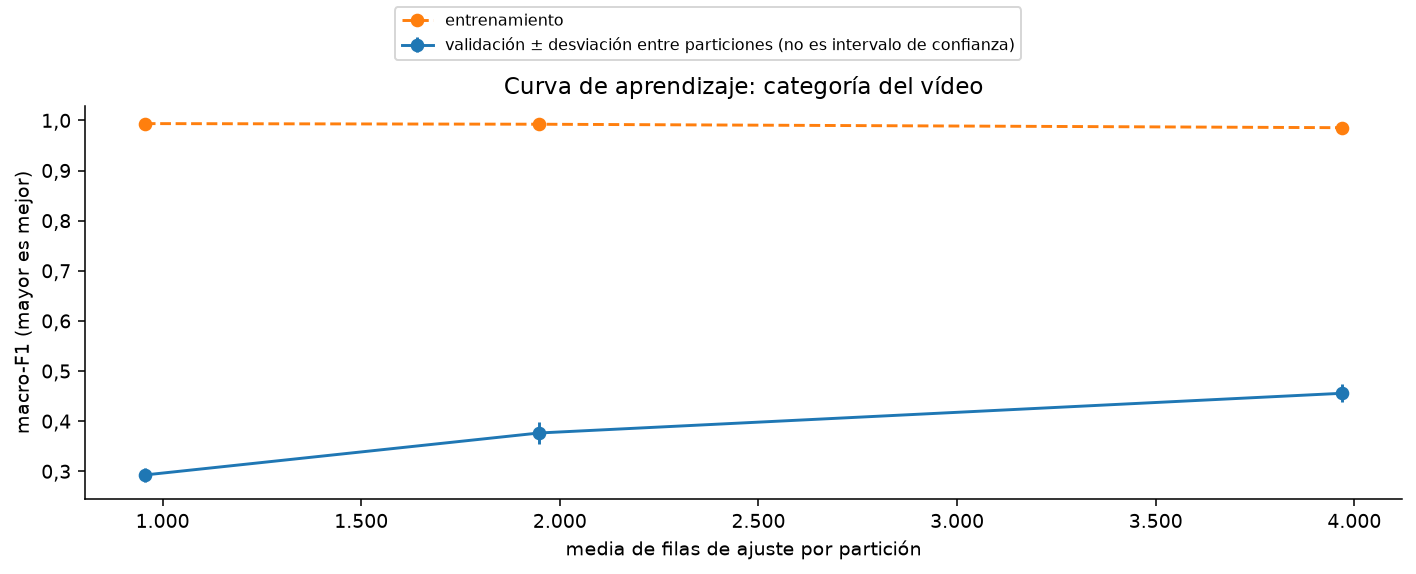

<details><summary>Interpretación regional: categoría del vídeo</summary>

**Diagnóstico regional: categoría del vídeo.** 10 regiones y 7.951 apariciones; soportes entre 339 y 955. Son filas de prueba, no vídeos únicos ni personas de esas nacionalidades.

Comparación descriptiva por balanced_accuracy: mayor es favorable. Regiones con al menos 100 filas: 10. El filtro no garantiza soporte de cada clase, independencia ni significación estadística.

Valor menos favorable entre las elegibles: JP, balanced_accuracy 0,4523, n=339. 

Clases con casos reales por región: entre 12 y 16, de 18 etiquetas declaradas. Exactitud equilibrada promedia recuperación sólo de clases presentes; esos conjuntos pueden diferir entre regiones.

</details>

,region,rows,macro_f1,balanced_accuracy
,region,rows,F1 medio con igual peso por clase,exactitud equilibrada
0,CA,834,"0,562915","0,700401"
1,DE,834,"0,461787","0,591757"
2,FR,955,"0,449252","0,569776"
3,GB,858,"0,452562","0,706167"
4,IN,788,"0,606082","0,885629"
5,JP,339,"0,334295","0,452321"
6,KR,702,"0,353606","0,58787"
7,MX,948,"0,438978","0,566507"
8,RU,901,"0,502433","0,628023"


<details><summary>Interpretación completa de clasificación: categoría del vídeo</summary>

**Lectura de clasificación: categoría del vídeo.** Filas = clase real; columnas = predicción, en el orden ['Autos & Vehicles (automóviles y vehículos)', 'Comedy (comedia)', 'Education (educación)', 'Entertainment (entretenimiento)', 'Film & Animation (cine y animación)', 'Gaming (videojuegos)', 'Howto & Style (tutoriales y estilo)', 'Movies (películas)', 'Music (música)', 'News & Politics (noticias y política)', 'Nonprofits & Activism (organizaciones sin ánimo de lucro y activismo)', 'People & Blogs (personas y blogs)', 'Pets & Animals (mascotas y animales)', 'Science & Technology (ciencia y tecnología)', 'Shows (programas)', 'Sports (deportes)', 'Trailers (tráilers)', 'Travel & Events (viajes y eventos)'].

Diagonal: 5.425 aciertos de 7.951 apariciones; fuera de la diagonal: 2.526 errores. Exactitud 68,23 %. No son necesariamente vídeos distintos.

Macro-F1 0,5269: media de F1 sobre 18 etiquetas declaradas. Exactitud equilibrada 0,6422: media de la recuperación de las 16 clases con casos reales. No equivale al porcentaje global de aciertos.

Sin casos reales en prueba: Movies (películas), Trailers (tráilers). Su recuperación no se puede estimar; el informe usa cero por convención, no como prueba de fracaso. No hay que equiparar recuperación macro y exactitud equilibrada si usan conjuntos de clases distintos.

</details>

,precision,recall,f1-score,support
,precisión de positivos,recuperación de casos reales,F1,casos reales
Autos & Vehicles (automóviles y vehículos),"0,58042","0,813725","0,677551",102
Comedy (comedia),"0,688889","0,666667","0,677596",558
Education (educación),"0,515021","0,759494","0,613811",158
Entertainment (entretenimiento),"0,76973","0,653797","0,707043",2.357
Film & Animation (cine y animación),"0,654506","0,664488","0,659459",459
Gaming (videojuegos),"0,540925","0,630705","0,582375",241
Howto & Style (tutoriales y estilo),"0,669767","0,778378","0,72",370
Movies (películas),0,0,0,0
Music (música),"0,836594","0,841435","0,839008",864


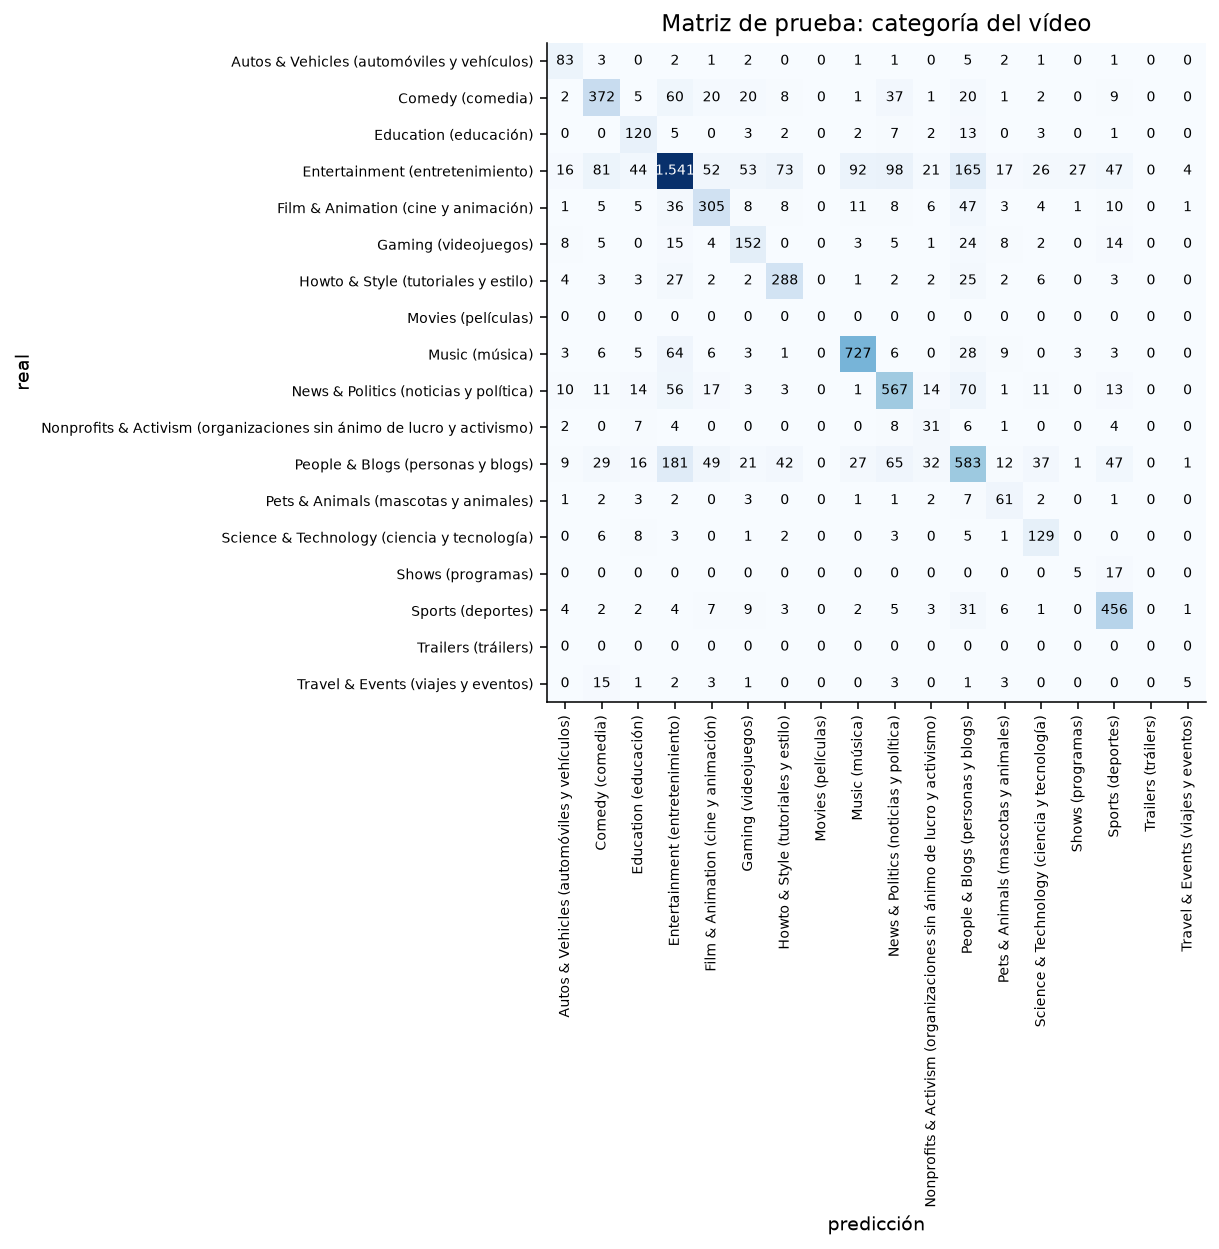

<details><summary>Confusiones entre categorías: categoría del vídeo</summary>

**Lectura por categoría.** Soporte = casos reales; precisión = aciertos / predicciones de esa categoría; recuperación = aciertos / casos reales. La tabla conserva todas las categorías, incluso las ausentes.

| Categoría | Soporte real | Predicciones | Aciertos | Precisión | Recuperación | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Autos &amp; Vehicles (automóviles y vehículos) | 102 | 143 | 83 | 58,04 % | 81,37 % | 0,6776 |
| Comedy (comedia) | 558 | 540 | 372 | 68,89 % | 66,67 % | 0,6776 |
| Education (educación) | 158 | 233 | 120 | 51,50 % | 75,95 % | 0,6138 |
| Entertainment (entretenimiento) | 2.357 | 2.002 | 1.541 | 76,97 % | 65,38 % | 0,7070 |
| Film &amp; Animation (cine y animación) | 459 | 466 | 305 | 65,45 % | 66,45 % | 0,6595 |
| Gaming (videojuegos) | 241 | 281 | 152 | 54,09 % | 63,07 % | 0,5824 |
| Howto &amp; Style (tutoriales y estilo) | 370 | 430 | 288 | 66,98 % | 77,84 % | 0,7200 |
| Movies (películas) | 0 | 0 | 0 | no estimable | sin soporte | 0,0000 |
| Music (música) | 864 | 869 | 727 | 83,66 % | 84,14 % | 0,8390 |
| News &amp; Politics (noticias y política) | 791 | 816 | 567 | 69,49 % | 71,68 % | 0,7057 |
| Nonprofits &amp; Activism (organizaciones sin ánimo de lucro y activismo) | 63 | 115 | 31 | 26,96 % | 49,21 % | 0,3483 |
| People &amp; Blogs (personas y blogs) | 1.152 | 1.030 | 583 | 56,60 % | 50,61 % | 0,5344 |
| Pets &amp; Animals (mascotas y animales) | 86 | 127 | 61 | 48,03 % | 70,93 % | 0,5728 |
| Science &amp; Technology (ciencia y tecnología) | 158 | 224 | 129 | 57,59 % | 81,65 % | 0,6754 |
| Shows (programas) | 22 | 37 | 5 | 13,51 % | 22,73 % | 0,1695 |
| Sports (deportes) | 536 | 626 | 456 | 72,84 % | 85,07 % | 0,7849 |
| Trailers (tráilers) | 0 | 0 | 0 | no estimable | sin soporte | 0,0000 |
| Travel &amp; Events (viajes y eventos) | 34 | 12 | 5 | 41,67 % | 14,71 % | 0,2174 |

F1 muestra el cero convencional del informe cuando no es estimable; no implica fracaso observado si falta soporte. Precisión puede ser cero estimable cuando se predice una clase que nunca es la real.

**Hasta 5 confusiones con más casos** (real → predicha; porcentaje sobre la fila real):
- People &amp; Blogs (personas y blogs) → Entertainment (entretenimiento): 181 de 1.152, 15,71 %.
- Entertainment (entretenimiento) → People &amp; Blogs (personas y blogs): 165 de 2.357, 7,00 %.
- Entertainment (entretenimiento) → News &amp; Politics (noticias y política): 98 de 2.357, 4,16 %.
- Entertainment (entretenimiento) → Music (música): 92 de 2.357, 3,90 %.
- Entertainment (entretenimiento) → Comedy (comedia): 81 de 2.357, 3,44 %.

**Hasta 5 confusiones con mayor fracción de la clase real**, entre las 16 clases con soporte de al menos 20 apariciones. Este filtro es descriptivo, no selecciona modelos; las demás clases siguen en la tabla.
- Shows (programas) → Sports (deportes): 77,27 %, 17 de 22.
- Travel &amp; Events (viajes y eventos) → Comedy (comedia): 44,12 %, 15 de 34.
- People &amp; Blogs (personas y blogs) → Entertainment (entretenimiento): 15,71 %, 181 de 1.152.
- Nonprofits &amp; Activism (organizaciones sin ánimo de lucro y activismo) → News &amp; Politics (noticias y política): 12,70 %, 8 de 63.
- Nonprofits &amp; Activism (organizaciones sin ánimo de lucro y activismo) → Education (educación): 11,11 %, 7 de 63.

Las flechas tienen dirección: A → B no equivale a B → A y sus denominadores pueden diferir. La matriz normalizada por fila divide por el soporte real; una fila sin soporte se marca sin datos, no como 0 % de errores. No se suman porcentajes de filas distintas.
**Conclusión.** La confusión con más casos es People &amp; Blogs (personas y blogs) → Entertainment (entretenimiento): 181 errores. Revisar ejemplos de esa pareja es una prioridad concreta para estudiar el texto y la consistencia de las etiquetas.
Shows (programas) → Sports (deportes) es compatible con programas deportivos que encajan en ambas etiquetas; es una hipótesis editorial para revisar ejemplos, no contenido confirmado.
Estos resultados describen confusiones, no explican su causa. La repetición de vídeos, canales, idiomas y el etiquetado editorial limitan la interpretación. No se cambian familias, parámetros ni umbrales tras mirar la prueba.

</details>

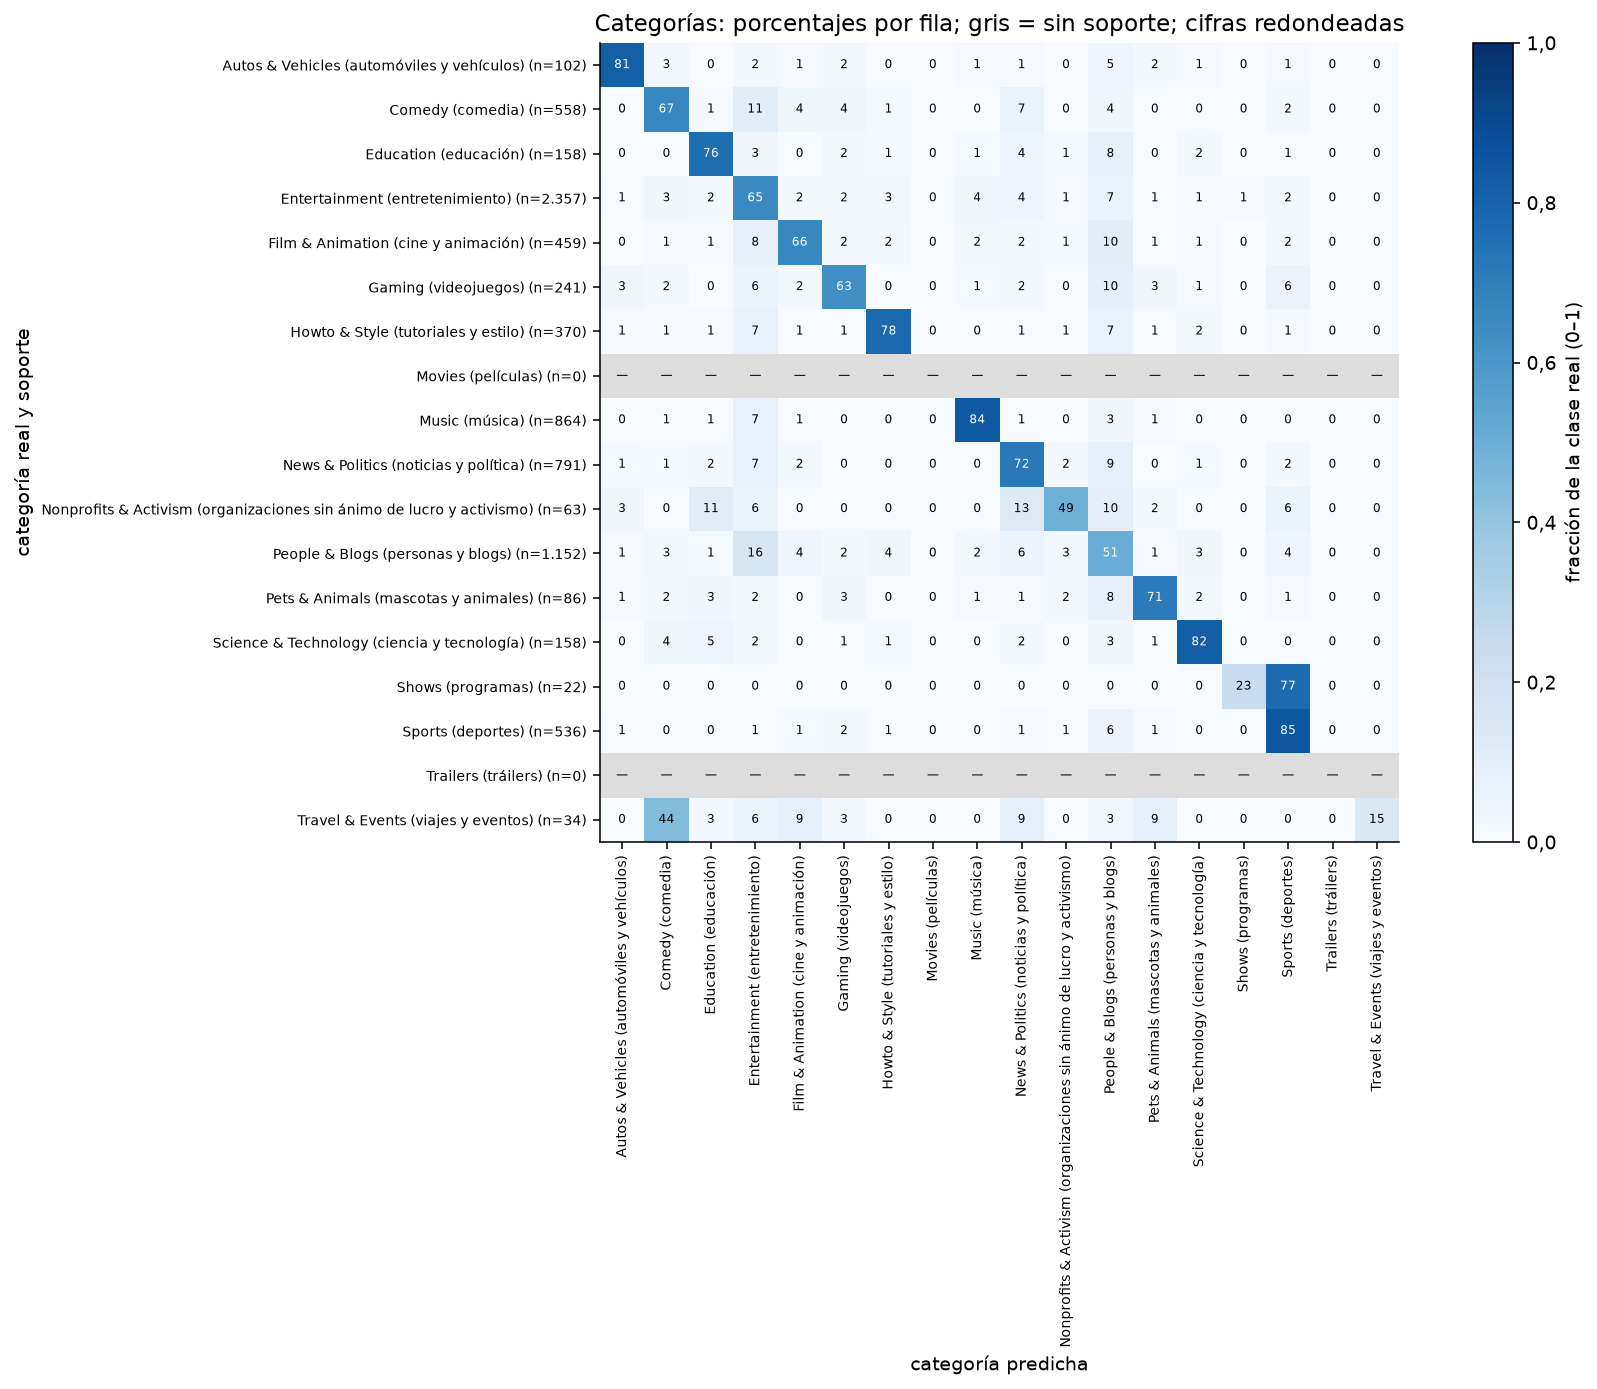

<details><summary>Lectura de coeficientes: categoría del vídeo</summary>

**Coeficientes: categoría del vídeo.** 270 pesos exportados para 18 clases/salidas. Se conserva hasta 15 por clase/salida, ordenados por valor absoluto; no es el vector completo y la ausencia de un atributo no prueba peso cero.

text__ identifica TF-IDF del contenido combinado, no necesariamente una palabra del título; num__ usa variables imputadas, transformadas con log1p y escaladas; cat__ identifica indicadores de región. Los pesos no están en la escala de las columnas originales.

SVM lineal: el peso modifica la puntuación de decisión de la salida correspondiente. Un peso positivo eleva esa puntuación al aumentar ese atributo transformado, manteniendo los demás fijos; no es una probabilidad.

Ejemplos de hasta tres categorías con mayor soporte real entre las exportadas; el extracto completo queda en el detalle. Cada salida tiene su propio vector, no una importancia global común.

Salida Entertainment (entretenimiento): `text__entertainment` = 2,1525; `text__trailers` = -1,7315; `text__ncast` = 1,7090.

En el extracto de esta salida: pesos positivos 14, negativos 1, ceros 0. Estos recuentos no describen todos los pesos del modelo.

Salida People & Blogs (personas y blogs): `text__jeremstar` = 2,2131; `text__shin` = 1,9791; `text__nмоя` = 1,9410.

En el extracto de esta salida: pesos positivos 13, negativos 2, ceros 0. Estos recuentos no describen todos los pesos del modelo.

Salida Music (música): `text__lnk` = 3,1597; `text__album` = 2,4104; `text__lyrics` = 2,4081.

En el extracto de esta salida: pesos positivos 15, negativos 0, ceros 0. Estos recuentos no describen todos los pesos del modelo.

Un peso negativo reduce esa puntuación o respuesta transformada, no implica efecto perjudicial. La contribución de un caso requiere peso × valor transformado, más intercepto y el resto de atributos. TF-IDF se normaliza: añadir una palabra puede cambiar otras coordenadas; los atributos están relacionados.

No se comparan magnitudes entre escalas o modelos como importancia universal, ni se concluye causalidad por términos, canales o regiones.

La clasificación multiclase compara puntuaciones de varias salidas; elevar una no garantiza cambiar la etiqueta final.

**Lectura conjunta.** Los términos también pueden recoger nombres propios y plantillas recurrentes de creadores. El diagnóstico por canales disjuntos (apartado de calidad) comprueba si el rendimiento se mantiene al cambiar ese contexto; un coeficiente aislado no demuestra memorización.

No se reajusta el modelo mirando estas asociaciones.

</details>

,class,atributo,coefficient
0,Autos & Vehicles (automóviles y vehículos),text__bmw,"3,322083"
1,Autos & Vehicles (automóviles y vehículos),text__audi,"2,671467"
2,Autos & Vehicles (automóviles y vehículos),text__авто,"2,304103"
3,Autos & Vehicles (automóviles y vehículos),text__car,"2,265523"
4,Autos & Vehicles (automóviles y vehículos),text__oubliez,"2,151845"
5,Autos & Vehicles (automóviles y vehículos),text__nмоя,"-2,133332"
6,Autos & Vehicles (automóviles y vehículos),text__tesla,"2,097093"
7,Autos & Vehicles (automóviles y vehículos),text__twitter,"-2,062309"
8,Autos & Vehicles (automóviles y vehículos),text__crash,"2,022755"
9,Autos & Vehicles (automóviles y vehículos),text__road,"2,02166"


### comentarios desactivados · seleccionado: svm

Macro-F1 de prueba 0,670, referencia 0,495. Detecta 66 de 142 positivos reales: recuperación 46,48 %; precisión positiva 28,82 %. No son porcentajes de exactitud global.

,train,reserva de prueba,baseline_holdout
macro_f1,"0,978074","0,670203","0,495495"
balanced_accuracy,"0,987087","0,721958","0,5"


**Conclusión para comentarios desactivados.** Con **953,7** → **3.970,0** filas medias de ajuste por partición, el macro-F1 de validación pasa de **0,5049** a **0,5949**. Se observa mejora dentro del rango medido; merece contrastar una muestra mayor mediante validación de desarrollo, sin extrapolar una ganancia fuera de ese rango.

<details><summary>Interpretación de la curva: comentarios desactivados</summary>

**Curva de aprendizaje: comentarios desactivados.** 3 tamaños y 3 particiones. Eje X: media de filas efectivas de ajuste por partición, de 953,7 a 3.970,0; no es el número de vídeos ni el tamaño del ajuste final.

Validación macro-F1: 0,5049 → 0,5949; aumenta. Mayor es mejor: mejora numérica entre extremos. Pasos consecutivos favorables: 2 de 2; no se presupone una evolución monótona.

En el último tamaño, entrenamiento 0,9935 y validación 0,5949. Brecha orientada para que un valor positivo indique ventaja del entrenamiento: 0,3986. Es un diagnóstico condicionado a los datos y al protocolo, no una prueba aislada de sobreajuste.

Barras: media de validación ± desviación entre particiones, calculada con ddof=0; última desviación 0,0630. 

</details>

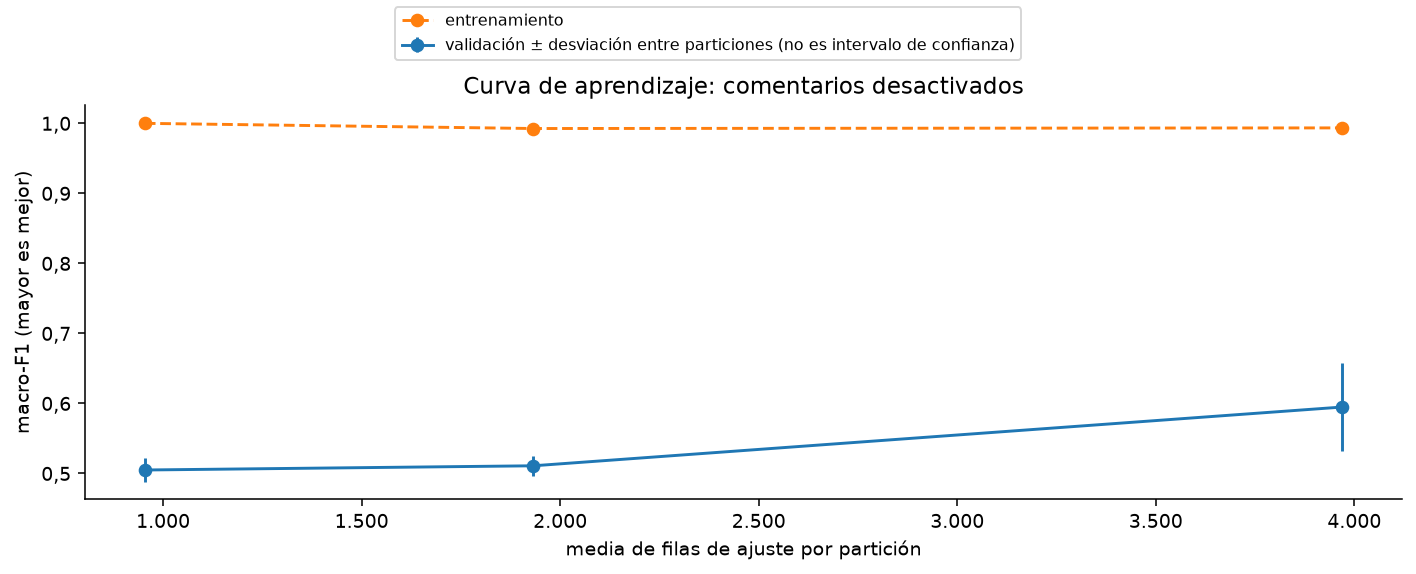

<details><summary>Interpretación regional: comentarios desactivados</summary>

**Diagnóstico regional: comentarios desactivados.** 10 regiones y 7.951 apariciones; soportes entre 339 y 955. Son filas de prueba, no vídeos únicos ni personas de esas nacionalidades.

Valor menos favorable entre las elegibles: US, balanced_accuracy 0,4981, n=792. 

Clases con casos reales por región: entre 1 y 2, de 2 etiquetas declaradas. Exactitud equilibrada promedia recuperación sólo de clases presentes; esos conjuntos pueden diferir entre regiones.

Soporte positivo real por región: CA=12; DE=22; FR=18; GB=0; IN=19; JP=17; KR=8; MX=10; RU=23; US=13.

Sin positivos reales: GB. Una exactitud equilibrada alta o perfecta en esas regiones no demuestra detección de la clase 1; la recuperación de positivos no se puede estimar.

</details>

,region,rows,macro_f1,balanced_accuracy
,region,rows,F1 medio con igual peso por clase,exactitud equilibrada
0,CA,834,"0,660562","0,700426"
1,DE,834,"0,760197","0,765954"
2,FR,955,"0,755872","0,90386"
3,GB,858,"0,488982","0,956876"
4,IN,788,"0,625124","0,667956"
5,JP,339,"0,714337","0,74452"
6,KR,702,"0,567112","0,558898"
7,MX,948,"0,695991","0,74467"
8,RU,901,"0,701071","0,748341"


<details><summary>Interpretación completa de clasificación: comentarios desactivados</summary>

**Lectura de clasificación: comentarios desactivados.** Filas = clase real; columnas = predicción, en el orden ['0', '1'].

Diagonal: 7.712 aciertos de 7.951 apariciones; fuera de la diagonal: 239 errores. Exactitud 96,99 %. No son necesariamente vídeos distintos.

Macro-F1 0,6702: media de F1 sobre 2 etiquetas declaradas. Exactitud equilibrada 0,7220: media de la recuperación de las 2 clases con casos reales. No equivale al porcentaje global de aciertos.

Clase positiva 1 = función desactivada. VN=7.646, FP=163, FN=76, VP=66. Positivos reales: 142; positivos predichos: 229.

Precisión positiva = VP/(VP+FP): 28,82 %. Recuperación de positivos = VP/(VP+FN): 46,48 %. F1 positivo 0,3558; macro-F1 también incluye F1 de la clase 0.

Predecir siempre 0 acertaría 98,21 % en esta prueba, pero detectaría 0 positivos. Es una ilustración del desequilibrio; no sustituye la referencia sencilla entrenada ni elige otro umbral.

</details>

,precision,recall,f1-score,support
,precisión de positivos,recuperación de casos reales,F1,casos reales
0,"0,990158","0,979127","0,984611",7.809
1,"0,28821","0,464789","0,355795",142
exactitud global,"0,969941","0,969941","0,969941","0,969941"
media por clase,"0,639184","0,721958","0,670203",7.951
media ponderada por casos,"0,977622","0,969941","0,973381",7.951


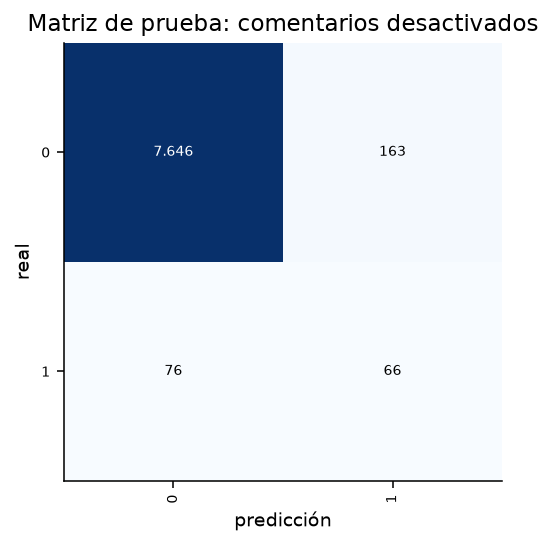

<details><summary>Lectura de coeficientes: comentarios desactivados</summary>

**Coeficientes: comentarios desactivados.** 15 pesos exportados para 1 clases/salidas. Se conserva hasta 15 por clase/salida, ordenados por valor absoluto; no es el vector completo y la ausencia de un atributo no prueba peso cero.

Salida 1: `text__grosse` = 2,4929; `text__mhonividente` = 2,4618; `text__rama` = 2,3940.

En clasificación binaria, la etiqueta depende de la puntuación o probabilidad y del umbral de decisión; cambiar una contribución no garantiza cruzar ese umbral.

</details>

,class,atributo,coefficient
0,1,text__grosse,"2,492935"
1,1,text__mhonividente,"2,461796"
2,1,text__rama,"2,393973"
3,1,text__enemigo,"2,18885"
4,1,text__eng,"2,171797"
5,1,text__дар,"2,165722"
6,1,text__gummadi,"2,043508"
7,1,text__свобода,"2,033886"
8,1,text__abntelugutv,"2,022931"
9,1,text__곤지암,"1,955128"


### valoraciones desactivadas · seleccionado: logistic

Macro-F1 de prueba 0,591, referencia 0,495. Detecta 65 de 156 positivos reales: recuperación 41,67 %; precisión positiva 14,41 %. No son porcentajes de exactitud global.

,train,reserva de prueba,baseline_holdout
macro_f1,"0,7268","0,591491","0,495046"
balanced_accuracy,"0,970606","0,683574","0,5"


**Conclusión para valoraciones desactivadas.** Con **950,7** → **3.970,0** filas medias de ajuste por partición, el macro-F1 de validación pasa de **0,5103** a **0,5555**. Se observa mejora dentro del rango medido; merece contrastar una muestra mayor mediante validación de desarrollo, sin extrapolar una ganancia fuera de ese rango.

<details><summary>Interpretación de la curva: valoraciones desactivadas</summary>

**Curva de aprendizaje: valoraciones desactivadas.** 3 tamaños y 3 particiones. Eje X: media de filas efectivas de ajuste por partición, de 950,7 a 3.970,0; no es el número de vídeos ni el tamaño del ajuste final.

Validación macro-F1: 0,5103 → 0,5555; aumenta. Mayor es mejor: mejora numérica entre extremos. Pasos consecutivos favorables: 2 de 2; no se presupone una evolución monótona.

En el último tamaño, entrenamiento 0,7752 y validación 0,5555. Brecha orientada para que un valor positivo indique ventaja del entrenamiento: 0,2197. Es un diagnóstico condicionado a los datos y al protocolo, no una prueba aislada de sobreajuste.

Barras: media de validación ± desviación entre particiones, calculada con ddof=0; última desviación 0,0237. 

</details>

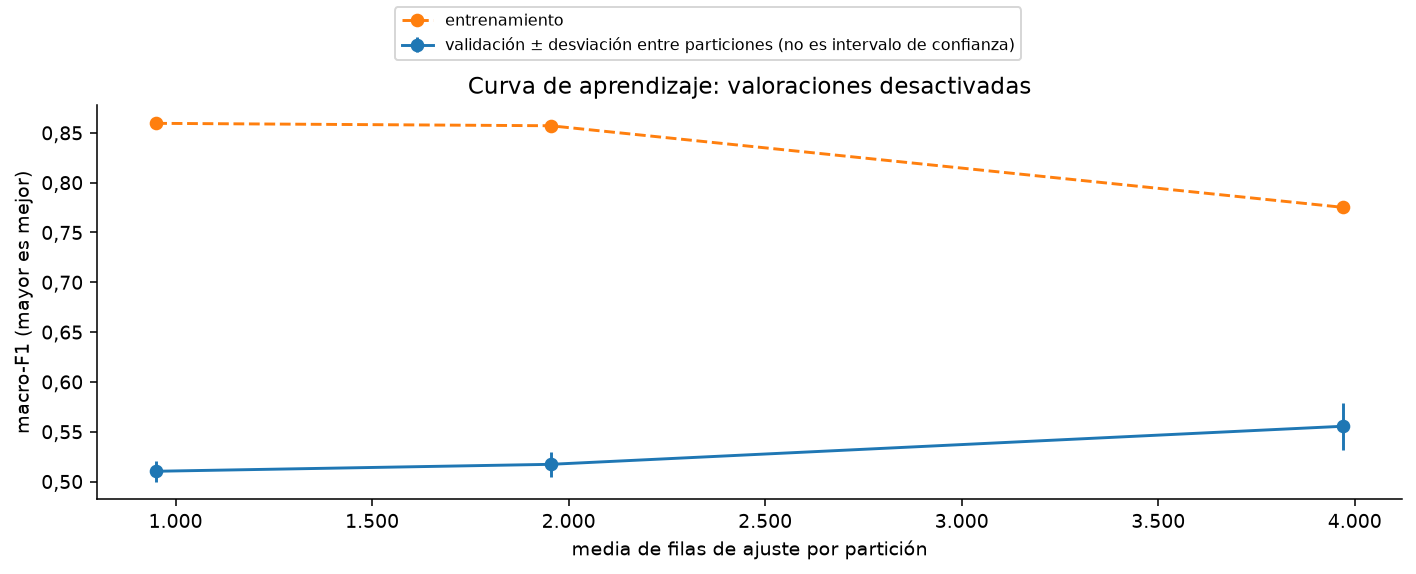

<details><summary>Interpretación regional: valoraciones desactivadas</summary>

**Diagnóstico regional: valoraciones desactivadas.** 10 regiones y 7.951 apariciones; soportes entre 339 y 955. Son filas de prueba, no vídeos únicos ni personas de esas nacionalidades.

Valor menos favorable entre las elegibles: CA, balanced_accuracy 0,4994, n=834. 

Soporte positivo real por región: CA=6; DE=19; FR=14; GB=0; IN=7; JP=20; KR=44; MX=14; RU=28; US=4.

</details>

,region,rows,macro_f1,balanced_accuracy
,region,rows,F1 medio con igual peso por clase,exactitud equilibrada
0,CA,834,"0,497893","0,499396"
1,DE,834,"0,722754","0,705618"
2,FR,955,"0,578969","0,628511"
3,GB,858,"0,5",1
4,IN,788,"0,638034","0,707243"
5,JP,339,"0,448464","0,622806"
6,KR,702,"0,508454","0,553502"
7,MX,948,"0,669944","0,773402"
8,RU,901,"0,627409","0,749632"


<details><summary>Interpretación completa de clasificación: valoraciones desactivadas</summary>

**Lectura de clasificación: valoraciones desactivadas.** Filas = clase real; columnas = predicción, en el orden ['0', '1'].

Diagonal: 7.474 aciertos de 7.951 apariciones; fuera de la diagonal: 477 errores. Exactitud 94,00 %. No son necesariamente vídeos distintos.

Macro-F1 0,5915: media de F1 sobre 2 etiquetas declaradas. Exactitud equilibrada 0,6836: media de la recuperación de las 2 clases con casos reales. No equivale al porcentaje global de aciertos.

Clase positiva 1 = función desactivada. VN=7.409, FP=386, FN=91, VP=65. Positivos reales: 156; positivos predichos: 451.

Precisión positiva = VP/(VP+FP): 14,41 %. Recuperación de positivos = VP/(VP+FN): 41,67 %. F1 positivo 0,2142; macro-F1 también incluye F1 de la clase 0.

Predecir siempre 0 acertaría 98,04 % en esta prueba, pero detectaría 0 positivos. Es una ilustración del desequilibrio; no sustituye la referencia sencilla entrenada ni elige otro umbral.

</details>

,precision,recall,f1-score,support
,precisión de positivos,recuperación de casos reales,F1,casos reales
0,"0,987867","0,950481","0,968813",7.795
1,"0,144124","0,416667","0,214168",156
exactitud global,"0,940008","0,940008","0,940008","0,940008"
media por clase,"0,565995","0,683574","0,591491",7.951
media ponderada por casos,"0,971312","0,940008","0,954007",7.951


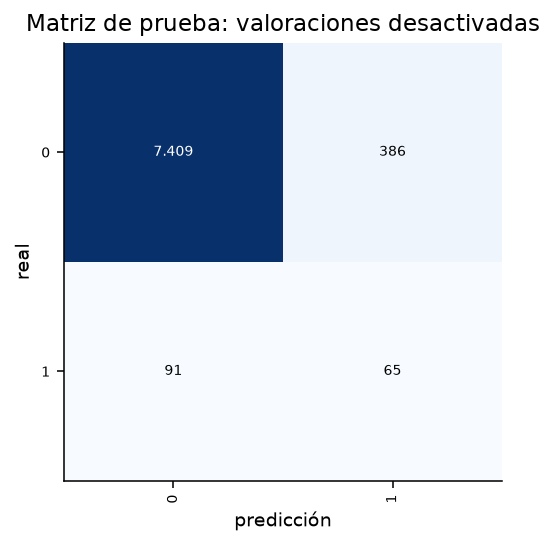

<details><summary>Lectura de coeficientes: valoraciones desactivadas</summary>

**Coeficientes: valoraciones desactivadas.** 15 pesos exportados para 1 clases/salidas. Se conserva hasta 15 por clase/salida, ordenados por valor absoluto; no es el vector completo y la ausencia de un atributo no prueba peso cero.

Regresión logística: los pesos modifican los log-odds de la clase positiva; la función logística los convierte en probabilidad estimada. El coeficiente no es un cambio directo de probabilidad. El umbral OOF decide después y no altera estos pesos.

Salida 1: `text__hilton` = 5,2491; `text__girona` = 4,9893; `text__лайк` = 4,7131.

</details>

,class,atributo,coefficient
0,1,text__hilton,"5,249144"
1,1,text__girona,"4,989308"
2,1,text__лайк,"4,713121"
3,1,text__ntv,"4,624611"
4,1,text__instagram,"-4,580396"
5,1,text__gossips,"4,534033"
6,1,text__malayalam,"4,444326"
7,1,text__tout,"4,42595"
8,1,text__kalk,"4,269348"
9,1,text__gidelim,"4,269348"


### número de «me gusta» · seleccionado: svr_log_target

MAE de prueba 14.202,119 frente a 57.088,142 de referencia; R² 0,957. Es una estimación en la escala declarada, no garantía de precisión para cada vídeo.

,train,reserva de prueba,baseline_holdout
mae,"4.504,118423","14.202,118962","57.088,142435"
rmse,"20.383,469797","67.497,261487","329.298,5689"
r2,"0,982106","0,956814","-0,0279"


**Conclusión para número de «me gusta».** Con **958,3** → **3.970,0** filas medias de ajuste por partición, el MAE de validación pasa de **9.655,73** a **9.178,76**. Se observa mejora dentro del rango medido; merece contrastar una muestra mayor mediante validación de desarrollo, sin extrapolar una ganancia fuera de ese rango.

<details><summary>Interpretación de la curva: número de «me gusta»</summary>

**Curva de aprendizaje: número de «me gusta».** 3 tamaños y 3 particiones. Eje X: media de filas efectivas de ajuste por partición, de 958,3 a 3.970,0; no es el número de vídeos ni el tamaño del ajuste final.

Validación MAE: 9.655,7313 → 9.178,7625; disminuye. Menor es mejor: mejora numérica entre extremos. Pasos consecutivos favorables: 2 de 2; no se presupone una evolución monótona.

En el último tamaño, entrenamiento 3.539,9235 y validación 9.178,7625. Brecha orientada para que un valor positivo indique ventaja del entrenamiento: 5.638,8390. Es un diagnóstico condicionado a los datos y al protocolo, no una prueba aislada de sobreajuste.

Barras: media de validación ± desviación entre particiones, calculada con ddof=0; última desviación 1.390,8962. 

</details>

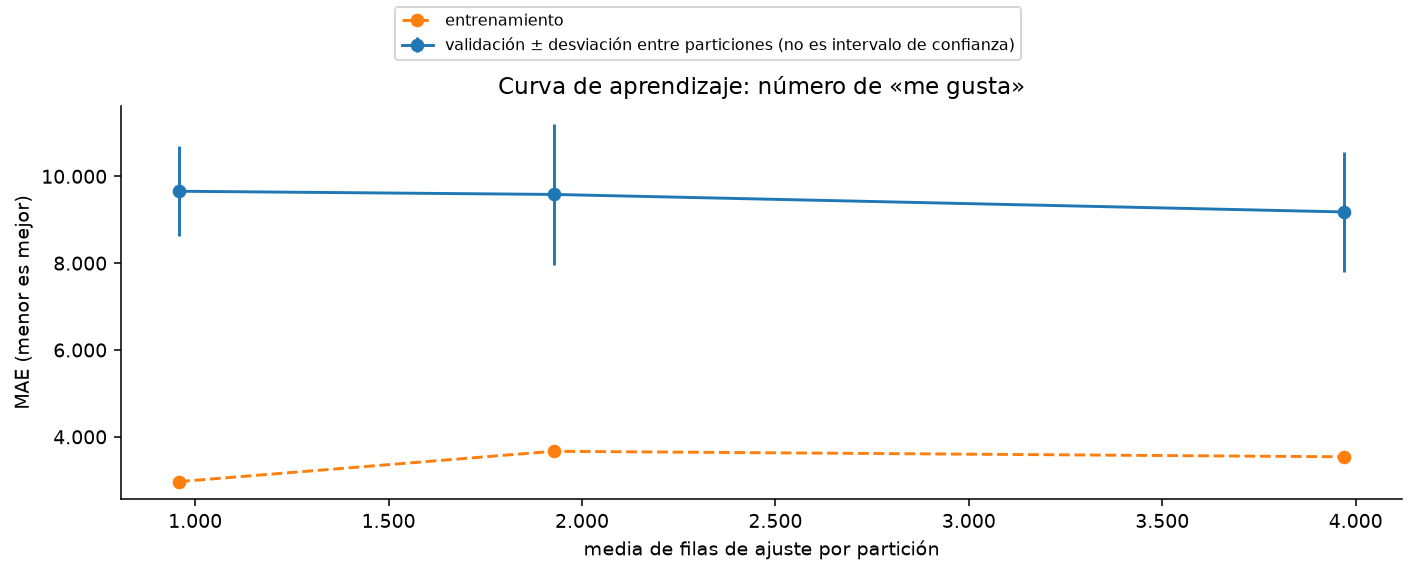

<details><summary>Interpretación regional: número de «me gusta»</summary>

**Diagnóstico regional: número de «me gusta».** 10 regiones y 7.951 apariciones; soportes entre 339 y 955. Son filas de prueba, no vídeos únicos ni personas de esas nacionalidades.

Comparación descriptiva por mae: menor es favorable. Regiones con al menos 100 filas: 10. El filtro no garantiza soporte de cada clase, independencia ni significación estadística.

Valor menos favorable entre las elegibles: GB, mae 44.545,6479, n=858. 

MAE global se reconstruye ponderando los MAE regionales por filas; RMSE global requiere raíz de la media ponderada de RMSE². R² global no es el promedio de los R² regionales: las medias y dispersiones locales difieren. Un MAE regional alto puede coexistir con R² alto.

</details>

,region,rows,mae,rmse,r2
,region,rows,error absoluto medio,raíz del error cuadrático medio,coeficiente de determinación
0,CA,834,"18.246,741699","71.761,274436","0,939896"
1,DE,834,"11.042,498199","55.689,484618","0,937548"
2,FR,955,"6.055,930661","34.449,395965","0,899979"
3,GB,858,"44.545,647931","128.925,647319","0,971855"
4,IN,788,"10.753,749324","50.678,089854","0,957184"
5,JP,339,"3.445,148328","29.461,86502","0,707887"
6,KR,702,"15.020,669665","102.423,653208","0,84246"
7,MX,948,"6.511,650026","31.205,824116","0,959715"
8,RU,901,"4.122,632539","20.129,62899","0,891325"


<details><summary>Interpretación completa de regresión: número de «me gusta»</summary>

**Lectura de regresión: número de «me gusta».** 7.951 apariciones de prueba. MAE y RMSE están en la escala original: likes; no son errores en logaritmos ni porcentajes.

MAE 14.202,12: media de las distancias absolutas entre valor real y predicción. No es la mediana del error ni garantiza que cada caso quede dentro de ese margen.

RMSE 67.497,26: raíz de la media de los errores al cuadrado. Da más peso a errores grandes; su distancia respecto al MAE no permite contar cuántos extremos hay sin mirar los casos.

Frente a la referencia de mediana del ajuste, evaluada sobre las mismas filas (MAE 57.088,14), el MAE disminuye. Reducción absoluta referencia − modelo: 42.886,02; reducción relativa: 75,12 %. Un valor negativo indica empeoramiento; no es un porcentaje de aciertos.

R² 0,9568: 1 − SSE/SST, respecto al predictor constante igual a la media de los valores reales de esta prueba. Es un denominador matemático de evaluación; no se usa esa media para entrenar el modelo ni la referencia sencilla de mediana.

R² no es el porcentaje de predicciones correctas ni una garantía de error pequeño. Con un objetivo constante SST=0 y con menos de dos casos la definición habitual requiere tratamiento especial; estos valores agregados no permiten diagnosticar por sí solos esas situaciones.

Estas magnitudes no se comparan directamente entre likes y ratio porque sus unidades y escalas son distintas. Describen modelos ya fijados sobre una prueba interna ya examinada; no justifican reoptimizar con sus etiquetas.

</details>

**Conclusión.** Las **100** apariciones de **3** vídeos concentran **48,10 %** del error absoluto y **89,53 %** del cuadrático. Un conjunto reducido de identidades pesa mucho en las métricas por aparición; el error cuadrático es especialmente sensible a esos casos. Conviene comprobar también métricas por vídeo en una futura evaluación, sin retirar ahora los errores difíciles de la prueba.

<details><summary>Lectura de los mayores errores: número de «me gusta»</summary>

**Casos con errores grandes: número de «me gusta».** El CSV contiene 100 apariciones ordenadas por error absoluto, de 7.951 apariciones de prueba (1,26 %). Vídeos distintos representados: 3; repetir un video_id no convierte dos apariciones en duplicados inválidos.

Distribución en estas filas: sobreestimaciones = 15; subestimaciones = 85; coincidencias exactas = 0. No es un balance del conjunto de prueba: la lista está seleccionada por magnitud de error.

Mayor error de la lista: vídeo xpVfcZ0ZcFM, región GB; real 4.737.873,00, predicción 5.788.202,64, diferencia predicción − real 1.050.329,64 y error absoluto 1.050.329,64.

Estas filas reúnen el 48,10 % de la suma de errores absolutos de toda la prueba. El denominador es MAE × número de filas, no sólo el error de esta lista.

Reúnen el 89,53 % de la suma de errores cuadrados total (RMSE² × número de filas). Es una participación en esa suma, no en el RMSE ni en la varianza del objetivo.

La tabla visible presenta hasta ocho filas y añade diferencia predicción − real. El signo distingue exceso y defecto; absolute_error mide la distancia. La lista completa sigue en el CSV. No se eliminan estos casos ni se cambia el modelo para mejorar esta prueba; tampoco se atribuye una causa sin revisar los datos originales.

</details>

,video_id,region,title,category,actual,predicted,absolute_error,prediction_minus_actual
0,xpVfcZ0ZcFM,GB,Drake - God’s Plan,Music (música),4.737.873,"5.788.202,642821","1.050.329,642821","1.050.329,642821"
1,xpVfcZ0ZcFM,GB,Drake - God’s Plan,Music (música),4.677.278,"5.661.656,00226","984.378,00226","984.378,00226"
2,xpVfcZ0ZcFM,GB,Drake - God’s Plan,Music (música),4.618.024,"5.545.978,484828","927.954,484828","927.954,484828"
3,6ZfuNTqbHE8,KR,Marvel Studios' Avengers: Infinity War Official Trailer,Entertainment (entretenimiento),2.331.367,"1.406.776,477839","924.590,522161","-924.590,522161"
4,6ZfuNTqbHE8,KR,Marvel Studios' Avengers: Infinity War Official Trailer,Entertainment (entretenimiento),2.331.363,"1.406.776,477839","924.586,522161","-924.586,522161"
5,6ZfuNTqbHE8,KR,Marvel Studios' Avengers: Infinity War Official Trailer,Entertainment (entretenimiento),2.444.965,"1.524.781,269835","920.183,730165","-920.183,730165"
6,6ZfuNTqbHE8,KR,Marvel Studios' Avengers: Infinity War Official Trailer,Entertainment (entretenimiento),2.513.104,"1.593.027,820075","920.076,179925","-920.076,179925"
7,6ZfuNTqbHE8,KR,Marvel Studios' Avengers: Infinity War Official Trailer,Entertainment (entretenimiento),2.555.414,"1.639.542,486094","915.871,513906","-915.871,513906"


... (3 outputs left out)

MAE de prueba 26,984 frente a 32,116 de referencia; R² 0,132. Es una estimación en la escala declarada, no garantía de precisión para cada vídeo.

,train,reserva de prueba,baseline_holdout
mae,"15,670818","26,984148","32,11572"
rmse,"51,414346","61,944069","69,171344"
r2,"0,407046","0,132387","-0,08188"


**Conclusión para proporción «me gusta/no me gusta».** Con **934,0** → **3.884,7** filas medias de ajuste por partición, el MAE de validación pasa de **27,45** a **26,46**. Se observa mejora dentro del rango medido; merece contrastar una muestra mayor mediante validación de desarrollo, sin extrapolar una ganancia fuera de ese rango.

<details><summary>Interpretación de la curva: proporción «me gusta/no me gusta»</summary>

**Curva de aprendizaje: proporción «me gusta/no me gusta».** 3 tamaños y 3 particiones. Eje X: media de filas efectivas de ajuste por partición, de 934,0 a 3.884,7; no es el número de vídeos ni el tamaño del ajuste final.

Validación MAE: 27,4509 → 26,4568; disminuye. Menor es mejor: mejora numérica entre extremos. Pasos consecutivos favorables: 2 de 2; no se presupone una evolución monótona.

En el último tamaño, entrenamiento 13,0248 y validación 26,4568. Brecha orientada para que un valor positivo indique ventaja del entrenamiento: 13,4320. Es un diagnóstico condicionado a los datos y al protocolo, no una prueba aislada de sobreajuste.

Barras: media de validación ± desviación entre particiones, calculada con ddof=0; última desviación 2,7475. 

</details>

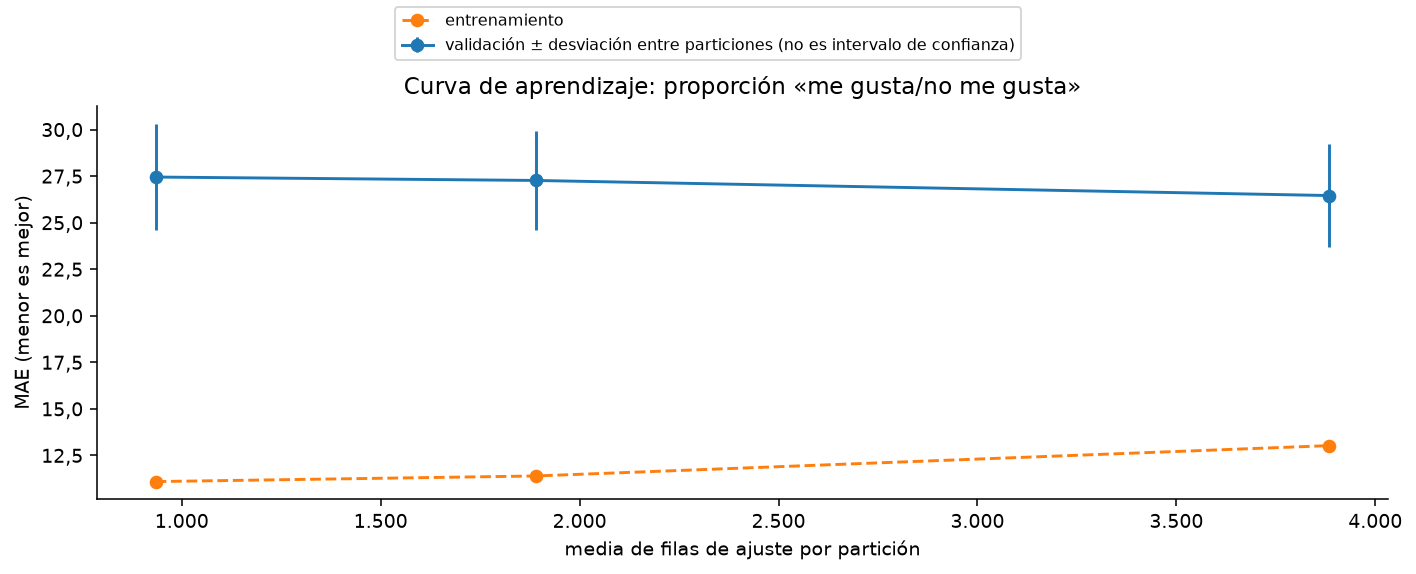

<details><summary>Interpretación regional: proporción «me gusta/no me gusta»</summary>

**Diagnóstico regional: proporción «me gusta/no me gusta».** 10 regiones y 7.733 apariciones; soportes entre 309 y 926. Son filas de prueba, no vídeos únicos ni personas de esas nacionalidades.

Valor menos favorable entre las elegibles: GB, mae 36,4311, n=858. 

</details>

,region,rows,mae,rmse,r2
,region,rows,error absoluto medio,raíz del error cuadrático medio,coeficiente de determinación
0,CA,826,"28,06949","64,486631","0,142165"
1,DE,807,"24,854795","53,819399","0,152425"
2,FR,926,"30,926576","65,217239","0,182717"
3,GB,858,"36,431059","80,768466","-0,104702"
4,IN,780,"8,906993","14,363853","0,312276"
5,JP,309,"30,580421","113,148416","0,124053"
6,KR,654,"32,745511","74,471191","0,133641"
7,MX,925,"25,96274","50,833624","0,299509"
8,RU,863,"21,209811","43,087022","0,074554"


<details><summary>Interpretación completa de regresión: proporción «me gusta/no me gusta»</summary>

**Lectura de regresión: proporción «me gusta/no me gusta».** 7.733 apariciones de prueba. MAE y RMSE están en la escala original: unidades del cociente likes/dislikes (no puntos porcentuales); no son errores en logaritmos ni porcentajes.

MAE 26,98: media de las distancias absolutas entre valor real y predicción. No es la mediana del error ni garantiza que cada caso quede dentro de ese margen.

RMSE 61,94: raíz de la media de los errores al cuadrado. Da más peso a errores grandes; su distancia respecto al MAE no permite contar cuántos extremos hay sin mirar los casos.

Frente a la referencia de mediana del ajuste, evaluada sobre las mismas filas (MAE 32,12), el MAE disminuye. Reducción absoluta referencia − modelo: 5,13; reducción relativa: 15,98 %. Un valor negativo indica empeoramiento; no es un porcentaje de aciertos.

R² 0,1324: 1 − SSE/SST, respecto al predictor constante igual a la media de los valores reales de esta prueba. Es un denominador matemático de evaluación; no se usa esa media para entrenar el modelo ni la referencia sencilla de mediana.

</details>

**Conclusión para la proporción «me gusta/no me gusta».** En las **100** apariciones con mayor error, todas son subestimaciones: **100** predicciones por debajo del valor real y **0** por encima. Corresponden a **64** vídeos y aportan **17,91 %** del error absoluto total y **62,38 %** del cuadrático. El patrón describe esta cola seleccionada, no el signo de los errores de toda la prueba. La transformación logarítmica del objetivo y la regularización podrían contribuir a estimaciones menos extremas: es una hipótesis compatible con la receta, no una causa comprobada por esta tabla. Para confirmar un sesgo global haría falta examinar todos los residuos; estos casos no justifican elegir otra receta usando la prueba ni retirar sus errores difíciles.

<details><summary>Lectura de los mayores errores: proporción «me gusta/no me gusta»</summary>

**Casos con errores grandes: proporción «me gusta/no me gusta».** El CSV contiene 100 apariciones ordenadas por error absoluto, de 7.733 apariciones de prueba (1,29 %). Vídeos distintos representados: 64; repetir un video_id no convierte dos apariciones en duplicados inválidos.

Distribución en estas filas: sobreestimaciones = 0; subestimaciones = 100; coincidencias exactas = 0. No es un balance del conjunto de prueba: la lista está seleccionada por magnitud de error.

Mayor error de la lista: vídeo Zf31iJRRGoQ, región JP; real 1.837,50, predicción 113,78, diferencia predicción − real -1.723,72 y error absoluto 1.723,72.

Estas filas reúnen el 17,91 % de la suma de errores absolutos de toda la prueba. El denominador es MAE × número de filas, no sólo el error de esta lista.

Reúnen el 62,38 % de la suma de errores cuadrados total (RMSE² × número de filas). Es una participación en esa suma, no en el RMSE ni en la varianza del objetivo.

</details>

,video_id,region,title,category,actual,predicted,absolute_error,prediction_minus_actual
0,Zf31iJRRGoQ,JP,[TEASER] SEVENTEEN JAPAN 1ST MINI ALBUM「WE MAKE YOU」初回限定盤B Blu-ray,People & Blogs (personas y blogs),"1.837,5","113,783151","1.723,716849","-1.723,716849"
1,TFtDdO3gOi4,CA,Artists Design Fantasy Beer Label Shirts,Entertainment (entretenimiento),1.200,"61,517633","1.138,482367","-1.138,482367"
2,CGxpOtdlL58,FR,LA BELLE & LE CLOCHARD Low Cost (Alex Ramirès + Guests),Comedy (comedia),960,"39,233286","920,766714","-920,766714"
3,N6hVmn9FM7o,GB,Farewell.,Gaming (videojuegos),"849,083333","15,504525","833,578808","-833,578808"
4,N6hVmn9FM7o,GB,Farewell.,Gaming (videojuegos),817,"15,797213","801,202787","-801,202787"
5,N6hVmn9FM7o,GB,Farewell.,Gaming (videojuegos),"752,583333","15,552113","737,03122","-737,03122"
6,y_jqzsRHI_Q,DE,1 Random Copic Marker 🏆 Challenge PLUS,Howto & Style (tutoriales y estilo),829,"186,947891","642,052109","-642,052109"
7,1oZ4mkj084Y,KR,[이불 밖은 위험해 스페셜] 시우민의 깜짝 미니 생일 파티 현장,Entertainment (entretenimiento),671,"34,256072","636,743928","-636,743928"


<details><summary>Lectura de coeficientes: proporción «me gusta/no me gusta»</summary>

**Coeficientes: proporción «me gusta/no me gusta».** 15 pesos exportados para 1 clases/salidas. Se conserva hasta 15 por clase/salida, ordenados por valor absoluto; no es el vector completo y la ausencia de un atributo no prueba peso cero.

Salida ratio: `text__guardian` = -3,1126; `text__unge` = -2,8828; `text__seventeen` = 2,7629.

En el extracto de esta salida: pesos positivos 10, negativos 5, ceros 0. Estos recuentos no describen todos los pesos del modelo.

</details>

,class,atributo,coefficient
0,ratio,text__guardian,"-3,112619"
1,ratio,text__unge,"-2,882814"
2,ratio,text__seventeen,"2,762882"
3,ratio,text__peu,"2,558332"
4,ratio,text__reboot,"-2,506246"
5,ratio,text__sung,"2,387718"
6,ratio,text__patreon,"2,30892"
7,ratio,text__bts,"2,298467"
8,ratio,text__done,"-2,265931"
9,ratio,text__heaven,"2,174981"


In [13]:
# Presentación: un resultado breve por tarea y explicaciones completas bajo demanda.
from notebook_helpers import show_narrative_details
from results_report import task_evaluation_takeaway, evaluation_reading_guide, task_description
display(Markdown(evaluation_reading_guide()))
# shown_notes: cautelas generales ya desplegadas; se explican una vez y no se repiten en cada tarea.
shown_notes = set()
display(Markdown('Las cautelas generales de lectura (curvas, regiones, coeficientes y errores) se despliegan la primera vez que aparecen; '
                 'en las tareas siguientes sólo se muestran los párrafos con resultados propios.'))
# regional_supports: reconstruye la reserva canónica para contar clases reales por región.
regional_supports = regional_class_supports(ROOT, report)
for task,result in report['tasks'].items():
    # task_label: descripción de lectura; task conserva el identificador técnico de rutas.
    task_label = task_description(task)
    display(Markdown(f'### {task_label} · seleccionado: {result["selected"]}'))
    display(Markdown(task_evaluation_takeaway(task,result)))
    show_details(f'Métricas completas: {task_label}',pd.DataFrame({name:{k:v for k,v in result[name].items() if isinstance(v,(float,int))} for name in ['train','holdout','baseline_holdout']}))
    # curve: tabla de tamaños y puntuaciones de la curva de aprendizaje.
    show_narrative_details(f'Interpretación de la curva: {task_label}', learning_curve_summary(task, result, include_shared_notes=False), shown=shown_notes)
    curve=pd.DataFrame(result['learning_curve'])
    # fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos
    # y unidades explícitos.
    fig,ax=plt.subplots(layout='constrained')
    ax.errorbar(curve.mean_train_rows,curve.validation_mean,yerr=curve.validation_std,marker='o',label='validación ± desviación entre particiones (no es intervalo de confianza)')
    ax.plot(curve.mean_train_rows,curve.train_mean,'o--',label='entrenamiento')
    # La leyenda queda fuera de los datos y de sus barras de error.
    fig.legend(*ax.get_legend_handles_labels(), loc='outside upper center', fontsize=8)
    ax.set(title=f'Curva de aprendizaje: {task_label}',xlabel='media de filas de ajuste por partición',ylabel='macro-F1 (mayor es mejor)' if 'macro_f1' in result['holdout'] else 'MAE (menor es mejor)')
    show(f'learning_{task}')
    # regions: métricas ya calculadas sobre cada región de la reserva de prueba.
    regions = pd.read_csv(ROOT/f'reports/{task}_by_region.csv')
    show_narrative_details(f'Interpretación regional: {task_label}', regional_summary(task, result, regions, regional_supports, include_shared_notes=False), shown=shown_notes)
    show_details(f'Detalle por región y curva de aprendizaje: {task_label}', regions,
                 category_view(regional_supports.loc[regional_supports.task == task], 'label'), curve)
    if 'macro_f1' in result['holdout']:
        # classification_summary: interpreta y valida los recuentos sin cambiar decisiones.
        show_narrative_details(f'Interpretación completa de clasificación: {task_label}', category_notes(classification_summary(task, result['holdout'], include_shared_notes=False)), shown=shown_notes)
        show_details(f'Métricas por clase: {task_label}',
                     pd.DataFrame(result['holdout']['classification_report']).T.rename(index=category_label))
        # cm: matriz de confusión ordenada por las etiquetas declaradas.
        cm=np.array(result['holdout']['confusion_matrix'])
        # fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo
        # títulos y unidades explícitos.
        # im: imagen de calor usada para mostrar la matriz numérica.
        fig,ax=plt.subplots(figsize=(13, 9) if task == 'category' else (5, 4))
        im=ax.imshow(cm,cmap='Blues')
        # labels: orden de etiquetas que fija matrices y medias macro.
        labels=result['holdout']['labels']
        # labels_shown: texto bilingüe para los ejes, en el mismo orden que las etiquetas del modelo.
        labels_shown = [category_label(label) for label in labels]
        ax.set_xticks(range(len(labels)), labels_shown, rotation=90, fontsize=7)
        ax.set_yticks(range(len(labels)), labels_shown, fontsize=7)
        for i in range(len(cm)):
            for j in range(len(cm)):
                ax.text(j,i,format_number(cm[i,j], 0),ha='center',va='center',fontsize=7,
                        color='white' if cm.max() > 0 and cm[i,j] > cm.max()/2 else 'black')
        ax.set(xlabel='predicción',ylabel='real',title=f'Matriz de prueba: {task_label}')
        show(f'confusion_{task}')
        if task == 'category':
            show_narrative_details(f'Confusiones entre categorías: {task_label}', category_notes(category_confusion_summary(result['holdout'])), shown=shown_notes)
            # supports: número real de apariciones de cada categoría; una fila vacía no es evaluable.
            supports = cm.sum(axis=1)
            # normalized: fracciones por fila; sólo se divide cuando hay soporte real.
            normalized = np.divide(cm, supports[:, None], out=np.zeros_like(cm, dtype=float), where=supports[:, None] > 0)
            # masked: enmascara filas sin casos, para no presentarlas como rendimiento perfecto.
            masked = np.ma.masked_where(np.broadcast_to(supports[:, None] == 0, cm.shape), normalized)
            fig, ax = plt.subplots(figsize=(14, 10))
            # palette: gris para filas sin datos; azul para fracciones observadas.
            palette = plt.get_cmap('Blues').copy()
            palette.set_bad('#dddddd')
            im = ax.imshow(masked, cmap=palette, vmin=0, vmax=1)
            ax.set_xticks(range(len(labels)), labels_shown, rotation=90, fontsize=7)
            ax.set_yticks(range(len(labels)), [
                f'{label} (n={format_number(support, 0)})' for label, support in zip(labels_shown, supports)
            ], fontsize=7)
            for i in range(len(cm)):
                for j in range(len(cm)):
                    text = format_number(100*normalized[i,j], 0) if supports[i] else '—'
                    ax.text(j, i, text, ha='center', va='center', fontsize=6,
                            color='white' if supports[i] and normalized[i,j] > .5 else 'black')
            fig.colorbar(im, ax=ax, label='fracción de la clase real (0–1)')
            ax.set(xlabel='categoría predicha', ylabel='categoría real y soporte',
                   title='Categorías: porcentajes por fila; gris = sin soporte; cifras redondeadas')
            show('confusion_category_row_normalized')
    else:
        show_narrative_details(f'Interpretación completa de regresión: {task_label}', regression_summary(task, result), shown=shown_notes)
        # errors: lista completa exportada de hasta cien apariciones con mayor error absoluto.
        errors = pd.read_csv(ROOT/f'reports/{task}_largest_errors.csv')
        show_narrative_details(f'Lectura de los mayores errores: {task_label}', largest_errors_summary(task, result, errors), shown=shown_notes)
        # error_view: añade el signo a una copia de presentación, sin cambiar el CSV.
        error_view = errors.assign(prediction_minus_actual=errors.predicted-errors.actual)
        show_details(f'Ejemplos de mayor error: {task_label}', category_view(error_view.head(8), 'category'))
    # coeff: ruta de los coeficientes del objetivo que se visualiza.
    coeff=ROOT/f'reports/{task}_coefficients.csv'
    if coeff.exists():
        # coefficients: extracto completo del CSV, no sólo sus primeras veinte filas.
        coefficients = pd.read_csv(coeff,dtype={'class':str,'feature':str})
        show_narrative_details(f'Lectura de coeficientes: {task_label}', category_notes(coefficient_summary(task, result, coefficients)), shown=shown_notes)
        show_details(f'Coeficientes exportados asociados a sus atributos: {task_label}',
                     category_view(coefficients, 'class'))



## 7. Desbalance: intercambio explícito entre detección y falsas alarmas

**Moderación.** Una puntuación OOF procede de un ajuste que dejó fuera el vídeo evaluado. El umbral decide cuándo marcarlo como positivo. Precisión indica cuántos positivos predichos eran reales y recuperación indica cuántos reales se detectaron. F2 da más peso a la recuperación. AP (precisión media) resume la curva de precisión y recuperación de positivos. La prevalencia es la fracción real de positivos.

Los clasificadores de comentarios y valoraciones desarrollan el reto opcional de clasificación. Se compara el umbral predeterminado con el elegido en OOF. AP se contrasta con la prevalencia; precisión y recuperación se informan sin ocultar la clase mayoritaria. La curva de prueba sólo describe el resultado, no se utiliza para volver a elegir umbral.


**Curva precisión–recuperación: comentarios desactivados.** 142 positivos reales de 7.951 apariciones de prueba; prevalencia 1,79 %. Eje X = recuperación de la clase 1; eje Y = precisión de la clase 1.

La línea horizontal muestra la prevalencia, referencia descriptiva de precisión para una selección aleatoria independiente del objetivo. No es un modelo entrenado ni una garantía exacta de AP aleatoria en esta muestra finita. AP observada 0,4186 resume el listado ordenado en todos los cortes; no es exactitud, precisión en el punto marcado ni una probabilidad calibrada.

AP se reproduce como suma de (recuperación anterior − recuperación siguiente) × precisión del tramo. No se usa integración trapezoidal; dibujar segmentos o escalones no cambia la definición de la métrica.

Umbral OOF ya fijado: -0,455780. Punto en prueba: precisión 28,82 %, recuperación 46,48 %, F2 0,4141. La SVM lineal devuelve una puntuación de decisión, no una probabilidad; un umbral negativo no representa una probabilidad negativa.

Con umbral predeterminado: precisión 77,97 %, recuperación 32,39 %, F2 0,3668. El umbral OOF mejora F2 en esta prueba. FP 163 frente a 13; FN 76 frente a 96. Se conserva la decisión de entrenamiento aunque la prueba resulte desfavorable.

La última fila tiene precisión 1, recuperación 0 y carece de umbral: es un extremo convencional sin positivos seleccionados, no detección perfecta ni un punto operativo con precisión estimable.

La curva de prueba describe compromisos y no se usa para escoger otro umbral. AP resume ordenación; el punto operativo debe valorarse con costes, soportes y evaluación externa. Las apariciones pueden repetir vídeos.

**Curva precisión–recuperación: valoraciones desactivadas.** 156 positivos reales de 7.951 apariciones de prueba; prevalencia 1,96 %. Eje X = recuperación de la clase 1; eje Y = precisión de la clase 1.

La línea horizontal muestra la prevalencia, referencia descriptiva de precisión para una selección aleatoria independiente del objetivo. No es un modelo entrenado ni una garantía exacta de AP aleatoria en esta muestra finita. AP observada 0,1715 resume el listado ordenado en todos los cortes; no es exactitud, precisión en el punto marcado ni una probabilidad calibrada.

Umbral OOF ya fijado: 0,579414. Punto en prueba: precisión 14,41 %, recuperación 41,67 %, F2 0,3023. La regresión logística devuelve la probabilidad estimada de la clase 1, que se compara con el umbral elegido. Eso no garantiza que las probabilidades estén bien calibradas.

Con umbral predeterminado: precisión 13,14 %, recuperación 49,36 %, F2 0,3182. El umbral OOF empeora F2 en esta prueba. FP 386 frente a 509; FN 91 frente a 79. Se conserva la decisión de entrenamiento aunque la prueba resulte desfavorable.

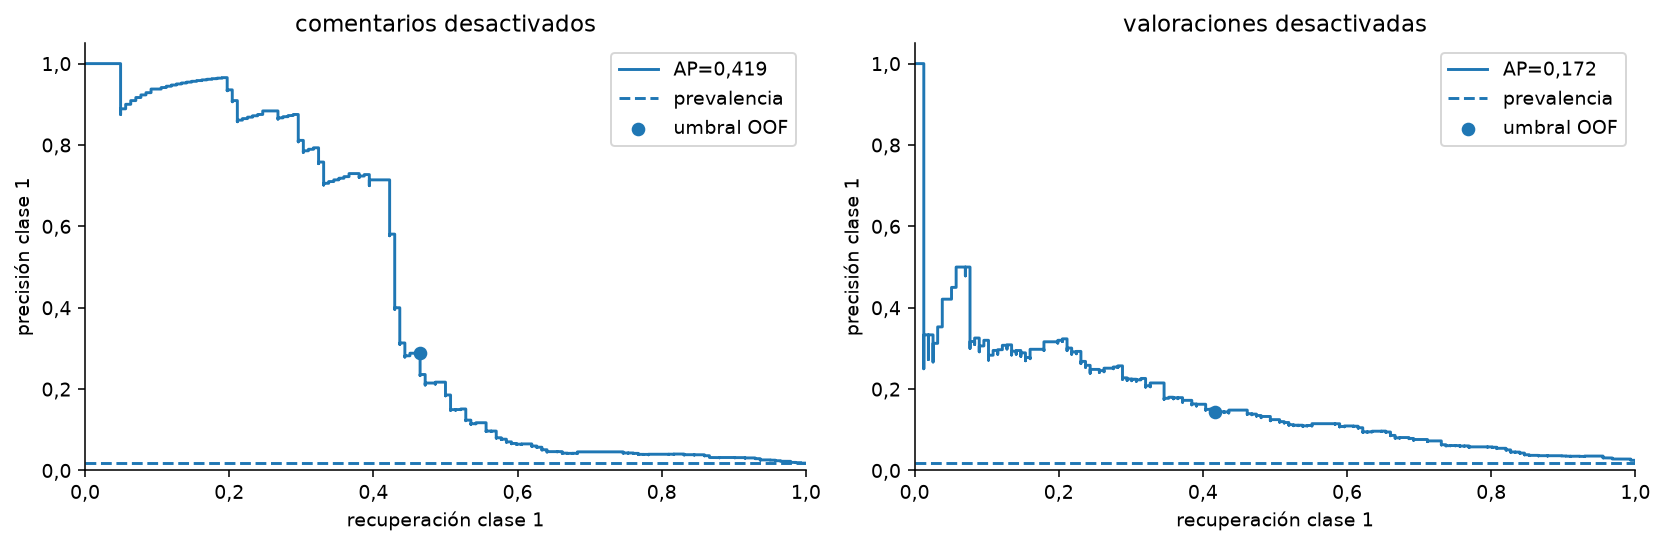

**Ablación en la proporción «me gusta/no me gusta».** Se retiran conjuntamente views y comment_count, manteniendo la familia, la receta seleccionada y las mismas particiones por vídeo. No se retiran likes y dislikes: ya están excluidos como predictores para evitar revelar directamente el cociente.
MAE medio con contadores 26,4568; sin ellos 26,7153. Con contadores el MAE es menor. Diferencia sin − con: 0,2585 unidades de ratio; positivo favorece incluirlos.
Reducción relativa sobre la variante sin contadores: 0,97 %. Es una diferencia de error, no porcentaje de aciertos ni prueba de significación.
Comparación emparejada: menor MAE con contadores en 2 de 3 particiones; mayor en 1; empate en 0. No se supone un beneficio uniforme.

| Partición | MAE con contadores | MAE sin contadores | Sin − con |
|---|---:|---:|---:|
| 1 | 25,9776 | 26,7623 | 0,7847 |
| 2 | 30,0357 | 29,7172 | -0,3185 |
| 3 | 23,3570 | 23,6664 | 0,3093 |

Los hiperparámetros se seleccionaron con contadores; la variante sin ellos no recibió otra búsqueda. La ablación es condicional a esa receta y no demuestra que todo modelo sin contadores sea peor. Las dos variables se retiran juntas: no se identifica su aportación individual.
Las particiones comparten parte del entrenamiento y su número es reducido; una diferencia media pequeña no acredita significación ni causalidad. Ambos ajustes reaprenden sus transformadores dentro de la partición; no se supone que todos los pesos o escalas permanezcan idénticos al quitar variables.
views y comment_count son señales contemporáneas. Esta comparación no convierte el ejercicio en predicción antes de publicar, no garantiza disponibilidad futura y no autoriza cambiar atributos tras observar la reserva de prueba. Se conserva el resultado del estudio de desarrollo.

,without_views_comment_count_mae,without_fold_mae,with_counters_mae,limitation
0,"26,715274","[26,762295; 29,717176; 23,666352]","26,45679","Hiperparámetros seleccionados con contadores; ablación condicional, no búsqueda anidada"


In [14]:
# fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos y
# unidades explícitos.
# drop_repeated: omite en la segunda curva las cautelas idénticas ya explicadas en la primera.
from notebook_helpers import drop_repeated
fig,ax=plt.subplots(1,2,figsize=(12,4))
for axis,task in zip(ax,['comments_disabled','ratings_disabled']):
    # r: resultados de la tarea binaria cuya curva precisión–recuperación se dibuja.
    # pr: curva precisión–recuperación de prueba, usada para describir y no elegir umbral.
    r=report['tasks'][task]
    pr=pd.read_csv(ROOT/f'reports/{task}_precision_recall.csv')
    display(Markdown(drop_repeated(precision_recall_summary(task, r, pr), shown_notes)))
    axis.step(pr.recall,pr.precision,where='post',label=f'AP={format_number(r["average_precision"], 3)}')
    axis.axhline(r['positive_prevalence'],linestyle='--',label='prevalencia')
    # Sólo se marca precisión operativa si el modelo ha seleccionado positivos.
    if sum(row[1] for row in r['holdout']['confusion_matrix']) > 0:
        axis.scatter([r['positive_recall']],[r['positive_precision']],label='umbral OOF')
    axis.set(title=task_description(task),xlabel='recuperación clase 1',ylabel='precisión clase 1',xlim=(0,1),ylim=(0,1.05))
    axis.legend()
show('precision_recall')
display(Markdown(ratio_ablation_summary(report['tasks']['ratio'])))
show_details('Detalle de la ablación en la proporción «me gusta/no me gusta»', pd.DataFrame([report['tasks']['ratio']['ratio_ablation']]))


## 8. Segmentación, estabilidad y reducción dimensional

**Tipo de comparación.** Un modelo inductivo puede asignar un grupo a un vídeo nuevo mediante su operación de predicción. Una exploración transductiva describe la muestra agrupada y no ofrece necesariamente esa misma operación para vídeos nuevos. MiniBatch KMeans actualiza los centros usando pequeños lotes. En GMM, diagonal (`diag`) y compartida (`tied`) son dos formas de representar cómo varían conjuntamente las entradas.

**Familias de agrupación.** KMeans asigna vídeos a centros y MiniBatch los estima con lotes. Mean Shift busca máximos de densidad y GMM (modelo de mezcla gaussiana) representa los datos como una combinación de distribuciones con forma de campana. DBSCAN agrupa zonas densas y puede marcar ruido. El aglomerativo fusiona grupos sucesivamente.

**Lectura de grupos.** Silueta mide cohesión y separación. ARI (índice de Rand ajustado) mide acuerdo entre dos agrupaciones descontando el esperable por azar. NMI (información mutua normalizada) mide la información que comparten. Aquí comparan grupos con categorías y el ARI también mide estabilidad entre réplicas. PCA (análisis de componentes principales) resume direcciones de mayor variación. t-SNE (incrustación estocástica de vecinos) representa cercanías locales en dos dimensiones; sus ejes no son unidades de los atributos originales.

Este bloque aborda la segmentación pedida en el enunciado. Se comparan familias inductivas en representaciones SVD y sobre los mismos índices de evaluación; aglomerativo y DBSCAN se conservan como exploraciones separadas. El resumen siguiente calcula tamaños, dimensiones y familias a partir de los resultados y de la cadena de procesamiento guardada.

`category` no es predictor ni objetivo de la segmentación y no decide la selección, aunque intervino en el muestreo previo por estratos. Su relación con los grupos sólo se describe después. Silueta y estabilidad no equivalen a utilidad editorial o comercial. Las proyecciones numéricas PCA/t-SNE corresponden a otro espacio y se interpretarán aparte.


**Entrada a la segmentación.** 6.000 vídeos distintos, una fila por vídeo del conjunto de desarrollo ampliado. Se conserva la primera aparición disponible al deduplicar; no se promedian todas sus apariciones ni se obtiene una muestra temporal prospectiva.

El conjunto anterior se muestreó por estratos de categoría; después se deduplicaron vídeos y se tomó una muestra aleatoria con semilla. category no es atributo de entrada, objetivo de ajuste ni criterio para elegir la segmentación, pero sí influyó en la composición por ese muestreo previo.

La cadena de procesamiento guardada combina TF-IDF de título, tags y descripción, indicadores de región y atributos numéricos transformados. Columnas numéricas: views, dislikes, comment_count, title_length, publish_hour, publish_weekday. likes puede aparecer en perfiles descriptivos, pero no es entrada numérica de la segmentación actual.

Representación aprendida: 8.016 atributos transformados → SVD de 15 componentes en el modelo guardado; fracción de varianza explicada 88,24 % en esa representación de ajuste. No equivale a porcentaje de calidad, categorías acertadas o utilidad comercial.

Comparación registrada: 78 ensayos inductivos; dimensiones SVD [15, 30, 60]; familias y cantidades: gmm=24, kmeans=24, meanshift=6, minibatch=24.

Cada ajuste inductivo usa 6.000 vídeos; la silueta se calcula sobre los mismos 1.000 índices de evaluación. Son observaciones del corpus ajustado, no una reserva de prueba externa de segmentación. La igualdad de tamaños se valida aquí; la identidad de los índices proviene del código y la semilla compartidos.

Exploraciones separadas: 11 ensayos (agglomerative=5, dbscan=6). Aglomerativo y DBSCAN se ajustan sobre los índices comunes; no aportan predict nativo para nuevas filas en esta interfaz y no compiten como ganadores inductivos.

Resultado guardado: kmeans, 2 grupos, SVD 15. Los números de grupo son identificadores arbitrarios, no etiquetas editoriales ni niveles de calidad. La regla de elección y las métricas se estudiarán después.

SVD permite una representación densa de menor dimensión a partir de muchos atributos dispersos, sin centrar la matriz como PCA. Cambia la geometría: sus componentes mezclan señales y no son géneros predefinidos. Las proyecciones PCA/t-SNE de cuatro contadores del cuaderno son otro espacio y no validan por sí solas estos grupos.

,input_columns,transformed_features,svd_dimensions,svd_input_features,explained_variance_fraction,fit_rows,numeric_columns
0,[title; publish_time; tags; views; dislikes; comment_count; description; region],8.016,15,8.016,"0,882418",6.000,[views; dislikes; comment_count; title_length; publish_hour; publish_weekday]


Validaciones adicionales reutilizadas tras verificar sus huellas.


**Selección de segmentación.** 78 ensayos inductivos técnicamente elegibles; 29 cumplen además tamaño y estabilidad. eligible exige convergencia declarada, cobertura completa y silueta calculable con más de un grupo y menos grupos que casos evaluados.

Regla adicional: cada grupo ocupa al menos 5 % del corpus y hay tres réplicas válidas con ARI medio ≥ 0,80. El límite de ARI se aplica a la media, no obliga a que cada réplica supere ese valor.

La silueta de un caso compara a, distancia media dentro de su grupo, con b, menor distancia media a otro grupo: s=(b−a)/max(a,b). El informe usa distancia euclídea en SVD e índices comunes. Cerca de 1 indica separación relativa; cerca de 0, fronteras difusas; negativo, posible mejor proximidad a otro grupo. No es exactitud ni porcentaje de categorías acertadas.

Ganador entre quienes cumplen: kmeans, k=2, SVD=15, silueta 0,2022. Tamaños de grupo: 3.086, 2.914; grupo mínimo 48,57 %.

Entre todos los técnicamente elegibles, la mayor silueta corresponde a meanshift, k=2, SVD=15: 0,3810. Grupo mínimo 0,53 %; ARI medio 0,5536. No cumple los límites adicionales.

Estabilidad del ganador con SVD fijo: réplicas [0,9960; 0,9840; 0,9960], media 0,9920. Se reajusta el algoritmo en remuestreos del 80 % y se comparan asignaciones en los mismos índices; esos índices pueden participar en los remuestreos. No es una prueba sobre vídeos disjuntos.

ARI compara dos particiones y ajusta por acuerdo esperado al azar; no cambia al permutar los números de grupo. Aquí compara referencia y réplica, no géneros editoriales. El campo ARI frente a category responde a otra pregunta y no interviene en la selección.

Diagnóstico distinto de la cadena de procesamiento completa: ARI medio 0,9841, réplicas [0,9880; 0,9880; 0,9761]. Reaprende transformadores y SVD con receta fija; 5.000 vídeos de ajuste y 1.000 de auditoría, sin IDs compartidos en esos ajustes. Es otra muestra interna de la fuente histórica; no mide una nueva selección de receta ni es validación externa. Este ARI no se usa en el filtro anterior.

Regla añadida después de observar una segmentación previa del 99,5 %: cada grupo debe contener al menos el 5 % de los vídeos y tres réplicas válidas de estabilidad con ARI medio >= 0,80; se maximiza silueta entre quienes cumplen. No se usan categorías editoriales ni etiquetas de prueba. Son límites metodológicos de esta revisión, no requisitos del profesor ni criterios fijados antes del primer estudio.

Estabilidad alta no garantiza separación fuerte, géneros útiles ni segmentos comerciales. Los límites se añadieron después de observar la solución anterior: no se presentan como criterios a priori ni como requisitos del profesor. No se cambia la política al mirar ahora estas tablas.

,name,k,dimensions,params,silhouette,coverage,n,evaluation_n,observed_evaluation_clusters,eligible,converged,warnings,stability_ARI,stability_warnings,stability_ARI_mean,ARI,NMI,cluster_sizes,min_cluster_fraction,selectable,AIC,BIC,scope,noise_fraction,eps,min_samples
,name,k,dimensions,parámetros utilizados,silueta,coverage,n,evaluation_n,observed_evaluation_clusters,eligible,converged,avisos registrados,stability_ARI,stability_warnings,stability_ARI_mean,ARI,NMI,cluster_sizes,min_cluster_fraction,selectable,AIC,BIC,scope,noise_fraction,eps,min_samples
0,kmeans,2,15,,"0,202204",1,6.000,1.000,2,True,True,[],"[0,996; 0,984048; 0,996]",[],"0,992016","0,005969","0,010911",0: 3.086; 1: 2.914,"0,485667",True,—,—,—,—,—,—
1,minibatch,2,15,,"0,20158",1,6.000,1.000,2,True,True,[],"[0,933089; 0,917681; 0,944729]",[],"0,931833","0,005935","0,010681",0: 2.946; 1: 3.054,"0,491",True,—,—,—,—,—,—
2,kmeans,3,15,,"0,19696",1,6.000,1.000,3,True,True,[],"[0,985518; 0,972; 0,985518]",[],"0,981012","0,003558","0,01085",0: 782; 1: 2.416; 2: 2.802,"0,130333",True,—,—,—,—,—,—
3,minibatch,3,15,,"0,192128",1,6.000,1.000,3,True,True,[],"[0,849517; 0,441606; 0,65779]",[],"0,649638","0,003645","0,012377",0: 772; 1: 2.680; 2: 2.548,"0,128667",False,—,—,—,—,—,—
4,kmeans,4,15,,"0,170951",1,6.000,1.000,4,True,True,[],"[0,949616; 0,979131; 0,985149]",[],"0,971299","0,00268","0,010926",0: 1.988; 1: 1.138; 2: 2.162; 3: 712,"0,118667",True,—,—,—,—,—,—
5,minibatch,4,15,,"0,161055",1,6.000,1.000,4,True,True,[],"[0,450364; 0,361993; 0,451719]",[],"0,421359","0,007576","0,015171",0: 1.115; 1: 2.133; 2: 2.033; 3: 719,"0,119833",False,—,—,—,—,—,—
6,kmeans,5,15,,"0,137575",1,6.000,1.000,5,True,True,[],"[0,936041; 0,7816; 0,939074]",[],"0,885572","0,006821","0,015786",0: 1.017; 1: 1.599; 2: 1.418; 3: 625; 4: 1.341,"0,104167",True,—,—,—,—,—,—
7,minibatch,5,15,,"0,136507",1,6.000,1.000,5,True,True,[],"[0,710156; 0,852603; 0,485902]",[],"0,682887","0,006893","0,015015",0: 1.269; 1: 1.703; 2: 1.376; 3: 610; 4: 1.042,"0,101667",False,—,—,—,—,—,—
8,kmeans,6,15,,"0,140187",1,6.000,1.000,6,True,True,[],"[0,973652; 0,963119; 0,928573]",[],"0,955114","0,008995","0,018649",0: 1.071; 1: 957; 2: 591; 3: 762; 4: 1.270; 5: 1.349,"0,0985",True,—,—,—,—,—,—


### Relación de grupos con categorías editoriales

Se comparan 6.000 vídeos, 2 grupos y 16 categorías. Cada celda de la tabla de recuentos cuenta vídeos con ambas etiquetas. El CSV de proporciones contiene fracciones de 0 a 1; la tabla porcentual multiplica por 100. El denominador es el total del grupo (fila), no el total de la categoría (columna).

Grupo 0, categorías más frecuentes: Entertainment (entretenimiento): 984 (31,89 %); People & Blogs (personas y blogs): 470 (15,23 %); News & Politics (noticias y política): 348 (11,28 %). En caso de empate, el orden de presentación no significa una diferencia de frecuencia.

Grupo 1, categorías más frecuentes: Entertainment (entretenimiento): 774 (26,56 %); People & Blogs (personas y blogs): 663 (22,75 %); News & Politics (noticias y política): 392 (13,45 %). En caso de empate, el orden de presentación no significa una diferencia de frecuencia.

ARI frente a categorías: **0,0060**. Compara pares de vídeos y descuenta acuerdo esperado al azar; puede ser negativo. No es el ARI de estabilidad entre réplicas ni un porcentaje de aciertos.

NMI: **0,0109**. Mide información compartida normalizada (media aritmética de las entropías). No está ajustada por azar ni representa precisión o porcentaje de categorías recuperadas.

Las particiones no son equivalentes. Se informa la magnitud de ambas métricas sin convertir un umbral arbitrario en una prueba estadística de asociación.

Tener distinto número de grupos y categorías limita la equivalencia uno a uno, pero no invalida las métricas. Las categorías sirven como referencia imperfecta y no eligen el ganador; sí influyeron en la estratificación del conjunto anterior. La comparación es descriptiva sobre la muestra de ajuste, no validación externa ni prueba de utilidad comercial.

cluster,0,1
Autos & Vehicles (automóviles y vehículos),59,55
Comedy (comedia),234,82
Education (educación),46,73
Entertainment (entretenimiento),984,774
Film & Animation (cine y animación),129,142
Gaming (videojuegos),94,84
Howto & Style (tutoriales y estilo),119,152
Music (música),207,136
News & Politics (noticias y política),348,392
Nonprofits & Activism (organizaciones sin ánimo de lucro y activismo),20,41


row_0,0,1
Autos & Vehicles (automóviles y vehículos),"1,91 %","1,89 %"
Comedy (comedia),"7,58 %","2,81 %"
Education (educación),"1,49 %","2,51 %"
Entertainment (entretenimiento),"31,89 %","26,56 %"
Film & Animation (cine y animación),"4,18 %","4,87 %"
Gaming (videojuegos),"3,05 %","2,88 %"
Howto & Style (tutoriales y estilo),"3,86 %","5,22 %"
Music (música),"6,71 %","4,67 %"
News & Politics (noticias y política),"11,28 %","13,45 %"
Nonprofits & Activism (organizaciones sin ánimo de lucro y activismo),"0,65 %","1,41 %"


,grupo,n,views_median,likes_median,dislikes_median,comments_median,title_length_median,top_category,top_region
0,0,3.086,"161.045,5","4.061,5",196,"607,5",52,Entertainment (entretenimiento),CA
1,1,2.914,"18.095,5","273,5",16,40,53,Entertainment (entretenimiento),MX


### Qué caracteriza a los grupos (6.000 vídeos únicos)

Los identificadores son arbitrarios. n cuenta vídeos, no apariciones regionales. Las medianas resumen el valor central: no son medias, sumas ni tasas.

**Grupo 0:** 3.086 vídeos (51,43 %). Medianas: 161.045,5 visualizaciones; 4.061,5 likes; 196,0 dislikes; 607,5 comentarios; 52,0 caracteres en el título. Categoría modal publicada: Entertainment (entretenimiento), con 984 vídeos (31,89 % del grupo); es la categoría más frecuente. Región modal publicada: CA. Una moda no implica mayoría ni exclusividad.

**Grupo 1:** 2.914 vídeos (48,57 %). Medianas: 18.095,5 visualizaciones; 273,5 likes; 16,0 dislikes; 40,0 comentarios; 53,0 caracteres en el título. Categoría modal publicada: Entertainment (entretenimiento), con 774 vídeos (26,56 % del grupo); es la categoría más frecuente. Región modal publicada: MX. Una moda no implica mayoría ni exclusividad.

La mayor mediana de visualizaciones es 8,90 veces la menor. Es una razón de medianas, no el cociente para cada vídeo ni una tasa de interacción.

Los perfiles describen esta muestra y la aparición retenida de cada vídeo; no representan su evolución temporal. likes se describe, pero no es entrada numérica de la segmentación. Título y región no se conservan en cluster_sample.csv: sus resúmenes publicados no se pueden reproducir sólo desde ese CSV. Una diferencia descriptiva de audiencia no demuestra causalidad, una separación puramente temática ni utilidad comercial.

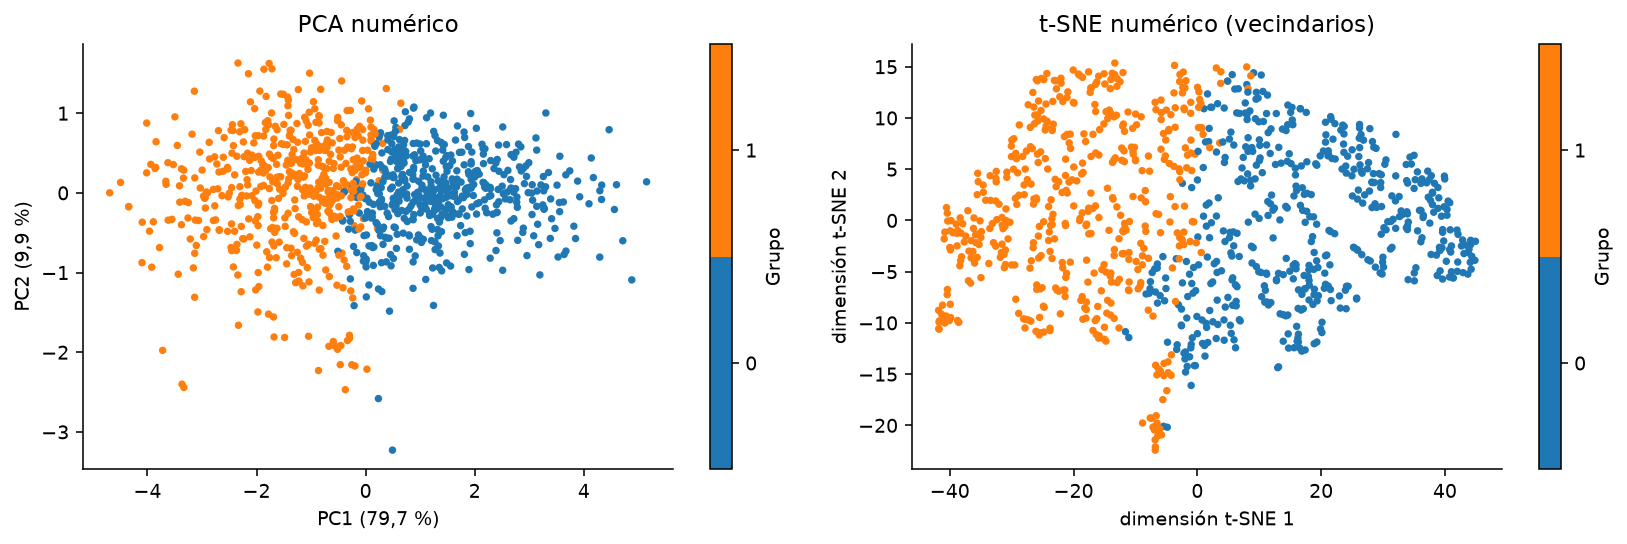

,PC1,PC2
views,"0,493493","-0,589134"
likes,"0,508836","0,266883"
dislikes,"0,513708","-0,340547"
comment_count,"0,483378","0,682438"


### Cómo leer PCA y t-SNE numéricos

Se representan 1.000 vídeos y cuatro contadores: views, likes, dislikes, comment_count. Se rellenaron 0 valores ausentes con cero para esta visualización; no es la imputación aprendida del modelo. Se aplica log1p y después estandarización en esta muestra.

PCA conserva 79,68 % en PC1 y 9,88 % en PC2; en conjunto, 89,56 % de la varianza de estos cuatro contadores transformados. No es porcentaje de aciertos ni varianza del texto o del espacio TF-IDF + SVD.

Mayor carga absoluta de PC1: dislikes. Las cargas orientan el eje, sin demostrar causalidad. Su signo puede invertirse sin cambiar la proyección geométrica.

t-SNE usa perplexity 30, semilla 42 y un máximo de 500 iteraciones. La perplexity regula la escala de vecindad, no el número de grupos. Los ejes no son variables ni porcentajes de varianza; las distancias entre islas, sus tamaños y sus huecos no validan separación global. Una semilla fija facilita repetir este cálculo, no garantiza robustez frente a otras elecciones.

Los colores son las etiquetas de la segmentación ya calculada: PCA y t-SNE no crean esos grupos aquí. Ambos gráficos usan sólo los cuatro contadores; likes figura en ellos aunque no sea entrada numérica de la segmentación. No muestran las distancias del modelo TF-IDF + metadatos + SVD ni sustituyen su silueta o estabilidad.

region,CA,DE,FR,GB,IN,JP,KR,MX,RU,US
cluster,,,,,,,,,,
0,"84,73 %","44,22 %","39,78 %","73,91 %","64,38 %","31,49 %","50,10 %","40,55 %","50,87 %","70,59 %"
1,"15,27 %","55,78 %","60,22 %","26,09 %","35,62 %","68,51 %","49,90 %","59,45 %","49,13 %","29,41 %"


**Distribución regional de los grupos.** Porcentajes dentro de cada grupo:

Grupo 0: CA, 666 vídeos (21,58 %); RU, 499 vídeos (16,17 %).

Grupo 1: MX, 610 vídeos (20,93 %); FR, 498 vídeos (17,09 %).

Dentro de cada región, el grupo 0 reúne 84,73 % de CA; 73,91 % de GB; 31,49 % de JP. El denominador ahora es el total de vídeos de esa región, no el tamaño del grupo.

Audiencia mediana por grupo: 0: 161.045,5 visualizaciones; 1: 18.095,5 visualizaciones.

Las medianas de audiencia difieren entre grupos. La distribución de grupos varía entre regiones. **Conclusión:** los grupos ofrecen perfiles distintos de audiencia y composición regional; no se interpretan como categorías temáticas. Los términos reconstruidos permiten contrastar también plantillas e indicios lingüísticos. Estos cruces describen asociación y no miden qué atributo causa o domina la separación; para eso haría falta una ablación específica.

Región es un atributo del modelo y las apariciones retenidas dependen del muestreo. Este cruce describe asociación en la muestra, no causa de la agrupación ni segmentos comerciales validados.

region,CA,DE,FR,GB,IN,JP,KR,MX,RU,US
cluster,,,,,,,,,,
0,666,348,329,51,300,137,244,416,499,96
1,120,439,498,18,166,298,243,610,482,40


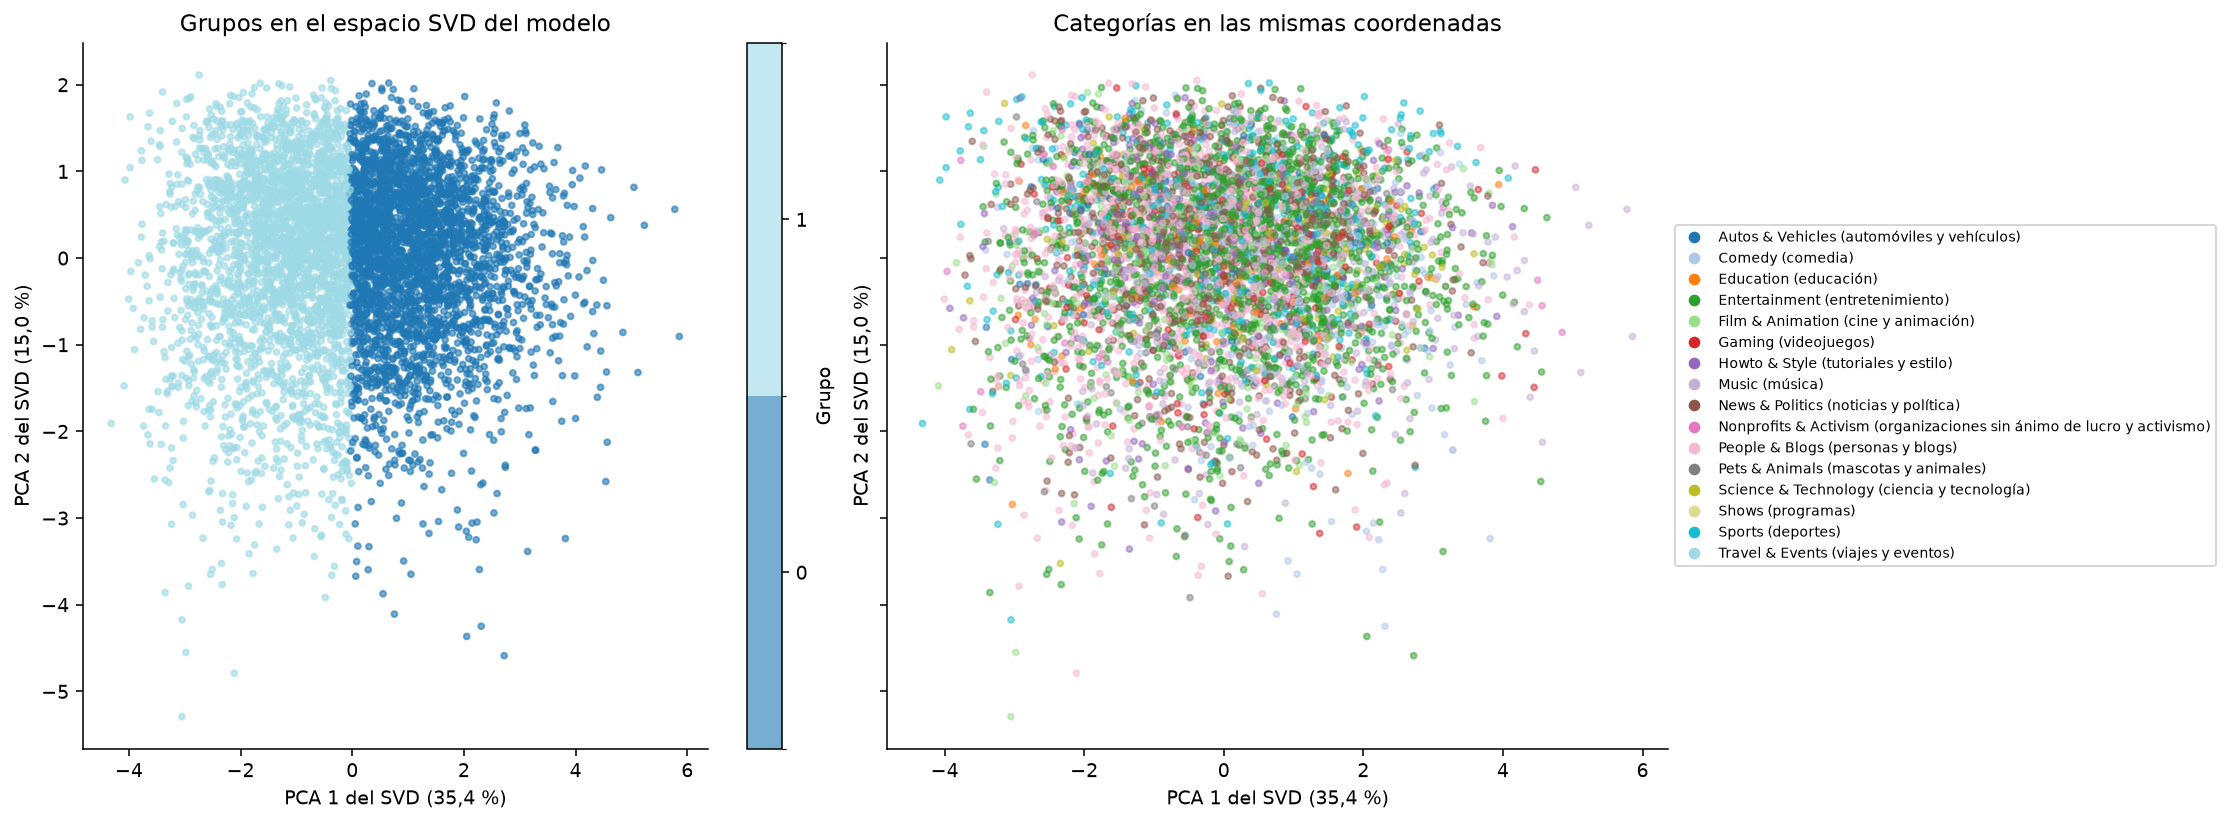

### Proyección del espacio real del modelo

Se representan 6.000 vídeos, 2 grupos y 16 categorías. El preprocesador guardado produce 8.016 atributos de TF-IDF, numéricos y región; el SVD aprendido los transforma en 15 coordenadas. Se han contrastado muestra, orden y grupos con el informe, sin reajustar esa cadena de procesamiento.

Un PCA descriptivo posterior reduce esas coordenadas a dos ejes: PC1 conserva 35,39 % y PC2 14,99 %; suman 50,38 % de la varianza del espacio SVD en esta muestra. No es el porcentaje de varianza de los cuatro contadores del gráfico anterior ni de aciertos de categorías.

El SVD guardado registra 88,24 % de varianza explicada en su representación de ajuste. Es otra cantidad: no se multiplican ambos porcentajes para presentar una conservación exacta de información original.

Cada vídeo ocupa exactamente las mismas coordenadas en ambos paneles, con ejes compartidos. Sólo cambia el color: a la izquierda, grupo predicho; a la derecha, categoría editorial. Los colores de ambos paneles no establecen correspondencias entre sus etiquetas. Las categorías no intervienen en el PCA de esta figura.

La proyección 2D descarta variación: solapamiento no demuestra ausencia de separación en todas las dimensiones, y separación visual no acredita estabilidad, utilidad ni recuperación de géneros. La silueta se calculó en el SVD completo, no en este dibujo. La comparación editorial debe leerse con contingencia, ARI y NMI; esta figura describe datos de ajuste y no constituye validación externa.

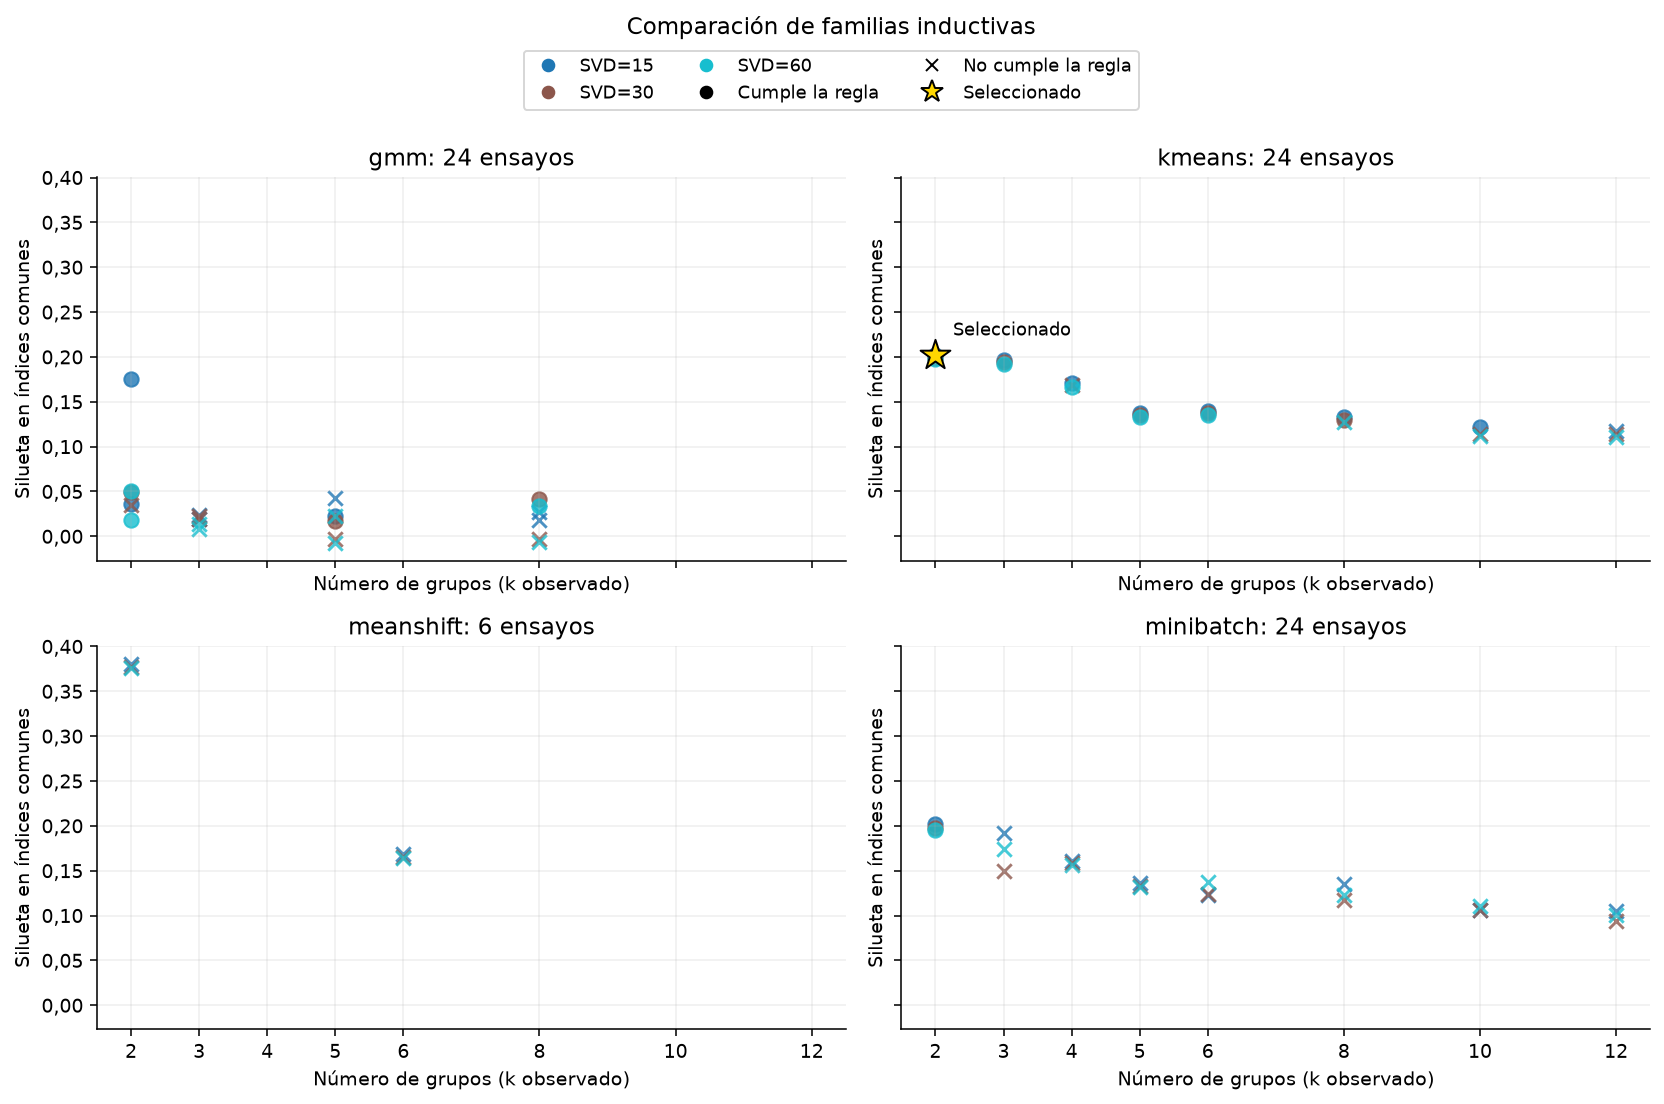

### Comparar ensayos sin confundir silueta con admisibilidad

El gráfico contiene 78 ensayos inductivos con silueta disponible, de 78 registrados; 29 cumplen los límites de selección. Quedan fuera 11 exploraciones transductivas. Cada punto es un ensayo. Eje horizontal: número de grupos; vertical: silueta. El color identifica dimensiones SVD. Círculo: cumple la regla; cruz: no cumple; estrella: solución seleccionada. No se conectan puntos con líneas.

Varios puntos pueden compartir k y dimensión: representan configuraciones distintas, por ejemplo covarianzas GMM. En Mean Shift el número de grupos se obtiene con ancho de banda; no se fijó k como en KMeans. Los puntos superpuestos pueden ocultarse entre sí: la tabla completa conserva todos los ensayos.

gmm: 24 ensayos, 24 dibujados, 9 admisibles; SVD ensayados 15, 30, 60.

kmeans: 24 ensayos, 24 dibujados, 17 admisibles; SVD ensayados 15, 30, 60.

meanshift: 6 ensayos, 6 dibujados, 0 admisibles; SVD ensayados 15, 30, 60.

minibatch: 24 ensayos, 24 dibujados, 3 admisibles; SVD ensayados 15, 30, 60.

La estrella corresponde a kmeans, k=2, SVD=15, silueta 0,2022. Estar más arriba no basta: la selección también exige tamaño y estabilidad. La regla posterior al primer estudio se declara como tal; no es un requisito atribuido al profesor.

La figura resume búsquedas ya realizadas. No es una curva de aprendizaje, una interpolación entre configuraciones ni una demostración de que aumentar k o dimensiones mejore el resultado. La silueta usa índices comunes, pero cambiar SVD cambia la geometría. No se reajustan modelos ni límites mirando la figura.

### Palabras y expresiones de los centros reconstruidos

Se contrastan 2 grupos y 8000 atributos textuales. Los términos proceden del vocabulario TF-IDF de título, tags y descripción combinados: también pueden ser expresiones de varias palabras. No identifican por sí solos el campo de origen.

**Grupo 0, 12 términos en orden descendente:** com (0,04733); https (0,04319); www (0,03715); http (0,03268); https www (0,02832); youtube (0,02514); the (0,02422); instagram (0,02270); twitter (0,02260); youtube com (0,02220); facebook (0,02188); to (0,02150).

**Grupo 1, 12 términos en orden descendente:** none (0,05212); de (0,03454); com (0,03058); https (0,02736); www (0,02662); 2018 (0,02260); la (0,02148); http (0,01896); en (0,01859); https www (0,01823); youtube (0,01771); youtube com (0,01534).

Términos presentes entre los destacados de todos los grupos: 7: com, http, https, https www, www, youtube, youtube com.

Aparece el término literal none: no es el objeto None de Python ni demuestra por sí solo que haya datos ausentes; puede ser un marcador del contenido original. No se le asigna significado temático sin revisar sus apariciones.

Se observan tokens compatibles con enlaces o plantillas: com, http, https, https www, www, youtube com. Es un indicio descriptivo, no un recuento de documentos con enlaces ni una demostración de su causa.

**Lectura del grupo 0:** términos destacados que no aparecen en las listas truncadas de los demás grupos: facebook, instagram, the, to, twitter. Son pistas del vocabulario y de plantillas del perfil, no palabras exclusivas de todos sus documentos ni etiquetas temáticas verificadas.

**Lectura del grupo 1:** términos destacados que no aparecen en las listas truncadas de los demás grupos: 2018, de, en, la, none. Son pistas del vocabulario y de plantillas del perfil, no palabras exclusivas de todos sus documentos ni etiquetas temáticas verificadas.

**Conclusión.** Los términos reconstruidos y sus diferencias de vocabulario aconsejan describir perfiles de contenido y formato, junto con audiencia y región. Las listas de términos no bastan para nombrar géneros: la correspondencia con las categorías editoriales se cuantifica por separado con ARI y NMI.

El cálculo multiplica centros en SVD por sus componentes para volver aproximadamente al espacio de atributos. No reconstruye documentos originales ni recupera información descartada. Los pesos son coordenadas aproximadas: no son frecuencias, probabilidades, porcentajes ni coeficientes causales; no tienen que sumar uno y pueden ser negativos.

Se muestran los mayores pesos dentro de cada grupo, no las palabras más exclusivas ni las diferencias respecto a otros centros. Las palabras compartidas y las plantillas limitan las etiquetas temáticas. No se afirma que sean categorías aprendidas. Eliminar enlaces, marcadores o palabras frecuentes sería otro preprocesamiento que habría que comparar con un protocolo declarado; no se cambia ahora mirando el resultado.

,grupo,term,reconstructed_weight
0,0,com,"0,047329"
1,0,https,"0,043187"
2,0,www,"0,037146"
3,0,http,"0,032679"
4,0,https www,"0,028317"
5,0,youtube,"0,025144"
6,0,the,"0,024221"
7,0,instagram,"0,0227"
8,0,twitter,"0,022599"
9,0,youtube com,"0,022196"


# Interpretación de la segmentación

ARI frente a categoría: **0,0060**; NMI: **0,0109**. La coincidencia con categorías editoriales es débil: los grupos no recuperan géneros de forma fiable.

ARI=0 corresponde aproximadamente al acuerdo esperado al azar; NMI mide información compartida. Las categorías no eligen el modelo ni el número de grupos.

Las proyecciones comparten coordenadas del espacio TF-IDF + metadatos + SVD del modelo. La proyección 2D pierde información y no sustituye silueta.

cluster_category_proportions.csv guarda fracciones entre 0 y 1 por grupo; el cuaderno las muestra también como porcentajes. cluster_terms.csv contiene términos reconstruidos desde centros o medias de la familia; son aproximaciones descriptivas y pueden reflejar plantillas o sistemas de escritura.

## Criterio de selección

## Estabilidad medida

Silueta de la solución seleccionada: **0,202**. Estabilidad con SVD fijo: ARI medio **0,992**; 3 réplicas [0,996; 0,984; 0,996], rango 0,984–0,996. La media debe leerse junto con las réplicas: no acredita reproducción uniforme ni utilidad de los grupos. Pocas réplicas limitan la interpretación; el balance se describe con los tamaños reales de los perfiles. Estabilidad, silueta y utilidad son conceptos distintos.

## Tamaños y utilidad

Distribución de tamaños: el grupo mayor reúne 51,4 % de los 6000 vídeos; el menor contiene 2914. Los tamaños deben valorarse junto con perfiles, estabilidad y el objetivo de negocio; silueta no valida utilidad por sí solo.


In [15]:
# cluster_sample: una fila por vídeo usada por el modelo, distinta de las apariciones supervisadas.
cluster_sample = pd.read_csv(ROOT/'reports/cluster_sample.csv')
# cluster_representation: dimensiones y atributos leídos del pipeline ya guardado, sin fit.
cluster_representation = clustering_representation(ROOT)
display(Markdown(clustering_overview(report, cluster_sample, cluster_representation)))
show_details('Representación del clustering guardado', pd.DataFrame([cluster_representation]))

# quality_checks: comprueba límites por canal, costes y estabilidad del pipeline completo.
# Se importa: run como run_quality.
from quality_checks import run as run_quality
# quality: diagnóstico adicional generado o verificado antes de interpretar la estabilidad.
quality = run_quality(ROOT/'train.conf', resume=reuse)
# selection_text: lectura de la regla de selección; se reutiliza para no repetirla al final.
selection_text = cluster_selection_summary(report, quality)
display(Markdown(selection_text))
show_details('Ensayos completos de clustering: selección y exploraciones', pd.DataFrame(report['clustering']))
# results_report: contrasta recuentos, fracciones y métricas con los vídeos actuales.
from results_report import cluster_category_summary
# category_counts y category_fractions: evidencias con grupos en filas y categorías en columnas.
category_counts = pd.read_csv(ROOT/'reports/cluster_categories.csv', index_col=0)
category_fractions = pd.read_csv(ROOT/'reports/cluster_category_proportions.csv', index_col=0)
display(Markdown(category_notes(cluster_category_summary(report, cluster_sample, category_counts, category_fractions))))
show_details('Recuentos de vídeos por categoría y grupo', category_counts.T.rename(index=category_label))
# fractions_view: porcentajes de presentación con un grupo por columna.
fractions_view = (100 * category_fractions.T).rename(index=category_label)
show_details('Porcentajes dentro de cada grupo (cada columna suma aproximadamente 100 %)',
             fractions_view.map(lambda value: format_number(value, 2) + ' %'))
# profiles: resúmenes por cluster; describen actividad relativa, sin validar segmentos comerciales.
profiles=pd.read_csv(ROOT/'reports/cluster_profiles.csv')
# La interpretación se calcula debajo; se omite el texto redundante guardado en el CSV técnico.
display(category_view(profiles.drop(columns=['interpretation'], errors='ignore'), 'top_category'))
# results_report: valida y explica perfiles con las cifras actuales de la muestra.
from results_report import cluster_profiles_summary
display(Markdown(category_notes(cluster_profiles_summary(profiles, cluster_sample))))
# notebook_helpers: valida y prepara las dos proyecciones descriptivas, sin fit de modelos finales.
from notebook_helpers import prepare_numeric_projections
# results_report: interpreta varianza, cargas y vecindarios con resultados actuales.
from results_report import numeric_projection_summary
# ListedColormap: mantiene los colores de las etiquetas de grupos ya calculadas.
from matplotlib.colors import ListedColormap
# sample: mismos índices y semilla del gráfico anterior; una fila por vídeo.
sample = cluster_sample.sample(n=min(1000,len(cluster_sample)),random_state=42)
# numeric_views: coordenadas, PCA ajustado y diagnóstico de esta visualización.
numeric_views = prepare_numeric_projections(sample,seed=42)
numeric = numeric_views['numeric']
pca = numeric_views['pca']
projection = numeric_views['projection']
embedding = numeric_views['embedding']
# Se guarda el diagnóstico descriptivo para que el repaso use estas mismas cifras.
(ROOT/'reports/numeric_projection_diagnostic.json').write_text(json.dumps(numeric_views['stats'],ensure_ascii=False,indent=2),encoding='utf-8')
# fig: figura que se guarda y se cierra después de visualizar; ax: ejes de la figura, manteniendo títulos y
# unidades explícitos.
fig,ax=plt.subplots(1,2,figsize=(12,4))
# palette: colores discretos consistentes con las etiquetas de cluster.
palette=plt.get_cmap('tab10' if len(profiles)<=10 else 'tab20').colors[:len(profiles)]
# options: opciones de color y tamaño compartidas por ambas proyecciones.
options=dict(c=sample.cluster,cmap=ListedColormap(palette),vmin=-.5,vmax=len(profiles)-.5,s=8)
# first: dispersión PCA asociada a la barra de colores.
first=ax[0].scatter(projection[:,0],projection[:,1],**options)
ax[0].set(title='PCA numérico',xlabel=f'PC1 ({format_number((pca.explained_variance_ratio_[0]) * 100, 1)} %)',ylabel=f'PC2 ({format_number((pca.explained_variance_ratio_[1]) * 100, 1)} %)')
# second: dispersión t-SNE asociada a la barra de colores.
second=ax[1].scatter(embedding[:,0],embedding[:,1],**options)
ax[1].set(title='t-SNE numérico (vecindarios)',xlabel='dimensión t-SNE 1',ylabel='dimensión t-SNE 2')
for axis,points in zip(ax,[first,second]):
    fig.colorbar(points,ax=axis,ticks=profiles.cluster.tolist(),label='Cluster')
show('reduction_pca_tsne')
# loadings: cargas PCA por contador para interpretar la dirección de los ejes.
loadings=pd.DataFrame(pca.components_.T,index=numeric.columns,columns=['PC1','PC2'])
display(loadings)
display(Markdown(numeric_projection_summary(numeric_views['stats'])))

# Proyecciones del espacio real del modelo, relación editorial y términos.
# notebook_helpers: reproduce el espacio del modelo y dibuja coordenadas compartidas.
from notebook_helpers import prepare_model_space_view, draw_model_space_view
# results_report: explica las dos reducciones y el significado del color.
from results_report import model_space_summary
# model_view: coordenadas, etiquetas contrastadas y estadísticas sin refit del pipeline.
model_view = prepare_model_space_view(ROOT)
# results_report: describe la distribución regional del corpus ya contrastado.
from results_report import cluster_region_summary
model_view['region_counts'].to_csv(ROOT/'reports/cluster_by_region.csv')
# Fracciones de grupos dentro de cada región: cada columna suma uno.
within_region = model_view['region_counts'].div(model_view['region_counts'].sum(axis=0),axis=1)
within_region.to_csv(ROOT/'reports/cluster_within_region.csv')
show_details('Porcentaje de cada región asignado a cada grupo (columnas suman 100 %)',(100*within_region).map(lambda value:format_number(value,2)+' %'))
display(Markdown(cluster_region_summary(model_view['region_counts'],profiles)))
show_details('Recuentos de grupo por región',model_view['region_counts'])
draw_model_space_view(model_view, category_label=category_label)
show('cluster_model_space')
(ROOT/'reports/model_space_projection_diagnostic.json').write_text(json.dumps(model_view['stats'],ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown(model_space_summary(model_view['stats'])))
# notebook_helpers: distingue familias, dimensiones y admisibilidad sin trazar falsas curvas.
from notebook_helpers import draw_cluster_selection
# results_report: explica el gráfico a partir de los ensayos y la regla contrastados.
from results_report import cluster_selection_plot_summary
draw_cluster_selection(report)
show('cluster_selection')
display(Markdown(cluster_selection_plot_summary(report)))
# results_report: reconstruye centros sin fit y contrasta términos y pesos publicados.
from results_report import cluster_term_representation, cluster_terms_summary
# cluster_terms: términos y coordenadas aproximadas, no probabilidades.
cluster_terms = pd.read_csv(ROOT/'reports/cluster_terms.csv')
display(Markdown(cluster_terms_summary(cluster_terms, *cluster_term_representation(ROOT))))
show_details('Términos y pesos reconstruidos del modelo guardado', cluster_terms)
# results_report: redacta conclusiones y límites a partir de evidencias calculadas.
# Se importa: cluster_interpretation_text.
from results_report import cluster_interpretation_text
# drop_repeated: omite la regla de selección ya mostrada arriba.
from notebook_helpers import drop_repeated
display(Markdown(drop_repeated(cluster_interpretation_text(report, profiles), {paragraph.strip() for paragraph in selection_text.split(chr(10)*2)})))


## 9. Recomendación: separar selección y comprobación

**Reto pedido por el enunciado.** El enunciado incluye la recomendación entre los problemas de negocio: «Crear un recomendador que dado un vídeo te recomiende vídeos parecidos». No figura como reto opcional, por lo que forma parte de lo exigido. Se resuelve por contenido (título, etiquetas y descripción), porque el dataset no contiene historiales de usuarios para un filtrado colaborativo.

**Lectura de la recuperación.** Similitud coseno mide la semejanza entre las direcciones de dos representaciones numéricas. Los primeros k resultados (`top-k`) son los k vecinos devueltos. La coincidencia editorial es una señal indirecta (`proxy`) de semejanza, sin equivaler a una valoración de utilidad por personas. Hit@5 indica si aparece al menos un resultado de la misma categoría entre cinco; Agreement@5 indica la fracción que coincide. La cobertura mide qué parte del catálogo llega a recomendarse.

**Recuperación.** El catálogo contiene los vídeos candidatos y la consulta indica qué contenido se busca. La similitud coseno compara la dirección de las representaciones TF-IDF. Top-k limita el número de vecinos devueltos. Cobertura es la fracción del catálogo recuperada y la coincidencia editorial funciona como proxy o señal indirecta.

Este bloque desarrolla el recomendador de vídeos similares pedido en el enunciado. Se comparan seis variantes: palabras, presencia binaria, caracteres y tres representaciones que ponderan título/etiquetas y limitan o excluyen descripciones repetitivas. La selección utiliza sólo consultas de validación. Sólo la representación seleccionada se evalúa sobre consultas de prueba disjuntas. La evaluación mide coincidencia editorial, cobertura y diversidad de canales. La evaluación humana de la utilidad de las recomendaciones se propone como ampliación y queda fuera de lo solicitado en el ejercicio.


### Recomendación por contenido: elegir antes de comprobar

El objetivo es recuperar vídeos con texto similar a una consulta, no predecir una categoría ni usar valoraciones colaborativas. Se comparan representaciones de título, tags y descripción mediante vecinos de coseno. La categoría sólo sirve como proxy imperfecto de evaluación; no es entrada textual del recomendador.

Se parte de 15.009 vídeos únicos del conjunto de desarrollo y se toman 10.000. Para comparar variantes se indexan 6.000 vídeos. Los pools de validación y prueba tienen 2.000 y 2.000; se consultan 300 y 300, respectivamente. Los tres conjuntos usados para comparar/evaluar no comparten IDs. Son particiones internas por vídeo; no garantizan canales disjuntos ni validación temporal o externa.

Se comparan 6 variantes sobre las mismas consultas de validación. Se maximiza coincidencia de categoría entre hasta cinco vecinos, con denominador fijo cinco por consulta; las consultas sin resultados no desaparecen del promedio. No equivale a la Precisión@5 habitual, que mide qué proporción de las cinco primeras recomendaciones consideraría relevantes una persona: aquí el acierto es compartir categoría, una aproximación automática.

tfidf: proxy de validación 45,67 % en 300 consultas.

binary_cosine: proxy de validación 41,87 % en 300 consultas.

char_tfidf: proxy de validación 48,27 % en 300 consultas.

focused_words: proxy de validación 46,93 % en 300 consultas.

focused_chars: proxy de validación 46,93 % en 300 consultas.

focused_metadata: proxy de validación 47,13 % en 300 consultas.

Ganadora: **char_tfidf**, con 48,27 % en validación. Sólo esa representación se comprobó después en prueba; la prueba no elige la variante. Los empates conservan el primer ensayo de la lista, sin desempatar mirando prueba.

Después de evaluar, se reajustó la representación elegida sobre los 10.000 vídeos, incluidos los que antes eran consultas y 3.400 que no entraron en las consultas reducidas. El catálogo final guardado y su orden se han contrastado, sin fit en esta revisión. Las métricas publicadas corresponden al catálogo de evaluación anterior, no a una evaluación independiente del modelo ampliado. El nombre independent_proxy_test significa consultas internas disjuntas, no datos externos ni relevancia humana acreditada.

,model,category_agreement_at_5_PROXY,random_category_expectation,catalog_coverage,unique_channel_fraction_at_5,empty_query_fraction,query_videos
,modelo o referencia,category_agreement_at_5_PROXY,random_category_expectation,catalog_coverage,unique_channel_fraction_at_5,empty_query_fraction,query_videos
0,tfidf,"0,456667","0,149381","0,197667","0,836667","0,003333",300
1,binary_cosine,"0,418667","0,149381","0,188","0,832","0,006667",300
2,char_tfidf,"0,482667","0,149381","0,1935","0,820667",0,300
3,focused_words,"0,469333","0,149381","0,204333","0,804667","0,04",300
4,focused_chars,"0,469333","0,149381","0,204333","0,822","0,006667",300
5,focused_metadata,"0,471333","0,149381","0,202167","0,816","0,013333",300


### Métricas de prueba: qué cuenta cada denominador

La representación char_tfidf se evalúa con 300 consultas disjuntas del catálogo de 6.000 vídeos. Las métricas pertenecen a ese ajuste previo, no al catálogo final ampliado. Esta prueba interna no aporta juicios humanos de relevancia.

Coincidencia editorial top-5 proxy: 669 coincidencias de categoría entre 1.500 posiciones previstas: **44,60 %**. Para cada consulta se divide entre cinco incluso si devuelve menos vecinos; después se promedian las consultas. Tampoco es la Precisión@5 de relevancia juzgada por personas ni un porcentaje de usuarios satisfechos.

Se devolvieron 1.495 candidatos en total. Consultas sin resultados: 1 de 300, **0,33 %**. No se excluyen del promedio ni se inventan cinco vecinos para completarlas. empty significa lista vacía; por sí solo no identifica si faltaba vocabulario o no había similitud positiva.

Cobertura del catálogo: 1.130 vídeos distintos recuperados entre 6.000 disponibles: **18,83 %**. Un mismo candidato repetido en varias consultas cuenta una sola vez. No es porcentaje de consultas atendidas ni tasa de aciertos.

Diversidad de canales: **82,93 %**. En cada lista se divide el número de nombres de canal distintos entre los vecinos realmente devueltos; se promedian las listas y una lista vacía aporta cero. No se divide siempre entre cinco y no es la fracción global de canales únicos. Se utilizan nombres de canal, no identidades verificadas de creadores.

Las métricas responden a preguntas distintas: coincidencia editorial, alcance del catálogo, variedad de nombres de canal y falta de resultados. Ninguna demuestra por sí sola calidad, relevancia o satisfacción; una cobertura mayor tampoco es automáticamente mejor. Aquí se validan proxy, vacíos y referencia aleatoria con filas por consulta; cobertura y diversidad completas requieren listas de vecinos.

**Alcance de la cobertura.** Con 300 consultas y hasta cinco vecinos, el techo teórico es 1.500 candidatos distintos: 25,00 % del catálogo. Con las listas realmente devueltas, el techo es 1.495: 24,92 %. Se recuperaron 1.130 distintos (75,59 % de ese último techo). Son límites combinatorios; no son objetivos de calidad ni demuestran que recuperar más candidatos aporte relevancia.

,prueba proxy
category_agreement_at_5_PROXY,"0,446"
random_category_expectation,"0,143249"
catalog_coverage,"0,188333"
unique_channel_fraction_at_5,"0,829333"
empty_query_fraction,"0,003333"
query_videos,300


### Referencia aleatoria e incertidumbre: alcance de los controles

Para cada consulta se calcula la fracción del catálogo que tiene su categoría. Promediando las 300 consultas, la coincidencia esperada bajo selección uniforme de vecinos es **14,32 %**. Es una esperanza analítica con el catálogo fijo, no el resultado de ejecutar un recomendador aleatorio ni una probabilidad uniforme entre categorías. Se supone que se pueden devolver cinco candidatos incluso cuando el modelo textual no produce resultados.

El proxy observado es 44,60 %. La diferencia modelo menos referencia es **30,28 puntos porcentuales**, no ese porcentaje de mejora relativa ni de satisfacción.

Remuestreo con reemplazo: 500 réplicas, cada una con 300 consultas muestreadas con reemplazo, semilla 42. Se remuestrea el resultado completo de cada consulta, no sus cinco vecinos como si fueran independientes. Se promedia cada réplica y se toman los percentiles 2,5 y 97,5.

Intervalo percentil nominal 95 % de la media proxy: **41,40 %–48,07 %**. Describe variación entre remuestreos de estas consultas con catálogo y modelo de evaluación fijos. No representa el rango de resultados de cada consulta ni la probabilidad de relevancia de una recomendación.

Su cobertura nominal depende de supuestos: consultas representativas y dependencia suficientemente controlada. Separar IDs de vídeo no elimina la dependencia por canales o plantillas. No incorpora selección de representación, otro entrenamiento, otro catálogo, el reajuste final a 10.000 vídeos, cambios temporales ni incertidumbre de juicios humanos. No se interpreta como una probabilidad del 95 % de que un parámetro fijo esté dentro de este intervalo concreto.

La diferencia observada no lleva aquí su propio intervalo ni un contraste formal frente a la referencia. Que el valor puntual aleatorio quede por debajo del intervalo proxy no se presenta como p-valor o prueba formal de superioridad. Las 500 réplicas producen extremos aproximados con variación Monte Carlo; una semilla fija da repetibilidad, no exactitud ni validez externa.

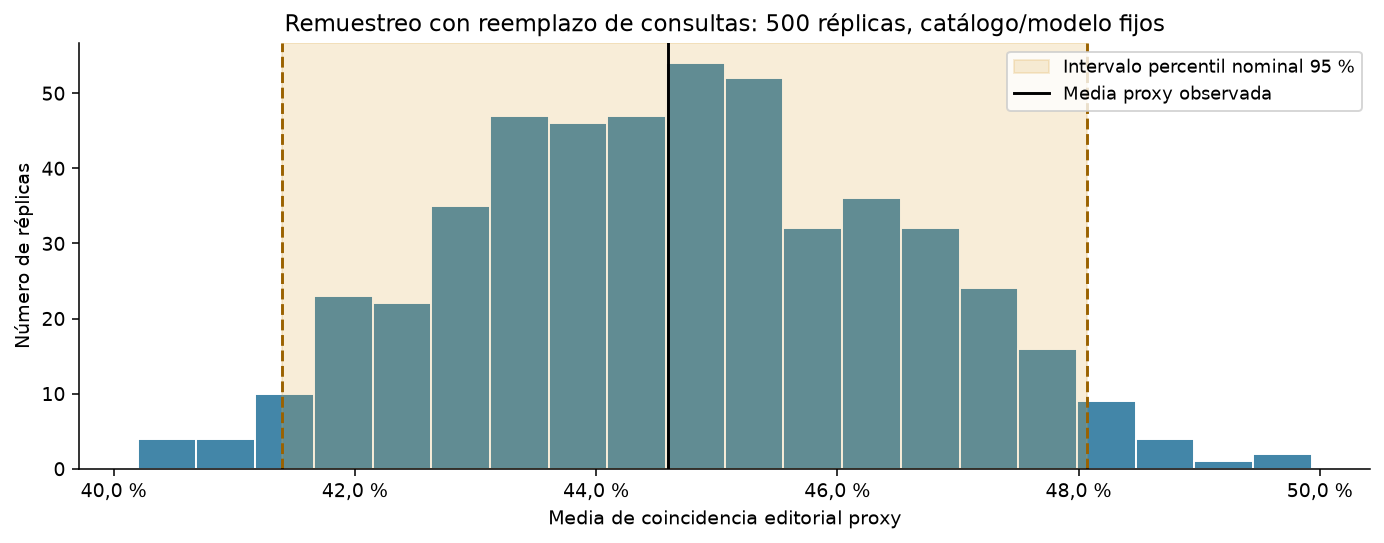

La evaluación humana se propone como ampliación fuera del alcance del ejercicio. Para realizarla habría que obtener valoraciones de personas con un protocolo independiente.

Consulta por ID conocido: `zAtP4_66bLk`

,video_id,title,similarity
0,xh3DDDP4lm0,LUCA TRIFFT AUF DOME!! Nicht LACHEN CHALLENGE!! (YouTube Kacke Edition),"0,521472"
1,_Na5hMcAvRE,Nur 2% aller Menschen schaffen diese 5 Rätsel..,"0,509152"
2,y6Wf-yh0y5Q,Nur 2% aller Menschen schaffen diese 5 Rätsel..,"0,509152"
3,RAni_8poCLQ,Unboxing Premieren-Vororder | Neuer Hauptkatalog 2018/19 | Stampin' Up!,"0,507978"
4,hXEQzrDjYZM,SASCHA FAHRNÜNFTIG GUCKT JEDES VIDEO ? SCHLEIMER !,"0,507673"


In [16]:
# notebook_helpers: reconstruye particiones y contrasta catálogo y consultas sin fit.
from notebook_helpers import recommendation_protocol
# results_report: valida y explica la elección antes de presentar las métricas de prueba.
from results_report import recommendation_selection_summary
# recommendation_split: evidencia interna de tamaños, identidades y modelo guardado.
recommendation_split, evaluation_catalog, evaluation_queries = recommendation_protocol(ROOT, report['recommendation'], return_frames=True)
(ROOT/'reports/recommendation_protocol_diagnostic.json').write_text(json.dumps(recommendation_split,ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown(recommendation_selection_summary(report['recommendation'],recommendation_split)))
show_details('Ensayos de validación del recomendador: métricas y consultas',pd.DataFrame(report['recommendation']['trials']))
# results_report: contrasta los denominadores y explica las métricas de prueba.
from results_report import recommendation_metrics_summary
# recommendation_queries: una fila por consulta, incluidas listas sin resultados.
recommendation_queries = pd.read_csv(ROOT/'reports/recommendation_query_diagnostics.csv')
display(Markdown(recommendation_metrics_summary(report['recommendation'],recommendation_queries)))
# results_report: contextualiza cobertura con los límites de consultas y candidatos.
from results_report import recommendation_coverage_summary
display(Markdown(recommendation_coverage_summary(report['recommendation'],recommendation_queries)))
show_details('Métricas proxy de prueba: valores numéricos',pd.Series(report['recommendation']['independent_proxy_test']).to_frame('prueba proxy'))
# notebook_helpers: reproduce frecuencias y bootstrap sin entrenar modelos.
from notebook_helpers import recommendation_control_audit, draw_recommendation_bootstrap
# results_report: interpreta los límites del intervalo y de la comparación aleatoria.
from results_report import recommendation_control_summary
recommendation_controls = recommendation_control_audit(report['recommendation'],recommendation_queries,evaluation_catalog,seed=recommendation_split['seed'])
(ROOT/'reports/recommendation_controls_diagnostic.json').write_text(json.dumps(recommendation_controls,ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown(recommendation_control_summary(report['recommendation'],recommendation_controls)))
draw_recommendation_bootstrap(recommendation_controls)
show('recommendation_bootstrap')

display(Markdown('La evaluación humana se propone como ampliación fuera del alcance del ejercicio. '
                 'Para realizarla habría que obtener valoraciones de personas con un protocolo independiente.'))
# models: expone las siete clases finales y el registro que relaciona tareas con clases.
# Se importa: REGISTRY.
from models import REGISTRY
# recommender: recomendador persistido utilizado para una consulta demostrativa.
recommender=REGISTRY['recommend']().load(ROOT/'artifacts/recommend.pkl')
# query_id: ID conocido que se resuelve contra el catálogo ya ajustado.
query_id=recommender.catalog_.video_id.iloc[0]
display(Markdown(f'Consulta por ID conocido: `{query_id}`'))
display(pd.DataFrame(recommender.predict(pd.DataFrame({'video_id':[query_id]}))[0]))


## 10. Comprobaciones adicionales y política de calibración

**Comprobación de incertidumbre.** El remuestreo con reemplazo remuestrea vídeos para estimar cuánto varían las métricas. La auditoría por canal separa conjuntos de vídeos de creadores distintos bajo el identificador disponible.

Se añade un diagnóstico interno por componentes de vídeo y nombre de canal, con ajuste/calibración/prueba disjuntos. Los hiperparámetros proceden del experimento base: no se presenta como validación externa ni anidada. La estabilidad siguiente vuelve a aprender toda la cadena de procesamiento sobre remuestreos y usa vídeos de auditoría fuera de los ajustes.


In [17]:
# Presentación del informe de calidad calculado en la celda de segmentación.
# quality_text: el archivo conserva identificadores; aquí los encabezados se muestran con su nombre de lectura.
import re
from results_report import task_description
quality_text = (ROOT/'reports/quality_report.md').read_text(encoding='utf-8')
quality_text = re.sub(r'^## (\w+)$', lambda match: '## ' + task_description(match[1]).capitalize(), quality_text, flags=re.M)
display(Markdown(quality_text))
display(pd.read_csv(ROOT/'reports/recommendation_by_script.csv'))
display(pd.Series(report['recommendation']['controls']).to_frame('controles del proxy'))

# results_report: relaciona coeficientes y generalización sin inferir causalidad.
from results_report import generalization_summary
display(Markdown(generalization_summary(ROOT, report, quality)))


# Validaciones adicionales de calidad

Son comprobaciones **internas** de la misma fuente histórica. Se congelan las recetas y se separan componentes vídeo–nombre de canal en ajuste, calibración y prueba. Los nombres no son identificadores canónicos de creador.

Filas de ajuste, calibración y prueba: **[11.980; 3.953; 5.981]**. Solapamientos entre particiones: channel_component: [0; 0; 0]; video_id: [0; 0; 0]; channel_title: [0; 0; 0].

| Tarea | Métrica | Prueba por canal | Referencia | Entrenamiento |
|---|---|---:|---:|---:|
| category | macro_f1 | 0,383 | 0,025 | 0,961 |
| comments_disabled | macro_f1 | 0,380 | 0,495 | 0,406 |
| ratings_disabled | macro_f1 | 0,523 | 0,495 | 0,654 |
| likes | mae | 13.025,446 | 43.201,925 | 3.791,839 |
| ratio | mae | 29,438 | 31,262 | 13,349 |

## Comentarios desactivados
F2 por canal: **0,153** con calibración separada; **0,010** con umbral predeterminado. Umbral elegido en calibración: **-1,152121**.

| Coste FN | Coste/1.000 predeterminado | Coste/1.000 calibrado |
|---:|---:|---:|
| 1 | 23,6 | 464,3 |
| 2 | 44,5 | 468,1 |
| 5 | 107,2 | 479,7 |
| 10 | 211,7 | 498,9 |
**Conclusión sobre costes.** El umbral calibrado cuesta más en **4 de 4** escenarios considerados. Optimizar F2 no equivale a minimizar el coste: aumentar la detección puede generar más falsas alarmas. No hay una política operativa avalada por estos escenarios; se conserva el umbral seleccionado en calibración y se informa el balance observado. Una política futura requeriría acordar costes y optimizarlos en desarrollo, no en esta prueba.

## Valoraciones desactivadas
F2 por canal: **0,143** con calibración separada; **0,108** con umbral predeterminado. Umbral elegido en calibración: **0,327748**.

| Coste FN | Coste/1.000 predeterminado | Coste/1.000 calibrado |
|---:|---:|---:|
| 1 | 55,3 | 90,8 |
| 2 | 73,9 | 107,3 |
| 5 | 129,6 | 157,0 |
| 10 | 222,4 | 239,8 |
**Conclusión sobre costes.** El umbral calibrado cuesta más en **4 de 4** escenarios considerados. Optimizar F2 no equivale a minimizar el coste: aumentar la detección puede generar más falsas alarmas. No hay una política operativa avalada por estos escenarios; se conserva el umbral seleccionado en calibración y se informa el balance observado. Una política futura requeriría acordar costes y optimizarlos en desarrollo, no en esta prueba.

## Estabilidad de toda la segmentación
ARI medio **0,984**; réplicas [0,988024; 0,988024; 0,97612]. En cada remuestreo se reajustan TF-IDF, imputación, escala, SVD y centroides. Los **1.000** vídeos de auditoría quedan fuera de todos esos ajustes.
La receta está fijada. La estabilidad observada indica reproducibilidad de la partición bajo estos remuestreos internos; no valida su utilidad temática ni una nueva selección de receta.

## Límites y posibles ampliaciones
Una fuente externa y los identificadores canónicos de canal permitirían comprobar la generalización. El diagnóstico Unicode describe sistemas de escritura, no identifica idiomas.

La evaluación humana de las recomendaciones queda fuera de lo solicitado en el ejercicio. Se propone como ampliación: requeriría un protocolo y valoraciones independientes de personas.


,script,query_videos,category_agreement_at_5_PROXY,random_category_expectation,empty_query_fraction
0,cjk,4,"0,2","0,150208","0,25"
1,cyrillic,43,"0,455814","0,125779",0
2,hangul,15,"0,506667","0,165833",0
3,hiragana,2,"0,2","0,173167",0
4,katakana,1,"0,4","0,188167",0
5,latin,209,"0,460287","0,144636",0
6,mixed,15,"0,2","0,130278",0
7,other,11,"0,527273","0,160015",0


,controles del proxy
proxy_ci95,"[0,414; 0,4807]"
random_category_expectation,"0,143249"
proxy_gain_over_random_expectation,"0,302751"
method,500 réplicas por consulta; catálogo y modelo fijos; categoría sigue siendo sólo un proxy
script_warning,Sistema de escritura Unicode aproximado; no detección de idioma ni nacionalidad


### Qué cambia al separar canales

**Categoría del vídeo:** macro-F1 por vídeo **0,527**; por canal **0,383**; referencia por canal **0,025**. El resultado por canal supera su referencia.

**Comentarios desactivados:** macro-F1 por vídeo **0,670**; por canal **0,380**; referencia por canal **0,495**. El resultado por canal queda por debajo de su referencia.

**Valoraciones desactivadas:** macro-F1 por vídeo **0,591**; por canal **0,523**; referencia por canal **0,495**. El resultado por canal supera su referencia.

**Conclusión.** El rendimiento de la partición por vídeo no basta para acreditar generalización a otros canales. La caída observada es compatible con que parte de las asociaciones textuales dependa de creadores, nombres propios o plantillas recurrentes. Se relaciona así con los coeficientes exportados, sin demostrar memorización ni atribuirles toda la diferencia: cambian también muestras y calibración. Para una aplicación a canales nuevos habría que usar esa separación en la validación de desarrollo y comprobarla después con una prueba independiente.

## 11. Decisiones, límites y trazabilidad

**Verificación.** La API especifica las operaciones que ofrecen las clases. La CLI permite invocarlas desde la terminal. El kernel ejecuta las celdas. La comprobación del ZIP contrasta su integridad y reproduce el flujo en otra carpeta.

La síntesis por tarea se genera de los resultados de esta ejecución y se guarda en reports para consulta; indica qué tareas corresponden a retos pedidos y cuáles a retos opcionales para subir nota. Los manifiestos y la comprobación de ejecución e inferencia se conservan en reports. La evaluación humana de la utilidad de las recomendaciones se propone como ampliación y queda fuera de lo solicitado en el ejercicio. Las conclusiones incluyen las limitaciones medidas por canal y por umbral.


In [18]:
# data_report: resume el conjunto de datos completo y sus incidencias.
# Se importa: main como describe_data.
from data_report import main as describe_data
# results_report: redacta conclusiones y límites a partir de evidencias calculadas.
# Se importa: main como summarize.
from results_report import main as summarize
# Actualizar el documento de consulta; el análisis descriptivo ya está en los bloques 1–4.
describe_data(echo=False)
display(Markdown('El [informe descriptivo del conjunto de datos](reports/data_findings.md) reúne el análisis de los bloques 1–4 para consulta independiente.'))
# summarize: actualiza la síntesis por tarea en reports/results.md. No se repite aquí: el apartado 12 la interpreta.
summarize()
display(Markdown('La [síntesis por tarea](reports/results.md) y el [informe detallado](reports/results_details.md) se actualizan para consulta independiente. '
                 'No se repiten aquí porque el apartado 12 interpreta esos resultados de forma conjunta.'))

# academic_review: relaciona el temario con los experimentos y revisa la convergencia.
# Se importa: main como summarize_syllabus.
from academic_review import main as summarize_syllabus
# El temario completo queda disponible sin repetirlo en la lectura principal.
syllabus_summary = summarize_syllabus()
show_details('Matriz de cobertura del temario',pd.read_csv(ROOT/'reports/temario_coverage.csv'))
show_details('Detalle de convergencia',pd.read_csv(ROOT/'reports/convergence_review.csv'))
display(Markdown('La revisión aumenta el presupuesto y permite un reintento acotado con los mismos folds. Los avisos restantes se conservan; ausencia de aviso no demuestra óptimo global. El ajuste final utiliza las iteraciones congeladas, sin nuevas búsquedas.'))


El [informe descriptivo del conjunto de datos](reports/data_findings.md) reúne el análisis de los bloques 1–4 para consulta independiente.

La [síntesis por tarea](reports/results.md) y el [informe detallado](reports/results_details.md) se actualizan para consulta independiente. No se repiten aquí porque el apartado 12 interpreta esos resultados de forma conjunta.

,bloque,estado,evidencia o justificación
0,Regresión lineal y logística,Probado,"Ridge, LogisticRegression y variantes log1p; regularización por CV; evaluation.json: logistic, ridge"
1,Perceptrón multicapa,Probado,"MLPClassifier/Regressor con SVD y escalado latente dentro de CV; iteraciones y avisos en convergence_review.json; evaluation.json: mlp_classifier, mlp_regressor"
2,Árboles y Random Forest,Probado,"Clasificación/regresión; mismos folds y referencias; evaluation.json: forest_classifier, forest_regressor, tree_classifier, tree_regressor"
3,KNN y distancias,Probado,"Vecinos con coseno y recuperación de contenido; evaluation.json: knn_classifier, knn_regressor"
4,SVM lineal y kernel RBF,Probado,"LinearSVC/LinearSVR frente a SVC/SVR RBF; SVD y escalado latente dentro de cada fold; evaluation.json: svm, svm_rbf, svr, svr_rbf"
5,PCA y t-SNE,Probado,"Visualización descriptiva; no validan por sí mismas los clusters; cuaderno, sección 8: PCA y t-SNE; gráfico regenerable"
6,TruncatedSVD,Probado,Texto disperso; dimensiones comparadas y preprocesamiento persistido; evaluation.json/clustering: 86 resultados con dimensiones y silhouette
7,LDA supervisado,Probado,Clasificación con SVD de 30/60 dimensiones dentro de cada fold y covarianza con/sin regularización; evaluation.json: lda_classifier
8,"KMeans, MiniBatch, Mean Shift y GMM",Probado,"Mismos datos e índices; bandwidth/componentes/covarianza; selección sin categorías; evaluation.json: gmm, kmeans, meanshift, minibatch"
9,DBSCAN y aglomerativo,Probado como exploración,"Cobertura y ARI/NMI; ajuste transductivo separado de los candidatos inductivos; evaluation.json: agglomerative, dbscan"


,task,stage,model,attempts,status,remaining_warnings
,task,stage,modelo o referencia,attempts,status,remaining_warnings
0,category,familias,baseline_classifier,1,no_convergence_warning,—
1,category,familias,knn_classifier,1,no_convergence_warning,—
2,category,familias,tree_classifier,1,no_convergence_warning,—
3,category,familias,logistic,1,no_convergence_warning,—
4,category,familias,svm,1,no_convergence_warning,—
5,category,familias,svm_rbf,1,no_convergence_warning,—
6,category,familias,naive_bayes,1,no_convergence_warning,—
7,category,familias,sgd,1,no_convergence_warning,—
8,category,familias,forest_classifier,1,no_convergence_warning,—


La revisión aumenta el presupuesto y permite un reintento acotado con las mismas particiones. Los avisos restantes se conservan; ausencia de aviso no demuestra óptimo global. El ajuste final utiliza las iteraciones congeladas, sin nuevas búsquedas.

## 12. Conclusiones globales

Los apartados anteriores presentan cada resultado junto a su gráfico. Aquí se reúnen para responder a la pregunta guía: qué significa cada cifra, qué decisión justifica, dónde está su límite y qué conclusiones comunes se extraen del conjunto. Todas las cifras se leen de los resultados de esta ejecución; no hay valores escritos a mano.

In [19]:
# global_conclusions: interpreta los resultados guardados y redacta las conclusiones globales.
# Se importa: global_conclusions y clarify_narrative, que unifica la terminología en español.
from results_report import global_conclusions, clarify_narrative
# Se muestran visibles, sin desplegable, como cierre de la lectura principal.
display(Markdown(clarify_narrative(global_conclusions(ROOT))))

### Respuesta a la pregunta guía

La pregunta era qué se puede estimar sobre vídeos que llegan a tendencias, cómo segmentarlos y qué contenido recuperar como similar. La respuesta que dan los datos es desigual según el problema, y esa desigualdad es en sí misma una conclusión:

- **Se estima bien** el número de «me gusta» cuando se conocen los demás contadores del vídeo (R² 0,957), y **se clasifica la categoría** muy por encima de la referencia (macro-F1 0,527 frente a 0,025).
- **Se detecta sólo en parte** si un creador desactivará comentarios o valoraciones: el modelo encuentra 46,48 % y 41,67 % de los casos reales, con muchas falsas alarmas.
- La proporción «me gusta/no me gusta» **apenas es predecible** con la información disponible (R² 0,132).
- Los vídeos se separan en **2 segmentos de audiencia**, no en temas.
- El recomendador devuelve vídeos de la misma categoría **3,1 veces** más a menudo que el azar.

### Lectura de cada problema: qué significa, qué decisión justifica y dónde está el límite

| Problema | Resultado en prueba | Interpretación | Uso razonable |
|---|---|---|---|
| Categoría (pedido) | macro-F1 0,527; referencia 0,025 | El texto del vídeo contiene información real sobre su categoría, pero las categorías genéricas se confunden entre sí. | Sugerir la categoría y revisar las clases minoritarias. |
| Comentarios desactivados (opcional) | 66 de 142 detectados; 28,82 % de las alertas son correctas | Señal útil, pero rara (1,79 % de los vídeos). | Priorizar revisiones, no decidir automáticamente. |
| Valoraciones desactivadas (opcional) | 65 de 156 detectados; 14,41 % de las alertas son correctas | Más difícil que comentarios: menos precisión con una prevalencia parecida. | Sólo como filtro previo con revisión humana. |
| Número de «me gusta» (pedido) | MAE 14.202; referencia 57.088 | Error un 75,12 % menor; la relación entre contadores es muy estable. | Estimar «me gusta» ausentes o anómalos, no prever popularidad antes de publicar. |
| Proporción «me gusta/no me gusta» (opcional) | MAE 26,98; referencia 32,12 | Mejora del 15,98 %; la cola de proporciones altas queda sin explicar. | Orden de magnitud orientativo; no para vídeos concretos. |
| Segmentación (pedido) | kmeans, k=2; silueta 0,202; ARI 0,006 | Grupos separados por audiencia y región, casi independientes de la categoría. | Describir la muestra; no sustituye a las categorías. |
| Recomendación (pedido) | 44,60 % de coincidencia de categoría; azar 14,32 % | Recupera contenido textual parecido, a menudo del mismo tema. | Sugerir vídeos similares; su utilidad real requiere evaluación humana. |

### Interpretación razonada por problema

**Categoría.** Macro-F1 0,527 (intervalo por remuestreo 0,501–0,554) frente a 0,025 de la referencia: el texto de título, etiquetas y descripción permite reconocer la categoría. El acierto no es uniforme. Entre las categorías con al menos 100 apariciones, «Sports» recupera 85,07 % de sus vídeos, mientras que «People & Blogs» sólo 50,61 %; su confusión principal es «Entertainment» (15,71 % de la clase). Las clases pequeñas son las menos fiables: «Travel & Events» (34 apariciones) sólo recupera 14,71 %. Las categorías con vocabulario propio se reconocen mejor que las genéricas, que comparten palabras con muchas otras. Es coherente con que el propio etiquetado de YouTube sea ambiguo en esas categorías, aunque no se ha medido por separado. En el diagnóstico por canales disjuntos, macro-F1 baja a 0,383; sugiere que parte de lo aprendido depende de creadores concretos, aunque ese diagnóstico se reajusta con otra muestra.

**Comentarios y valoraciones desactivados.** Son casos raros: 1,79 % y 1,96 % de las apariciones de prueba. En comentarios, un modelo que dijera siempre «habilitado» acertaría 98,21 % de las veces y no detectaría ningún caso; por eso se evalúa con macro-F1 y se fija el umbral con F2, que da más peso a encontrar positivos. Con ese criterio, en comentarios 28,82 % de las alertas son correctas, unas 16 veces más que marcando al azar; en valoraciones, 14,41 % (7 veces el azar). Se acepta conscientemente un número alto de falsas alarmas a cambio de no perder la mayoría de los casos. Por canales disjuntos, comentarios queda en 0,380 frente a 0,495 de referencia y valoraciones en 0,523 frente a 0,495: la detección de comentarios desactivados no se sostiene en canales nuevos. Es compatible con que esa decisión dependa más de cada creador que del contenido, aunque esta explicación es una hipótesis.

**Número de «me gusta».** El error medio baja de 57.088 a 14.202 y R² llega a 0,957. El resultado es alto porque el modelo usa contadores contemporáneos (visualizaciones, comentarios, «no me gusta»), muy relacionados con los «me gusta». Por tanto, mide bien la coherencia entre contadores, pero no demuestra que se pueda anticipar el éxito de un vídeo antes de publicarlo. Las 100 apariciones con mayor error corresponden a sólo 3 vídeos muy populares: el error medio depende mucho de unos pocos casos extremos.

**Proporción «me gusta/no me gusta».** La mejora es pequeña (MAE 26,98 frente a 32,12; R² 0,132). En las 100 apariciones con mayor error, 100 son subestimaciones: el modelo no reconoce los vídeos con proporciones excepcionalmente altas. En la ablación de validación cruzada, retirar visualizaciones y comentarios sólo mueve el MAE de 26,46 a 26,72: esos contadores aportan poco a esta tarea. Es un resultado desfavorable que se declara: la aceptación relativa de un vídeo depende de factores que los datos disponibles no recogen.

**Segmentación.** De 89 configuraciones exploradas se elige kmeans con k=2 sobre 15 dimensiones SVD (silueta 0,202, una separación moderada). ARI 0,006 y NMI 0,011 indican que los grupos casi no coinciden con las categorías. Sus perfiles sí difieren en audiencia: mediana de 161.046 visualizaciones en el grupo 0 frente a 18.096 en el grupo 1, con predominio de CA y MX, respectivamente. La estructura que se encuentra se asocia más con alcance y región que con temática. Es una descripción: no se ha medido qué atributo domina la separación.

**Recomendación.** Se comparan 6 representaciones en validación y se comprueba la elegida, char_tfidf, en 300 consultas de prueba: 44,60 % de los vecinos comparten categoría (intervalo 41,40 %–48,07 %) frente a 14,32 % esperable al azar. Las listas son variadas (82,93 % de canales distintos por lista) y sólo 0,33 % de las consultas se quedan sin resultados. La coincidencia de categoría es una aproximación: indica que se recupera contenido afín, no que la recomendación sea útil para una persona.

### Conclusiones transversales

1. **Lo más predecible es lo contemporáneo.** Las tareas que usan contadores del propio vídeo (número de «me gusta») obtienen resultados muy altos; las que sólo usan contenido (categoría, moderación) quedan en niveles moderados. La popularidad se describe mejor de lo que se anticipa.
2. **El canal pesa más de lo que muestra la partición por vídeo.** La caída al separar canales en categoría y comentarios indica que parte del aprendizaje es propio de cada creador. Para aplicar los modelos a canales nuevos habría que validar por canal desde el principio.
3. **En clases desbalanceadas, la exactitud engaña.** Por eso se usan macro-F1, matrices de confusión, curvas precisión–recuperación y umbrales calibrados fuera de la prueba. Así se estudia y se mitiga el sesgo hacia la clase mayoritaria, como pide el reto opcional.
4. **La estructura natural de los datos no es la editorial.** Ni los grupos ni el espacio del modelo reproducen las categorías: la audiencia y la región se asocian más con los grupos que el tema.
5. **Los resultados desfavorables se mantienen.** La proporción «me gusta/no me gusta», la precisión de valoraciones y la caída por canal se presentan con sus cifras; no se retocan umbrales ni se seleccionan modelos mirando la prueba para mejorarlos.

### Qué no permiten afirmar estos resultados

- Que alguna variable **cause** una categoría, una desactivación o una popularidad mayor: coeficientes y cruces describen asociaciones.
- Que los modelos **anticipen** el éxito antes de publicar: likes y proporción usan señales contemporáneas.
- Que funcionen igual en **otras épocas o canales**: no hay validación temporal ni externa, y la prueba interna se consultó durante el desarrollo.
- Que las recomendaciones sean **útiles para usuarios**: no hay juicios humanos ni datos de uso.

### Próximos pasos que se desprenden de lo observado

- Validar agrupando por canal, porque es donde más cae el rendimiento.
- Estimar «me gusta» sólo con información disponible al publicar, para responder a una pregunta de negocio distinta.
- Evaluar el recomendador con valoraciones humanas o datos de uso, como se propone fuera del enunciado.
- Repetir la evaluación con datos de un periodo posterior para medir la estabilidad temporal.

### Conclusión final

La práctica resuelve los cuatro problemas pedidos y los dos opcionales con modelos elegidos por validación y comprobados en datos reservados. Los resultados muestran que el contenido textual basta para orientar la categoría y recuperar vídeos afines, que los contadores contemporáneos explican casi todo el número de «me gusta» y que la moderación y la proporción de valoraciones dependen en gran parte de factores que el dataset no recoge. El valor del trabajo no está sólo en las cifras, sino en saber qué decisiones permite tomar cada modelo y cuáles no.
